# ZENITH: a zone-gated ensemble of CNN, Transformer, Detection and Quantum models for 2D/3D brain tumour segmentation (BraTS 2020)

**ZENITH** = **Z**one-gated **EN**semble **I**ntegrating **T**ransformers and **H**ybrid quantum-CNN experts.
Eight segmentation experts from three families (CNN, Transformer, Quantum) are fused voxel by voxel with
validation-learned weights and confidence. Three object detectors then gate the fused map to the zones where a
tumour was detected, and a final temperature calibrates it. ZENITH outputs a tumour map and a voxel-wise
uncertainty map (expert disagreement).

| Family | 2D models (HDF5 slices) | 3D models (NIfTI volumes) | Count |
|---|---|---|---|
| CNN | ConvNeXt-UNet, Attention U-Net | ResUNet-3D | 3 |
| Transformer | TransUNet, Swin-Unet | SwinUNETR | 3 |
| Detection | Faster R-CNN (two-stage), RetinaNet (one-stage, anchors), FCOS (one-stage, anchor-free) | 2D boxes stacked into 3D gates | 3 |
| Quantum (simulated circuits) | Quanv-UNet (quanvolution front-end), VQC-UNet (variational quantum bottleneck) | | 2 |
| Controls | one classical twin per quantum model (same parameter count, no circuit) | | 2 |

**Evaluation protocol: Monte Carlo cross-validation (MCCV).** `MCCV_REPEATS` independent random patient-level splits
(70 / 15 / 15 %, seeds 42, 43, 44, ...); repeat 0 is the original seed-42 split (258 / 55 / 56 patients). In every
repeat each model is trained from scratch with the same short iteration budget, ZENITH is fitted on that repeat's
validation patients, and everything is scored on that repeat's test patients. The 2D HDF5 loader, the 3D NIfTI loader
and the detectors share each split, and the HDF5-to-NIfTI correspondence is verified from the images (Section 4).
No model uses dropout or Monte Carlo sampling; uncertainty comes from the ensemble itself.

**Runtime on one Kaggle GPU (T4 or P100), estimated from FLOP counts.** `PROFILE = 'standard'` is about 4.5 h
(3 repeats, about 1.5 h each). `PROFILE = 'quick'` is about 2.5-3 h (3 repeats, half the training). The notebook
prints the real minutes per model. Each model, repeat and evaluation is saved when it finishes, so an interrupted
session resumes where it stopped. Add the earlier run's output as an input and list it in `PREV_OUTPUT_DIRS`.

**About the quantum models.** No quantum hardware is used. The circuits are simulated exactly on the GPU (state
vectors). The simulator is tested against an independent gate-by-gate simulator and against the parameter-shift rule.
Each quantum model has a classical twin with the same number of parameters, so the gain of the circuit itself can be
tested.

**How to run on Kaggle.**
1. Add both datasets as inputs.
2. Enable GPU and Internet: MONAI is installed and the detector backbones download ImageNet weights.
3. Choose `PROFILE` in Section 1 and click Run all.

Outputs go to `/kaggle/working/{figures, tables, results, checkpoints}`.

In [1]:
# --- 0. Environment -------------------------------------------------------------------------------------------
# This notebook uses PyTorch only. The Kaggle image also ships TensorFlow/JAX and NVIDIA image-codec plugins. When
# MONAI's optional imports load them, they print alarming but irrelevant messages:
#   "Could not find cuda drivers on your machine, GPU will not be used" -> TensorFlow's message; PyTorch still uses the GPU
#   "Failed to load nvjpeg2k / nvtiff library"                         -> JPEG2000 / TIFF decoders this notebook never uses
# So their logging is switched off and native-library chatter is silenced while packages load. A real convolution on
# the GPU then confirms that PyTorch computes on it.
import os, sys, io, ctypes, contextlib, tempfile, importlib, subprocess
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '3')        # TensorFlow / XLA C++ logging off
os.environ.setdefault('TF_ENABLE_ONEDNN_OPTS', '0')
os.environ.setdefault('GRPC_VERBOSITY', 'ERROR')
os.environ.setdefault('GLOG_minloglevel', '3')
os.environ.setdefault('TF_FORCE_GPU_ALLOW_GROWTH', 'true')        # TensorFlow / JAX can never reserve the GPU memory
os.environ.setdefault('XLA_PYTHON_CLIENT_PREALLOCATE', 'false')   # that PyTorch needs

@contextlib.contextmanager
def quiet_native_output():
    """Silence output written by C/C++ libraries (straight to file descriptors 1 and 2) and Python prints while noisy
    optional dependencies load. If something inside fails, the captured text is shown before the error."""
    libc = ctypes.CDLL(None)
    sys.stdout.flush(); sys.stderr.flush()
    saved, buf = (os.dup(1), os.dup(2)), io.StringIO()
    with tempfile.TemporaryFile() as tmp:
        os.dup2(tmp.fileno(), 1); os.dup2(tmp.fileno(), 2)
        try:
            with contextlib.redirect_stdout(buf), contextlib.redirect_stderr(buf):
                yield
        except BaseException:
            libc.fflush(None); os.dup2(saved[0], 1); os.dup2(saved[1], 2)
            tmp.seek(0); print(tmp.read().decode(errors='replace') + buf.getvalue(), file=sys.stderr)
            raise
        finally:
            libc.fflush(None)                              # push C stdio buffers into the temporary file, not the notebook
            os.dup2(saved[0], 1); os.dup2(saved[1], 2); os.close(saved[0]); os.close(saved[1])

def _ensure(pkg, pip_name=None):
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pip_name or pkg], check=False)

import re, json, glob, math, time, random, itertools, warnings, gc, copy, shutil
from pathlib import Path
from collections import defaultdict, OrderedDict
from multiprocessing import Pool

with quiet_native_output():
    for _pkg, _pip in (('monai', 'monai>=1.3'), ('nibabel', None), ('h5py', None), ('seaborn', None)):
        _ensure(_pkg, _pip)
    import numpy as np
    import pandas as pd
    import h5py
    import nibabel as nib
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    from torch.utils.data import Dataset, DataLoader
    from scipy import ndimage, stats
    import matplotlib
    import matplotlib.pyplot as plt
    import seaborn as sns
    import torchvision
    try:
        import monai
    except ImportError:
        monai = None

warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'torch {torch.__version__} (CUDA {torch.version.cuda}) | torchvision {torchvision.__version__} | '
      f'monai {getattr(monai, "__version__", "not installed")} | {os.cpu_count()} CPUs')
if DEVICE.type == 'cuda':
    _p = torch.cuda.get_device_properties(0)
    _x, _w = torch.randn(2, 4, 64, 64, device=DEVICE), torch.randn(8, 4, 3, 3, device=DEVICE)
    with torch.autocast('cuda', dtype=torch.float16):
        _y = F.conv2d(_x, _w, padding=1)
    torch.cuda.synchronize()
    assert torch.isfinite(_y).all(), 'the test convolution on the GPU returned non-finite values'
    print(f'GPU used by PyTorch: {_p.name}, {_p.total_memory / 2 ** 30:.1f} GB, compute capability {_p.major}.{_p.minor}, '
          f'cuDNN {torch.backends.cudnn.version()} | test convolution (fp16) on the GPU: OK')
    del _p, _x, _w, _y
else:
    print('WARNING: PyTorch sees no GPU. On Kaggle open Settings -> Accelerator, choose a GPU, and restart the session.')
if monai is None:
    print('MONAI unavailable: SwinUNETR (3D Transformer) will be skipped.')

torch 2.11.0+cu130 (CUDA 13.0) | torchvision 0.26.0+cu130 | monai 1.6.1 | 4 CPUs
GPU used by PyTorch: Tesla T4, 14.6 GB, compute capability 7.5, cuDNN 92700 | test convolution (fp16) on the GPU: OK


## 1. Configuration
`PROFILE` sets the run length. Environment variables override paths and budgets, so the same notebook also runs a
local smoke test (`BRATS_SMOKE=1`: tiny models, a few iterations, minutes on a CPU, meaningless numbers).

In [2]:
SESSION_T0 = time.time()
SMOKE = os.environ.get('BRATS_SMOKE', '0') == '1'
PROFILE = os.environ.get('BRATS_PROFILE', 'standard')          # 'standard' (~4.5 h) | 'quick' (~2.5-3 h)

CFG = dict(
    SEED=42,
    # ---- data -------------------------------------------------------------------------------------------------
    NII_ROOT=os.environ.get('BRATS_NII_ROOT',
        '/kaggle/input/datasets/talhaumar/brats2020-correct-dataset-training-validation/BraTS2020 Dataset (Training + Validation)/MICCAI_BraTS2020_TrainingData'),
    H5_ROOT=os.environ.get('BRATS_H5_ROOT',
        '/kaggle/input/datasets/awsaf49/brats2020-training-data/BraTS2020_training_data/content/data'),
    WORK_DIR=os.environ.get('BRATS_WORK_DIR', '/kaggle/working'),
    CACHE_DIR=os.environ.get('BRATS_CACHE_DIR', '/tmp/brats_cache'),
    PREV_OUTPUT_DIRS=[],            # e.g. ['/kaggle/input/my-zenith-run'] to resume from an earlier session's output
    MODALITIES=('flair', 't1', 't1ce', 't2'), REGIONS=('ET', 'TC', 'WT'),
    # ---- Monte Carlo cross-validation --------------------------------------------------------------------------
    MCCV_REPEATS=3, SPLIT_FRACS=(0.70, 0.15, 0.15),
    # ---- geometry ---------------------------------------------------------------------------------------------
    CROP_2D=192, PATCH_3D=(96, 96, 96), SW_OVERLAP=0.5,
    # ---- short, equal training budgets (iterations) -------------------------------------------------------------
    ITERS_2D=1500, BATCH_2D=16, ITERS_DET=1200, BATCH_DET=16, ITERS_3D=1000, BATCH_3D=2,
    LR=3e-4, LR_DET=1e-4, WD=1e-5, WD_DET=1e-4, WARMUP_FRAC=0.05, GRAD_CLIP=1.0, DET_GRAD_CLIP=5.0, AMP=True,
    FG_PROB_3D=0.67, BG_SLICE_FRAC=0.10, NUM_WORKERS=4,
    LOG_EVERY=50, VAL_EVERY=500, VAL_PATIENTS_DURING_TRAINING=4,
    RUN_3D=True, RUN_QUANTUM_TWINS=True,
    # ---- quantum circuits (twins match the parameter count exactly: Quanv 2 L n = n^2 with n = 4, L = 2;
    #      VQC 2 L n = n^2 with n = 8, L = 4) -------------------------------------------------------------------
    Q_QUBITS_QUANV=4, Q_LAYERS_QUANV=2, Q_QUBITS_VQC=8, Q_LAYERS_VQC=4,
    # ---- detection --------------------------------------------------------------------------------------------
    DET_PRETRAINED=True, DET_MIN_BOX_PX=9, DET_DILATE_PX=8, DET_Z_DILATE=2, DET_IOU=0.5, DET_SCORE_MIN=0.05,
    # ---- ZENITH fusion ----------------------------------------------------------------------------------------
    ZENITH_FIT_PATIENTS=12, ZENITH_VOXELS_PER_PATIENT=60_000, ZENITH_STEPS=300, ZENITH_LR=0.05,
    # ---- evaluation -------------------------------------------------------------------------------------------
    ECE_BINS=15, ROI_MARGIN_MM=10, REFERRAL_FRACS=(0.0, 0.005, 0.01, 0.02, 0.03, 0.05, 0.10),
    AURC_SUBSAMPLE=200_000, BOOTSTRAP=2000, SESSION_HOURS=11.5, DPI=300,
)
if PROFILE == 'quick':
    CFG.update(ITERS_2D=700, ITERS_DET=600, ITERS_3D=500, VAL_EVERY=350, ZENITH_FIT_PATIENTS=8)
if SMOKE:   # CPU smoke test: same code paths, tiny models and budgets
    CFG.update(MCCV_REPEATS=2, PATCH_3D=(64, 64, 64), SW_OVERLAP=0.25, ITERS_2D=6, BATCH_2D=2, ITERS_DET=4, BATCH_DET=2, ITERS_3D=4,
               BATCH_3D=1, LOG_EVERY=2, VAL_EVERY=3, VAL_PATIENTS_DURING_TRAINING=1, NUM_WORKERS=0, AMP=False,
               DET_PRETRAINED=False, ZENITH_FIT_PATIENTS=1, ZENITH_VOXELS_PER_PATIENT=20_000, ZENITH_STEPS=30,
               AURC_SUBSAMPLE=20_000, BOOTSTRAP=200)
for _k, _cast in (('BRATS_NUM_WORKERS', int), ('BRATS_MCCV_REPEATS', int), ('BRATS_ITERS_2D', int),
                  ('BRATS_ITERS_DET', int), ('BRATS_ITERS_3D', int)):
    if _k in os.environ:
        CFG[_k.replace('BRATS_', '')] = _cast(os.environ[_k])
RUN_REPEATS = json.loads(os.environ['BRATS_RUN_REPEATS']) if 'BRATS_RUN_REPEATS' in os.environ else list(range(CFG['MCCV_REPEATS']))

# name -> (dimension, family, task, label, ZENITH member)
ALL_MODELS = OrderedDict([
    ('convnext_unet2d',        ('2D', 'CNN',         'seg', 'ConvNeXt-UNet',          True)),
    ('attention_unet2d',       ('2D', 'CNN',         'seg', 'Attention U-Net',        True)),
    ('resunet3d',              ('3D', 'CNN',         'seg', 'ResUNet-3D',             True)),
    ('transunet2d',            ('2D', 'Transformer', 'seg', 'TransUNet',              True)),
    ('swinunet2d',             ('2D', 'Transformer', 'seg', 'Swin-Unet',              True)),
    ('swinunetr3d',            ('3D', 'Transformer', 'seg', 'SwinUNETR-3D',           True)),
    ('fasterrcnn2d',           ('2D', 'Detection',   'det', 'Faster R-CNN',           True)),
    ('retinanet2d',            ('2D', 'Detection',   'det', 'RetinaNet',              True)),
    ('fcos2d',                 ('2D', 'Detection',   'det', 'FCOS',                   True)),
    ('quanv_unet2d',           ('2D', 'Quantum',     'seg', 'Quanv-UNet',             True)),
    ('vqc_unet2d',             ('2D', 'Quantum',     'seg', 'VQC-UNet',               True)),
    ('quanv_unet2d_classical', ('2D', 'Control',     'seg', 'Quanv-UNet (classical twin)', False)),
    ('vqc_unet2d_classical',   ('2D', 'Control',     'seg', 'VQC-UNet (classical twin)',   False)),
])
if not CFG['RUN_QUANTUM_TWINS']:
    for _m in ('quanv_unet2d_classical', 'vqc_unet2d_classical'):
        ALL_MODELS.pop(_m)
if not CFG['RUN_3D']:
    for _m in ('resunet3d', 'swinunetr3d'):
        ALL_MODELS.pop(_m)
if monai is None:
    ALL_MODELS.pop('swinunetr3d', None)
if 'BRATS_MODELS' in os.environ:      # debugging: restrict the zoo, e.g. '["convnext_unet2d", "fcos2d"]'
    _keep = set(json.loads(os.environ['BRATS_MODELS']))
    ALL_MODELS = OrderedDict((k, v) for k, v in ALL_MODELS.items() if k in _keep)

def label(m):
    return ALL_MODELS[m][3] if m in ALL_MODELS else VARIANT_LABELS.get(m, m)
dim_of = lambda m: ALL_MODELS[m][0]
family_of = lambda m: ALL_MODELS[m][1]
SEG_MODELS = [m for m, v in ALL_MODELS.items() if v[2] == 'seg']
DET_MODELS = [m for m, v in ALL_MODELS.items() if v[2] == 'det']
ZENITH_MEMBERS = [m for m in SEG_MODELS if ALL_MODELS[m][4]]
TWINS = {'quanv_unet2d': 'quanv_unet2d_classical', 'vqc_unet2d': 'vqc_unet2d_classical'}
TWINS = {q: c for q, c in TWINS.items() if q in ALL_MODELS and c in ALL_MODELS}
VARIANT_LABELS = {}      # filled in Section 8

WORK = Path(CFG['WORK_DIR']); CACHE = Path(CFG['CACHE_DIR'])
DIRS = {k: WORK / k for k in ('checkpoints', 'results', 'figures', 'tables', 'index')}
for d in list(DIRS.values()) + [CACHE]:
    d.mkdir(parents=True, exist_ok=True)

def restore_previous_outputs():
    """Copy checkpoints / results / index of earlier sessions into this session's output (never overwrites)."""
    for src in map(Path, CFG['PREV_OUTPUT_DIRS']):
        for sub in ('checkpoints', 'results', 'index'):
            for f in (src / sub).rglob('*') if (src / sub).is_dir() else []:
                dst = WORK / sub / f.relative_to(src / sub)
                if f.is_file() and not dst.exists():
                    dst.parent.mkdir(parents=True, exist_ok=True); shutil.copy2(f, dst)
        print('restored outputs from', src)
restore_previous_outputs()

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(CFG['SEED'])
torch.backends.cudnn.benchmark = True

def hours_left():
    return CFG['SESSION_HOURS'] - (time.time() - SESSION_T0) / 3600

(DIRS['tables'] / 'run_config.json').write_text(json.dumps(dict(
    profile=PROFILE, smoke=SMOKE, run_repeats=RUN_REPEATS, models={m: list(v) for m, v in ALL_MODELS.items()},
    cfg={k: v for k, v in CFG.items() if 'ROOT' not in k and 'DIR' not in k},
    versions=dict(python=sys.version.split()[0], torch=torch.__version__, torchvision=torchvision.__version__,
                  monai=getattr(monai, '__version__', None), numpy=np.__version__),
    device=torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'cpu'), indent=1, default=str))
print(f'PROFILE = {PROFILE} | SMOKE = {SMOKE} | MCCV repeats = {CFG["MCCV_REPEATS"]} | this session runs repeats {RUN_REPEATS}')
print(pd.DataFrame([dict(model=m, dim=v[0], family=v[1], task=v[2], zenith_member=v[4]) for m, v in ALL_MODELS.items()]).to_string(index=False))

PROFILE = standard | SMOKE = False | MCCV repeats = 3 | this session runs repeats [0, 1, 2]
                 model dim      family task  zenith_member
       convnext_unet2d  2D         CNN  seg           True
      attention_unet2d  2D         CNN  seg           True
             resunet3d  3D         CNN  seg           True
           transunet2d  2D Transformer  seg           True
            swinunet2d  2D Transformer  seg           True
           swinunetr3d  3D Transformer  seg           True
          fasterrcnn2d  2D   Detection  det           True
           retinanet2d  2D   Detection  det           True
                fcos2d  2D   Detection  det           True
          quanv_unet2d  2D     Quantum  seg           True
            vqc_unet2d  2D     Quantum  seg           True
quanv_unet2d_classical  2D     Control  seg          False
  vqc_unet2d_classical  2D     Control  seg          False


## 2. Locate both datasets and resolve every patient's files
Each root falls back to a recursive search under `/kaggle/input`. The segmentation resolver handles
`BraTS20_Training_355`, whose label file ships as `W39_1998.09.19_Segm.nii` in some mirrors.

In [3]:
def _find_dir(preferred, marker_glob, search_root='/kaggle/input'):
    if preferred and Path(preferred).is_dir():
        return Path(preferred)
    hits = sorted(glob.glob(os.path.join(search_root, '**', marker_glob), recursive=True))
    return Path(hits[0]) if hits else None

NII_ROOT = _find_dir(CFG['NII_ROOT'], 'MICCAI_BraTS2020_TrainingData')
H5_ROOT = _find_dir(CFG['H5_ROOT'], 'BraTS2020_training_data/content/data') or _find_dir(None, 'content/data')
assert NII_ROOT is not None, 'NIfTI training root not found: add the talhaumar dataset as a notebook input.'
assert H5_ROOT is not None, 'HDF5 slice root not found: add the awsaf49 dataset as a notebook input.'
print('NIfTI :', NII_ROOT); print('HDF5  :', H5_ROOT)

_MOD_RE = re.compile(r'_(flair|t1ce|t1|t2)\.nii(\.gz)?$', re.I)

def resolve_patient_files(pdir):
    pdir = Path(pdir); files = {}
    niis = [f for f in pdir.iterdir() if f.name.lower().endswith(('.nii', '.nii.gz'))]
    for f in niis:
        m = _MOD_RE.search(f.name)
        if m:
            files[m.group(1).lower()] = f
    segs = [f for f in niis if re.search(r'_seg\.nii(\.gz)?$', f.name, re.I)]
    if not segs:   # e.g. BraTS20_Training_355 -> W39_1998.09.19_Segm.nii
        segs = [f for f in niis if re.search(r'segm?', f.name, re.I) and not _MOD_RE.search(f.name)]
    if segs:
        files['seg'] = segs[0]
    return files

def discover_nii_patients(root):
    out = {}
    for pdir in sorted(Path(root).iterdir()):
        m = re.match(r'BraTS20_(Training|Validation)_(\d{3})$', pdir.name)
        if pdir.is_dir() and m:
            out[int(m.group(2))] = resolve_patient_files(pdir)
    return out

NII_FILES = discover_nii_patients(NII_ROOT)
_NEEDED = set(CFG['MODALITIES']) | {'seg'}
missing = {pid: sorted(_NEEDED - set(f)) for pid, f in NII_FILES.items() if not _NEEDED <= set(f)}
assert not missing, f'Incomplete NIfTI patients: {missing}'
print(f'{len(NII_FILES)} labelled NIfTI patients; seg file of #355 ->', NII_FILES.get(355, {}).get('seg', 'n/a'))

def discover_h5_slices(root):
    out = defaultdict(dict)
    with os.scandir(root) as it:
        for e in it:
            m = re.match(r'volume_(\d+)_slice_(\d+)\.h5$', e.name)
            if m:
                out[int(m.group(1))][int(m.group(2))] = e.path
    return dict(out)

H5_FILES = discover_h5_slices(H5_ROOT)
print(f'{len(H5_FILES)} HDF5 volumes, {sum(len(s) for s in H5_FILES.values())} slices')

NIfTI : /kaggle/input/datasets/talhaumar/brats2020-correct-dataset-training-validation/BraTS2020 Dataset (Training + Validation)/MICCAI_BraTS2020_TrainingData
HDF5  : /kaggle/input/datasets/awsaf49/brats2020-training-data/BraTS2020_training_data/content/data
369 labelled NIfTI patients; seg file of #355 -> /kaggle/input/datasets/talhaumar/brats2020-correct-dataset-training-validation/BraTS2020 Dataset (Training + Validation)/MICCAI_BraTS2020_TrainingData/BraTS20_Training_355/BraTS20_Training_355_seg.nii
369 HDF5 volumes, 57195 slices


## 3. Monte Carlo cross-validation splits (patient level, shared by every model)
For repeat $r = 0, \dots, R-1$ the patient list is permuted with seed $42 + r$ and cut 70 / 15 / 15 %. Let
$\hat\theta_r$ be a metric averaged over the test patients of repeat $r$. The MCCV estimate and its spread are
$$\hat\theta_{\mathrm{MCCV}} = \frac{1}{R}\sum_{r=0}^{R-1}\hat\theta_r, \qquad
s^2 = \frac{1}{R-1}\sum_{r}\big(\hat\theta_r - \hat\theta_{\mathrm{MCCV}}\big)^2 .$$
Training sets overlap across repeats, so the naive variance $s^2/R$ is too small. Confidence intervals and model
comparisons therefore use the corrected resampled $t$ statistic of Nadeau and Bengio (2003). Here $n_1$ and $n_2$
are the numbers of training and test patients, and $d_r$ is the difference between two models on repeat $r$:
$$t = \frac{\bar d}{\sqrt{\left(\frac{1}{R} + \frac{n_2}{n_1}\right) s_d^2}}, \qquad \nu = R - 1,
\qquad \mathrm{CI}_{95} = \bar\theta \pm t_{\nu,\,0.975}\sqrt{\left(\tfrac{1}{R} + \tfrac{n_2}{n_1}\right)s^2}.$$
Within each repeat, the test patients are paired, so paired Wilcoxon signed-rank tests with Holm correction are
reported as well.

In [4]:
def make_patient_split(pids, fracs, seed):
    pids = np.array(sorted(pids))
    perm = np.random.default_rng(seed).permutation(len(pids))
    n_tr, n_va = int(fracs[0] * len(pids)), max(1, int(fracs[1] * len(pids)))
    n_tr = min(n_tr, len(pids) - n_va - 1)                    # at least one validation and one test patient
    return {'train': sorted(pids[perm[:n_tr]].tolist()), 'val': sorted(pids[perm[n_tr:n_tr + n_va]].tolist()),
            'test': sorted(pids[perm[n_tr + n_va:]].tolist())}

SPLITS = [make_patient_split(NII_FILES.keys(), CFG['SPLIT_FRACS'], CFG['SEED'] + r) for r in range(CFG['MCCV_REPEATS'])]
for r, sp in enumerate(SPLITS):
    for a, b in itertools.combinations(sp, 2):
        assert not set(sp[a]) & set(sp[b]), f'repeat {r}: patient leakage between {a} and {b}'
    assert sum(map(len, sp.values())) == len(NII_FILES)
(DIRS['index'] / 'mccv_splits.json').write_text(json.dumps(SPLITS, indent=1))
print(pd.DataFrame([{k: len(v) for k, v in sp.items()} for sp in SPLITS], index=[f'repeat {r}' for r in range(len(SPLITS))]))
_ov = {f'{a}-{b}': len(set(SPLITS[a]['test']) & set(SPLITS[b]['test'])) for a, b in itertools.combinations(range(len(SPLITS)), 2)}
print('test patients shared between repeats:', _ov)

          train  val  test
repeat 0    258   55    56
repeat 1    258   55    56
repeat 2    258   55    56
test patients shared between repeats: {'0-1': 10, '0-2': 9, '1-2': 6}


## 4. Index both representations and verify the HDF5 to NIfTI correspondence
**3D track.** Each patient is loaded once, z-scored inside the brain (non-zero voxels), cropped to its brain bounding
box and cached as float16 (`CACHE_DIR`). Tumour voxel coordinates are stored for foreground-biased patch sampling.

**2D track.** Each HDF5 volume is read once to collect per-volume, per-channel brain statistics (the same z-score
definition as 3D, computed from the slices themselves) and per-slice tumour occupancy.

**Correspondence check, done for every patient.** The HDF5 files do not document their channel order, mask channels
or orientation, so all three are recovered from the data and verified for each of the 369 patients (about 5 min,
done once and cached).
1. *Patient matching.* The identity `volume_k <-> BraTS20_Training_k` is tested on 8 patients. If it fails, patients
   are re-matched by their per-slice tumour-area signatures.
2. *Geometry and masks.* For those 8 patients, 16 candidate orientations (8 in-plane symmetries × z-flip) are
   searched. The code then decides whether the 3 mask channels hold BraTS labels {1, 2, 4} or nested regions
   (ET, TC, WT). Every patient is then verified with the common geometry, and the 16 orientations are searched again
   for any patient that does not fit. A patient is used only if its HDF5 masks reproduce the NIfTI labels
   (Dice >= 0.99). Patients that fail are excluded from every track, and the splits are rebuilt without them.
3. *Modalities.* Image channels are matched to modalities with a one-to-one (Hungarian) assignment on Pearson
   correlations. The correlations are computed per axial slice inside the brain, so any per-slice or per-volume
   intensity rescaling of the HDF5 images does not matter. The channel order is decided from the evidence of all
   patients pooled. A single patient keeps its own order only if its evidence is decisive: every matched correlation
   is at least 0.9, and the match beats the pooled order by at least 0.2.

In [5]:
def load_nii(path, dtype=np.float32):
    return np.asarray(nib.load(str(path)).dataobj, dtype=dtype)

def labels_to_regions(lab):
    """BraTS labels {0,1,2,4} -> (3, ...) bool regions in CFG['REGIONS'] order: ET, TC, WT."""
    et = lab == 4
    tc = et | (lab == 1)
    wt = lab > 0
    return np.stack([et, tc, wt]).astype(bool)

def regions_to_labels(reg):
    et, tc, wt = reg[0], reg[1], reg[2]
    lab = np.zeros(wt.shape, np.uint8)
    lab[wt] = 2; lab[tc] = 1; lab[et] = 4
    return lab

def bbox_of(mask):
    idx = [np.where(mask.any(axis=tuple(j for j in range(mask.ndim) if j != i)))[0] for i in range(mask.ndim)]
    return [(int(i[0]), int(i[-1]) + 1) for i in idx]

def build_3d_cache_one(pid):
    """Normalise, brain-crop and cache one NIfTI patient. Returns its metadata."""
    f = NII_FILES[pid]
    img_p, seg_p = CACHE / f'p{pid:03d}_img.npy', CACHE / f'p{pid:03d}_seg.npy'
    img = np.stack([load_nii(f[m]) for m in CFG['MODALITIES']])          # (4, 240, 240, 155)
    seg = load_nii(f['seg'], np.float32).round().astype(np.uint8)
    seg[seg == 3] = 4                                                    # defensive: some mirrors use 3 for ET
    brain = (img != 0).any(0)
    mean = [float(img[c][brain].mean()) for c in range(4)]
    std = [float(img[c][brain].std() + 1e-8) for c in range(4)]
    bb = bbox_of(brain)
    if not img_p.exists():
        norm = np.where(brain[None], (img - np.array(mean)[:, None, None, None]) /
                        np.array(std)[:, None, None, None], 0).astype(np.float16)
        sl = tuple(slice(a, b) for a, b in bb)
        np.save(img_p, norm[(slice(None),) + sl]); np.save(seg_p, seg[sl])
    crop_seg = np.load(seg_p, mmap_mode='r')
    fg = np.argwhere(np.asarray(crop_seg) > 0)
    rng = np.random.default_rng(pid)
    fg = fg[rng.choice(len(fg), min(len(fg), 5000), replace=False)] if len(fg) else fg
    np.save(CACHE / f'p{pid:03d}_fg.npy', fg.astype(np.int16))
    counts = {int(k): int(v) for k, v in zip(*np.unique(seg[brain], return_counts=True))}
    return dict(pid=pid, bbox=bb, shape=list(seg.shape), mean=mean, std=std, n_brain=int(brain.sum()),
                label_counts=counts, z_tumour_area=(seg > 0).sum((0, 1)).tolist())

def _h5_keys(f):
    keys = list(f.keys())
    img_k = 'image' if 'image' in keys else max(keys, key=lambda k: f[k].shape[-1] == 4)
    msk_k = 'mask' if 'mask' in keys else [k for k in keys if k != img_k][0]
    return img_k, msk_k

def read_h5_slice(path):
    with h5py.File(path, 'r') as f:
        ik, mk = _h5_keys(f)
        return np.asarray(f[ik], np.float32), np.asarray(f[mk], np.float32)   # (240,240,4), (240,240,3)

def h5_brain_mask(img):
    """Brain = any channel differs from its background value (corner pixel); robust to shifted backgrounds."""
    return (np.abs(img - img[:1, :1, :]) > 1e-6).any(-1)

def index_h5_volume(vid):
    s1 = np.zeros(4); s2 = np.zeros(4); n = 0
    union = np.zeros((240, 240), bool); per_slice = {}
    for s, path in sorted(H5_FILES[vid].items()):
        img, msk = read_h5_slice(path)
        b = h5_brain_mask(img); nb = int(b.sum())
        if nb:
            v = img[b].astype(np.float64); s1 += v.sum(0); s2 += (v ** 2).sum(0); n += nb; union |= b
        per_slice[s] = [nb, int((msk > 0.5).any(-1).sum())] + [int((msk[..., c] > 0.5).sum()) for c in range(msk.shape[-1])]
    mean = s1 / max(n, 1); std = np.sqrt(np.maximum(s2 / max(n, 1) - mean ** 2, 0)) + 1e-8
    np.save(DIRS['index'] / f'h5_union_v{vid:03d}.npy', union)
    return dict(vid=vid, mean=mean.tolist(), std=std.tolist(), n_brain=n, slices=per_slice)

def _parallel(fn, items, desc):
    t0 = time.time()
    if CFG['NUM_WORKERS'] > 0:
        with Pool(CFG['NUM_WORKERS']) as pool:
            out = pool.map(fn, items, chunksize=1)
    else:
        out = [fn(i) for i in items]
    print(f'{desc}: {len(items)} items in {time.time() - t0:.0f} s')
    return out

idx3d_path, idx2d_path = DIRS['index'] / 'nii_index.json', DIRS['index'] / 'h5_index.json'
cache_ok = all((CACHE / f'p{p:03d}_img.npy').exists() for p in NII_FILES)
if idx3d_path.exists() and cache_ok:
    NII_INDEX = {int(k): v for k, v in json.loads(idx3d_path.read_text()).items()}
else:
    NII_INDEX = {m['pid']: m for m in _parallel(build_3d_cache_one, sorted(NII_FILES), '3D cache')}
    idx3d_path.write_text(json.dumps(NII_INDEX))
unions_ok = all((DIRS['index'] / f'h5_union_v{v:03d}.npy').exists() for v in H5_FILES)
if idx2d_path.exists() and unions_ok:
    H5_INDEX = {int(k): v for k, v in json.loads(idx2d_path.read_text()).items()}
else:
    H5_INDEX = {m['vid']: m for m in _parallel(index_h5_volume, sorted(H5_FILES), '2D index')}
    idx2d_path.write_text(json.dumps(H5_INDEX))
for v in H5_INDEX.values():
    v['slices'] = {int(k): s for k, s in v['slices'].items()}

3D cache: 369 items in 424 s
2D index: 369 items in 1375 s


In [6]:
def apply_inplane(a, code):
    """One of the 8 symmetries of the square on axes (0, 1): bit 4 = transpose, bit 1 = flip ax0, bit 2 = flip ax1."""
    if code & 4: a = np.swapaxes(a, 0, 1)
    if code & 1: a = a[::-1]
    if code & 2: a = a[:, ::-1]
    return a

def load_h5_stack(vid):
    sl = H5_FILES[vid]; z = max(sl) + 1
    img = np.zeros((240, 240, z, 4), np.float32); msk = np.zeros((240, 240, z, 3), np.float32)
    for s, p in sl.items():
        img[:, :, s], msk[:, :, s] = read_h5_slice(p)
    return img, msk

def dice_np(a, b):
    s = a.sum() + b.sum()
    return 1.0 if s == 0 else 2.0 * np.logical_and(a, b).sum() / s

from collections import Counter
from scipy.optimize import linear_sum_assignment

def modality_similarity(ti, vols, brain, min_vox=500):
    """(HDF5 channel x NIfTI modality) Pearson correlation inside the brain, computed per axial slice and averaged.
    Per-slice correlation is unaffected by any per-slice or per-volume affine rescaling of the HDF5 images."""
    S, n = np.zeros((ti.shape[-1], len(vols))), 0
    for z in range(brain.shape[2]):
        b = brain[:, :, z]
        if b.sum() < min_vox:
            continue
        a = ti[:, :, z][b].astype(np.float64)
        v = np.stack([vol[:, :, z][b] for vol in vols], 1).astype(np.float64)
        a = (a - a.mean(0)) / (a.std(0) + 1e-8); v = (v - v.mean(0)) / (v.std(0) + 1e-8)
        S += a.T @ v / len(a); n += 1
    return S / max(n, 1)

def align_volume(vid, pid, code=None, zflip=None):
    """Geometry, mask-channel and modality maps of HDF5 volume `vid` against NIfTI patient `pid`.
    With `code` and `zflip` given only that orientation is scored (fast check); otherwise all 16 are searched."""
    img, msk = load_h5_stack(vid)
    seg = load_nii(NII_FILES[pid]['seg']).round().astype(np.uint8); seg[seg == 3] = 4
    union = msk.max(-1) > 0.5
    combos = [(code, zflip)] if code is not None else [(c, z) for c in range(8) for z in (False, True)]
    best = None
    for c_, z_ in combos:
        m = apply_inplane(union, c_); m = m[:, :, ::-1] if z_ else m
        if m.shape == seg.shape:
            d = dice_np(m, seg > 0)
            if best is None or d > best[0]:
                best = (d, c_, z_)
    if best is None:                                    # incompatible shapes: unusable volume
        return dict(vid=vid, pid=pid, dice=0.0, code=-1, zflip=False, mask_kind='none', mask_score=0.0,
                    mask_map=[0, 1, 2], mod_map=[0, 1, 2, 3], mod_r=np.zeros((4, 4)).tolist(), mod_min_r=0.0)
    d, code, zflip = best
    T = lambda a: (apply_inplane(a, code)[:, :, ::-1] if zflip else apply_inplane(a, code))
    ref = {'labels': [seg == 1, seg == 2, seg == 4], 'regions': list(labels_to_regions(seg))}
    best_kind = None
    for kind, targets in ref.items():                   # one-to-one mask-channel assignment by Dice
        md = np.array([[dice_np(T(msk[..., c] > 0.5), t) for t in targets] for c in range(3)])
        _, mp = linear_sum_assignment(-md); score = float(md[range(3), mp].min())
        if best_kind is None or score > best_kind[1]:
            best_kind = (kind, score, mp.tolist())
    vols = [load_nii(NII_FILES[pid][m]) for m in CFG['MODALITIES']]
    brain = (np.stack(vols) != 0).any(0)
    S = modality_similarity(T(img), vols, brain)
    _, mod_map = linear_sum_assignment(-S)              # one-to-one: h5 image channel c -> modality mod_map[c]
    return dict(vid=vid, pid=pid, dice=float(d), code=int(code), zflip=bool(zflip), mask_kind=best_kind[0],
                mask_score=best_kind[1], mask_map=best_kind[2], mod_map=mod_map.tolist(), mod_r=S.round(4).tolist(),
                mod_min_r=float(S[range(4), mod_map].min()))

def _verify_volume(item):
    """Check one patient with the common geometry; search all 16 orientations only if it does not fit."""
    vid, pid, code, zflip = item
    out = align_volume(vid, pid, code, zflip)
    if out['dice'] < 0.99 or out['mask_score'] < 0.99:
        out = align_volume(vid, pid)
    return out

def match_by_signature():
    """Fallback: Hungarian matching of per-slice tumour-area signatures (orientation-invariant in-plane)."""
    vids, pids = sorted(H5_INDEX), sorted(NII_INDEX)
    A = np.array([[H5_INDEX[v]['slices'].get(s, [0, 0])[1] for s in range(155)] for v in vids], float)
    B = np.array([NII_INDEX[p]['z_tumour_area'] for p in pids], float)
    cost = np.minimum(np.abs(A[:, None] - B[None]).sum(-1), np.abs(A[:, None] - B[None, :, ::-1]).sum(-1))
    r, c = linear_sum_assignment(cost)
    return {vids[i]: pids[j] for i, j in zip(r, c)}

def choose_modality_maps(per, exclude=()):
    """Pooled one-to-one channel order; a patient keeps its own order only if its own evidence is decisive."""
    ok = [o for o in per.values() if o['pid'] not in exclude]
    S = np.sum([np.array(o['mod_r']) for o in ok], 0)
    _, pooled = linear_sum_assignment(-S)
    final = {}
    for o in ok:
        R = np.array(o['mod_r']); own = np.array(o['mod_map'])
        decisive = (R[range(4), own].min() >= 0.9 and R[range(4), own].sum() - R[range(4), pooled].sum() >= 0.2)
        final[o['vid']] = own.tolist() if decisive else pooled.tolist()
    return pooled.tolist(), final

align_path = DIRS['index'] / 'h5_nii_alignment_v2.json'
if align_path.exists():
    ALIGN = json.loads(align_path.read_text())
else:
    rng = np.random.default_rng(CFG['SEED'])
    common = sorted(set(H5_FILES) & set(NII_FILES))
    sample = sorted(rng.choice(common, min(8, len(common)), replace=False).tolist())
    checks = [align_volume(v, v) for v in sample]
    if np.median([c['dice'] for c in checks]) >= 0.99:
        vid2pid, how = {v: v for v in common}, 'identity (volume_k == BraTS20_Training_k)'
    else:
        vid2pid, how = match_by_signature(), 'tumour-area signature matching'
        sample = sorted(rng.choice(sorted(vid2pid), min(8, len(vid2pid)), replace=False).tolist())
        checks = [align_volume(v, vid2pid[v]) for v in sample]
    good = [c for c in checks if c['dice'] >= 0.99 and c['mask_score'] >= 0.99]
    assert len(good) > len(checks) // 2, f'HDF5 and NIfTI masks disagree for most sampled patients: {checks}'
    code0, zflip0 = Counter((c['code'], c['zflip']) for c in good).most_common(1)[0][0]
    per = {o['vid']: o for o in _parallel(_verify_volume, [(v, p, code0, zflip0) for v, p in sorted(vid2pid.items())],
                                          'HDF5 <-> NIfTI check of every patient')}
    excluded = sorted({o['pid'] for o in per.values() if o['dice'] < 0.99 or o['mask_score'] < 0.99}
                      | (set(NII_FILES) - set(vid2pid.values())))
    pooled, final = choose_modality_maps(per, excluded)
    for vid, mm in final.items():
        per[vid]['mod_map_used'] = mm
    ALIGN = dict(how=how, vid2pid={int(k): int(v) for k, v in vid2pid.items()}, checks=checks, code=int(code0),
                 zflip=bool(zflip0), mod_map=pooled, excluded=[int(p) for p in excluded], per_volume=per,
                 mask_kind=Counter(o['mask_kind'] for o in per.values()).most_common(1)[0][0],
                 mask_map=list(Counter(tuple(o['mask_map']) for o in per.values()).most_common(1)[0][0]))
    align_path.write_text(json.dumps(ALIGN, indent=1, default=int))
ALIGN['vid2pid'] = {int(k): int(v) for k, v in ALIGN['vid2pid'].items()}
ALIGN['per_volume'] = {int(k): v for k, v in ALIGN['per_volume'].items()}
EXCLUDED = set(ALIGN['excluded'])
GEO = {vid: dict(code=o['code'], zflip=o['zflip'], mask_kind=o['mask_kind'], mask_map=o['mask_map'],
                 mod_map=o['mod_map_used'], inv_mod=np.argsort(o['mod_map_used']), inv_mask=np.argsort(o['mask_map']))
       for vid, o in ALIGN['per_volume'].items() if ALIGN['vid2pid'][vid] not in EXCLUDED}
PID2VID = {p: v for v, p in ALIGN['vid2pid'].items() if p not in EXCLUDED}
STUDY_PIDS = sorted(p for p in NII_FILES if p not in EXCLUDED)

PV = pd.DataFrame(ALIGN['per_volume'].values())
print('Correspondence:', ALIGN['how'], f'| verified {len(PV)} patients')
print(f'mask Dice HDF5 vs NIfTI: min {PV.dice.min():.4f}, median {PV.dice.median():.4f} | mask channels: '
      f'{dict(Counter(PV.mask_kind))} | geometry (code, z-flip): {dict(Counter(zip(PV.code, PV.zflip)))}')
own = Counter(tuple(m) for m in PV.mod_map); used = Counter(tuple(m) for m in PV.get('mod_map_used', PV.mod_map).dropna())
print('h5 image channel -> modality (pooled):', {c: CFG['MODALITIES'][m] for c, m in enumerate(ALIGN['mod_map'])})
print(f'per-patient own channel orders: {dict(own)} | orders used: {dict(used)} | '
      f'matched per-slice correlation: min {PV.mod_min_r.min():.3f}, median {PV.mod_min_r.median():.3f}')
_MASK_NAMES = (1, 2, 4) if ALIGN['mask_kind'] == 'labels' else CFG['REGIONS']
print(f'h5 mask channel  -> {ALIGN["mask_kind"]}:', {c: _MASK_NAMES[l] for c, l in enumerate(ALIGN['mask_map'])})
if EXCLUDED:
    print(f'WARNING: {len(EXCLUDED)} patient(s) excluded from every track (no matching HDF5 volume or masks disagree): '
          f'{sorted(EXCLUDED)}. The MCCV splits are rebuilt without them.')
    SPLITS = [make_patient_split(STUDY_PIDS, CFG['SPLIT_FRACS'], CFG['SEED'] + r) for r in range(CFG['MCCV_REPEATS'])]
    (DIRS['index'] / 'mccv_splits.json').write_text(json.dumps(SPLITS, indent=1))
    print(pd.DataFrame([{k: len(v) for k, v in sp.items()} for sp in SPLITS], index=[f'repeat {r}' for r in range(len(SPLITS))]))
for sp in SPLITS:
    assert not (set().union(*sp.values()) & EXCLUDED) and set().union(*sp.values()) == set(STUDY_PIDS)

HDF5 <-> NIfTI check of every patient: 369 items in 944 s
Correspondence: identity (volume_k == BraTS20_Training_k) | verified 369 patients
mask Dice HDF5 vs NIfTI: min 1.0000, median 1.0000 | mask channels: {'labels': 369} | geometry (code, z-flip): {(0, False): 369}
h5 image channel -> modality (pooled): {0: 'flair', 1: 't1', 2: 't1ce', 3: 't2'}
per-patient own channel orders: {(0, 1, 2, 3): 369} | orders used: {(0, 1, 2, 3): 369} | matched per-slice correlation: min 0.936, median 1.000
h5 mask channel  -> labels: {0: 1, 1: 2, 2: 4}


## 5. Datasets: 2D slices, 3D patches and 2D detection targets
All tracks see the same canonical channel order (FLAIR, T1, T1ce, T2), the same brain z-score and the same region
targets (ET, TC, WT). They also share the same augmentations: random flips on every axis, and a per-channel intensity
scale of 0.9-1.1 with a shift of ±0.1. Every dataset is built from an explicit patient list, and the training code
asserts that this list belongs to the training part of the current repeat.

**Detection targets.** For a slice with region masks $Y_k$ (k = ET, TC, WT), each 8-connected component $C$ with at
least `DET_MIN_BOX_PX` pixels gives one box $b = (x_{\min}, y_{\min}, x_{\max}+1, y_{\max}+1)$ with class label $k$.
Tumour-free brain slices are kept as negatives (empty box lists).

In [7]:
def h5_slice_canonical(vid, s):
    """HDF5 slice -> (4,240,240) z-scored image in NIfTI in-plane orientation + (3,240,240) ET/TC/WT,
    using the geometry, mask-channel and modality maps verified for this volume (GEO)."""
    g = GEO[vid]
    img, msk = read_h5_slice(H5_FILES[vid][s])
    st = H5_INDEX[vid]
    b = h5_brain_mask(img)
    img = np.where(b[..., None], (img - np.array(st['mean'])) / np.array(st['std']), 0).astype(np.float32)
    img = apply_inplane(img, g['code'])[..., g['inv_mod']]          # canonical modality m <- h5 channel inv_mod[m]
    msk = apply_inplane(msk > 0.5, g['code'])[..., g['inv_mask']]   # label / region j <- h5 mask channel inv_mask[j]
    if g['mask_kind'] == 'regions':
        reg = msk.transpose(2, 0, 1).astype(bool)
    else:
        lab = np.zeros(msk.shape[:2], np.uint8)
        for j, l in enumerate((1, 2, 4)):
            lab[msk[..., j]] = l
        reg = labels_to_regions(lab)
    return np.ascontiguousarray(img.transpose(2, 0, 1)), reg

def h5_slice_to_nii_z(vid, s, n_z=155):
    return n_z - 1 - s if GEO[vid]['zflip'] else s

def crop_window_2d(vid, size=CFG['CROP_2D']):
    union = apply_inplane(np.load(DIRS['index'] / f'h5_union_v{vid:03d}.npy'), GEO[vid]['code'])
    (r0, r1), (c0, c1) = bbox_of(union)
    r = int(np.clip((r0 + r1) // 2 - size // 2, 0, 240 - size)); c = int(np.clip((c0 + c1) // 2 - size // 2, 0, 240 - size))
    return r, c

def brain_slice_ids(vid):
    return [s for s, (nb, *_) in sorted(H5_INDEX[vid]['slices'].items()) if nb > 0]

def augment(x, y, rng, spatial_axes):
    for ax in spatial_axes:
        if rng.random() < 0.5:
            x = np.flip(x, ax + 1); y = np.flip(y, ax + 1)
    scale = rng.uniform(0.9, 1.1, (x.shape[0],) + (1,) * (x.ndim - 1)).astype(np.float32)
    shift = rng.uniform(-0.1, 0.1, (x.shape[0],) + (1,) * (x.ndim - 1)).astype(np.float32)
    brain = (x != 0).any(0, keepdims=True)
    x = np.where(brain, x * scale + shift, 0).astype(np.float32)
    return np.ascontiguousarray(x), np.ascontiguousarray(y)

def _worker_rng():
    info = torch.utils.data.get_worker_info()
    return np.random.default_rng((torch.initial_seed() + (info.id if info else 0)) % 2 ** 32)

class H5SliceDataset(Dataset):
    """2D track: axial HDF5 slices of the given patients, brain-centred CROP_2D x CROP_2D crops."""
    def __init__(self, pids, train=True):
        self.pids, self.train = list(pids), train
        self.items, w = [], []
        for p in self.pids:
            v = PID2VID[p]; win = crop_window_2d(v)
            for s, (nb, nt, *_) in H5_INDEX[v]['slices'].items():
                if nb > 0:
                    self.items.append((v, s, win)); w.append(nt > 0)
        w = np.array(w, bool)
        fg_w = (1 - CFG['BG_SLICE_FRAC']) / max(w.sum(), 1); bg_w = CFG['BG_SLICE_FRAC'] / max((~w).sum(), 1)
        self.weights = np.where(w, fg_w, bg_w)
        self.is_fg = w
    def __len__(self):
        return len(self.items)
    def get(self, i):
        v, s, (r, c) = self.items[i]
        x, y = h5_slice_canonical(v, s)
        S = CFG['CROP_2D']
        x, y = x[:, r:r + S, c:c + S], y[:, r:r + S, c:c + S]
        if self.train:
            x, y = augment(x, y, _worker_rng(), spatial_axes=(0, 1))
        return np.ascontiguousarray(x), np.ascontiguousarray(y)
    def __getitem__(self, i):
        x, y = self.get(i)
        return torch.from_numpy(x), torch.from_numpy(y.astype(np.float32))

def boxes_from_regions(reg, min_px=None):
    """(3, H, W) bool -> boxes (n, 4) as [x1, y1, x2, y2] = [col0, row0, col1, row1] and labels (n,) in {1, 2, 3}."""
    min_px = CFG['DET_MIN_BOX_PX'] if min_px is None else min_px
    boxes, labels = [], []
    for k in range(reg.shape[0]):
        if not reg[k].any():
            continue
        lab, n = ndimage.label(reg[k], structure=np.ones((3, 3), bool))
        sizes = ndimage.sum(np.ones_like(lab), lab, range(1, n + 1))
        for j, sl in enumerate(ndimage.find_objects(lab)):
            if sl is not None and sizes[j] >= min_px:
                boxes.append([sl[1].start, sl[0].start, sl[1].stop, sl[0].stop]); labels.append(k + 1)
    return np.array(boxes, np.float32).reshape(-1, 4), np.array(labels, np.int64)

class DetSliceDataset(H5SliceDataset):
    """2D detection: the same slices, crops and augmentations; targets are boxes of ET / TC / WT components."""
    def __getitem__(self, i):
        x, y = self.get(i)
        b, l = boxes_from_regions(y)
        return torch.from_numpy(x), {'boxes': torch.from_numpy(b), 'labels': torch.from_numpy(l)}

def collate_det(batch):
    return torch.stack([b[0] for b in batch]), [b[1] for b in batch]

def load_cached_volume(pid):
    return np.load(CACHE / f'p{pid:03d}_img.npy', mmap_mode='r'), np.load(CACHE / f'p{pid:03d}_seg.npy', mmap_mode='r')

class NiiPatchDataset(Dataset):
    """3D track: random PATCH_3D patches from the cached, brain-cropped NIfTI volumes of the given patients."""
    def __init__(self, pids, n_samples):
        self.pids, self.n = list(pids), n_samples
        self.fg = {p: np.load(CACHE / f'p{p:03d}_fg.npy') for p in self.pids}
    def __len__(self):
        return self.n
    def __getitem__(self, i):
        rng = _worker_rng(); P = np.array(CFG['PATCH_3D'])
        p = self.pids[rng.integers(len(self.pids))]
        img, seg = load_cached_volume(p); shp = np.array(seg.shape)
        if rng.random() < CFG['FG_PROB_3D'] and len(self.fg[p]):
            ctr = self.fg[p][rng.integers(len(self.fg[p]))].astype(int)
        else:
            ctr = np.array([rng.integers(0, d) for d in shp])
        st = np.clip(ctr - P // 2, 0, np.maximum(shp - P, 0))
        sl = tuple(slice(a, a + b) for a, b in zip(st, P))
        x = np.asarray(img[(slice(None),) + sl], np.float32); lab = np.asarray(seg[sl])
        pad = [(0, max(0, b - a)) for a, b in zip(lab.shape, P)]
        x = np.pad(x, [(0, 0)] + pad); lab = np.pad(lab, pad)
        x, y = augment(x, labels_to_regions(lab), rng, spatial_axes=(0, 1, 2))
        return torch.from_numpy(x), torch.from_numpy(y.astype(np.float32))

def make_train_loader(name, pids):
    dim, task = ALL_MODELS[name][0], ALL_MODELS[name][2]
    nw = CFG['NUM_WORKERS']; kw = dict(num_workers=nw, pin_memory=DEVICE.type == 'cuda', drop_last=True,
                                       persistent_workers=nw > 0)
    if task == 'det':
        ds = DetSliceDataset(pids, train=True)
        sampler = torch.utils.data.WeightedRandomSampler(ds.weights, CFG['ITERS_DET'] * CFG['BATCH_DET'], replacement=True)
        return DataLoader(ds, CFG['BATCH_DET'], sampler=sampler, collate_fn=collate_det, **kw)
    if dim == '2D':
        ds = H5SliceDataset(pids, train=True)
        sampler = torch.utils.data.WeightedRandomSampler(ds.weights, CFG['ITERS_2D'] * CFG['BATCH_2D'], replacement=True)
        return DataLoader(ds, CFG['BATCH_2D'], sampler=sampler, **kw)
    return DataLoader(NiiPatchDataset(pids, CFG['ITERS_3D'] * CFG['BATCH_3D']), CFG['BATCH_3D'], **kw)

### Patient-level loaders used for validation, ZENITH fitting and testing
Scoring always happens on the NIfTI grid (240 × 240 × 155, 1 mm). For speed, each patient is scored inside its
*evaluation crop*: the bounding box of the brain mask and the reference tumour, which contains every voxel that can
be non-zero. Every model's probabilities are multiplied by the brain mask, which is computed from the input images and
never from the labels. So scores computed inside the crop equal full-volume scores exactly.

In [8]:
def gt_regions_nii(pid):
    seg = load_nii(NII_FILES[pid]['seg']).round().astype(np.uint8); seg[seg == 3] = 4
    return labels_to_regions(seg)

def brain_mask_nii(pid):
    m = NII_INDEX[pid]; out = np.zeros(m['shape'], bool)
    img, _ = load_cached_volume(pid)
    sl = tuple(slice(a, b) for a, b in m['bbox'])
    out[sl] = (np.asarray(img) != 0).any(0)
    return out

def patient_case(pid, with_2d=True):
    """Everything the evaluators need for one patient, restricted to its evaluation crop."""
    gt = gt_regions_nii(pid); brain = brain_mask_nii(pid)
    bb = bbox_of(brain | gt.any(0))
    crop = tuple(slice(a, b) for a, b in bb)
    case = dict(pid=pid, bbox=bb, crop=crop, gt=gt[(slice(None),) + crop], brain=brain[crop])
    if with_2d:
        vid = PID2VID[pid]; (r, c), S = crop_window_2d(vid), CFG['CROP_2D']
        ss = brain_slice_ids(vid)
        X = np.empty((len(ss), 4, S, S), np.float32); Y = np.empty((len(ss), 3, S, S), bool)
        for i, s in enumerate(ss):
            x, y = h5_slice_canonical(vid, s); X[i] = x[:, r:r + S, c:c + S]; Y[i] = y[:, r:r + S, c:c + S]
        case.update(vid=vid, window=(r, c), slices=ss, z=np.array([h5_slice_to_nii_z(vid, s, NII_INDEX[pid]['shape'][2]) for s in ss]),
                    X=X, Y=Y)
    return case

def paste_2d(stack, case):
    """(n_slices, K, S, S) predictions on the 2D window -> (K, *crop) on the evaluation crop (zero elsewhere)."""
    (x0, x1), (y0, y1), (z0, z1) = case['bbox']; r, c = case['window']; S = CFG['CROP_2D']
    K = stack.shape[1]; vol = np.zeros((K, x1 - x0, y1 - y0, z1 - z0), np.float32)
    a0, a1, b0, b1 = max(r, x0), min(r + S, x1), max(c, y0), min(c + S, y1)
    keep = (case['z'] >= z0) & (case['z'] < z1)
    if a1 > a0 and b1 > b0 and keep.any():
        sub = stack[keep][:, :, a0 - r:a1 - r, b0 - c:b1 - c]               # (n, K, rows, cols)
        vol[:, a0 - x0:a1 - x0, b0 - y0:b1 - y0, case['z'][keep] - z0] = sub.transpose(1, 2, 3, 0)
    return vol

def paste_3d(arr, pid, case):
    """(K, *brain_bbox) from the cached 3D volume -> (K, *crop)."""
    out = np.zeros((arr.shape[0],) + case['brain'].shape, np.float32)
    off = [a - c for (a, _), (c, _) in zip(NII_INDEX[pid]['bbox'], case['bbox'])]
    sl = tuple(slice(o, o + s) for o, s in zip(off, arr.shape[1:]))
    out[(slice(None),) + sl] = arr
    return out

_r0 = SPLITS[0]
_tr = H5SliceDataset(_r0['train'])
print(f'repeat 0: {len(_tr)} 2D training slices with brain ({_tr.is_fg.mean():.1%} contain tumour) from {len(_r0["train"])} patients')
_x, _y = _tr.get(int(np.flatnonzero(_tr.is_fg)[0]))
_b, _l = boxes_from_regions(_y)
print('2D sample:', _x.shape, _y.shape, '| boxes', _b.shape, 'labels', _l.tolist(), '| 3D sample:',
      tuple(NiiPatchDataset(_r0['train'], 1)[0][0].shape))
_case = patient_case(_r0['val'][0])
_back = paste_2d(_case['Y'].astype(np.float32), _case)
assert np.array_equal(_back > 0.5, _case['gt'] & _case['brain'][None]) or dice_np(_back > 0.5, _case['gt']) > 0.99, \
    '2D slices do not land on the NIfTI grid'
print('2D -> NIfTI paste check: Dice(HDF5 masks pasted, NIfTI reference) =', round(dice_np(_back > 0.5, _case['gt']), 4))
del _tr, _case, _back

repeat 0: 35594 2D training slices with brain (48.0% contain tumour) from 258 patients
2D sample: (4, 192, 192) (3, 192, 192) | boxes (0, 4) labels [] | 3D sample: (4, 96, 96, 96)
2D -> NIfTI paste check: Dice(HDF5 masks pasted, NIfTI reference) = 1.0


## 6. Model zoo and its mathematical formulation
**Notation.** The input is $\mathbf x \in \mathbb R^{C\times H\times W}$ (2D) or $\mathbb R^{C\times H\times W\times D}$ (3D)
with $C = 4$ modalities. Every segmentation network $f_m$ outputs logits $\mathbf z \in \mathbb R^{3\times\cdots}$ for the
three nested BraTS regions $k \in \{\mathrm{ET}, \mathrm{TC}, \mathrm{WT}\}$, and $p_{k}(v) = \sigma(z_{k}(v))$ for each voxel
$v$. All segmentation models share one loss and one optimiser recipe (AdamW, warm-up and cosine decay, the same
iteration budget):
$$\mathcal L_{\mathrm{seg}} = -\frac{1}{|\Omega|}\sum_{k,v}\Big[y_{kv}\log p_{kv} + (1-y_{kv})\log(1-p_{kv})\Big]
\;+\; 1 - \frac{1}{3}\sum_{k}\frac{2\sum_v p_{kv}\,y_{kv} + 1}{\sum_v p_{kv} + \sum_v y_{kv} + 1}.$$

### 6.1 CNN family
* **ConvNeXt-UNet (2D).** The encoder stages are made of ConvNeXt blocks (Liu et al., 2022),
  $$\mathbf h' = \mathbf h + \boldsymbol\gamma \odot W_2\,\mathrm{GELU}\big(W_1\,\mathrm{LN}(\mathrm{DWConv}_{7\times 7}(\mathbf h))\big),$$
  with $2\times2$ stride-2 patchify down-sampling between stages. The U-Net decoder is
  $\mathbf d_l = \phi_l\big([\mathrm{Up}(\mathbf d_{l+1});\,\mathbf s_l]\big)$, where $\phi_l$ is two (3×3 conv, GroupNorm, GELU).
* **Attention U-Net (2D)** (Oktay et al., 2018). The decoder signal $\mathbf g$ gates each skip connection:
  $\boldsymbol\alpha = \sigma\big(\boldsymbol\psi^{\top}\mathrm{ReLU}(W_g\mathbf g + W_s\mathbf s_l)\big)$ and $\hat{\mathbf s}_l = \boldsymbol\alpha\odot\mathbf s_l$.
* **ResUNet-3D.** Residual blocks with $3\times3\times3$ kernels,
  $\mathbf h' = \mathrm{LReLU}\big(\mathrm{IN}(W_2 * \mathrm{LReLU}(\mathrm{IN}(W_1 * \mathbf h))) + P\mathbf h\big)$,
  strided down-sampling and transposed-convolution up-sampling.

### 6.2 Transformer family
Multi-head self-attention on tokens $Z\in\mathbb R^{N\times d}$ with relative position bias $B$:
$$\mathrm{head}_i = \mathrm{softmax}\Big(\frac{Q_iK_i^{\top}}{\sqrt{d_h}} + B\Big)V_i,\quad
Z' = Z + \mathrm{MSA}(\mathrm{LN}(Z)),\quad Z'' = Z' + \mathrm{MLP}(\mathrm{LN}(Z')).$$
* **TransUNet (2D)** (Chen et al., 2021). CNN features at 1/16 resolution are patch-embedded,
  $Z_0 = [\mathbf x_p^1E;\dots;\mathbf x_p^NE] + E_{\mathrm{pos}}$, then pass 8 transformer layers. The result is
  reshaped to a feature map and decoded by a cascaded up-sampler that uses the CNN skips.
* **Swin-Unet (2D)** (Cao et al., 2022). Window attention (W-MSA) runs inside $M\times M$ windows and alternates with
  shifted windows (SW-MSA, cyclic shift $\lfloor M/2\rfloor$). Patch merging ($2\times2 \to$ linear $4d\to 2d$) and
  patch expanding build a symmetric U-shape. The cost is linear in $N$:
  $\Omega(\text{W-MSA}) = 4Nd^2 + 2M^2Nd$, versus $4Nd^2 + 2N^2d$ for global attention.
* **SwinUNETR (3D)** (Hatamizadeh et al., 2022). A 3D shifted-window transformer encoder (window $7^3$) feeds a CNN
  decoder through skip connections at five scales.

### 6.3 Detection family (2D slices; boxes $b = (x_1, y_1, x_2, y_2)$ with class $k$)
* **Faster R-CNN** (Ren et al., 2015), two-stage, MobileNetV3-Large-FPN. A region proposal network scores anchors
  $a = (x_a, y_a, w_a, h_a)$ and regresses
  $\mathbf t = \big(\tfrac{x - x_a}{w_a}, \tfrac{y - y_a}{h_a}, \log\tfrac{w}{w_a}, \log\tfrac{h}{h_a}\big)$. An RoI head then
  classifies and refines the proposals:
  $\mathcal L = \mathcal L^{\mathrm{RPN}}_{\mathrm{cls}} + \mathcal L^{\mathrm{RPN}}_{\mathrm{reg}} + \mathcal L^{\mathrm{RoI}}_{\mathrm{cls}} + \mathcal L^{\mathrm{RoI}}_{\mathrm{reg}}$
  (cross-entropy and smooth $L_1$).
* **RetinaNet** (Lin et al., 2017), one-stage with anchors, ResNet-50-FPN. It uses the focal loss
  $\mathrm{FL}(p_t) = -\alpha_t(1-p_t)^{\gamma}\log p_t$ ($\alpha = 0.25$, $\gamma = 2$), which down-weights the many easy
  background anchors.
* **FCOS** (Tian et al., 2019), one-stage and anchor-free, ResNet-50-FPN. Each location inside a box regresses the
  distances $(l^*, t^*, r^*, b^*)$ to its sides and a centre-ness
  $c^* = \sqrt{\frac{\min(l^*, r^*)}{\max(l^*, r^*)}\cdot\frac{\min(t^*, b^*)}{\max(t^*, b^*)}}$. The loss is focal +
  GIoU + BCE(centre-ness).

All three detectors use ImageNet-pretrained backbones (with a fallback to random initialisation if the download fails).
A learned $1\times1$ adapter $\mathbb R^4\to\mathbb R^3$, initialised to (FLAIR, T1ce, T2), sits in front of each
backbone. Anchor sizes are reduced to 16-256 px to fit 192 × 192 slices.

In [9]:
def gn(c):
    return nn.GroupNorm(min(8, c), c)

def n_params(m):
    return sum(p.numel() for p in m.parameters())

class ConvBlock2d(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1, bias=False), gn(cout), nn.GELU(),
                                 nn.Conv2d(cout, cout, 3, padding=1, bias=False), gn(cout), nn.GELU())
    def forward(self, x):
        return self.net(x)

class AttentionGate2d(nn.Module):
    def __init__(self, g_ch, x_ch, inter):
        super().__init__()
        self.wg = nn.Sequential(nn.Conv2d(g_ch, inter, 1, bias=False), gn(inter))
        self.wx = nn.Sequential(nn.Conv2d(x_ch, inter, 1, bias=False), gn(inter))
        self.psi = nn.Sequential(nn.Conv2d(inter, 1, 1), nn.Sigmoid())
    def forward(self, g, x):
        return x * self.psi(F.relu(self.wg(g) + self.wx(x)))

class UpBlock2d(nn.Module):
    def __init__(self, cin, cskip, cout, attention=False):
        super().__init__()
        self.up = nn.ConvTranspose2d(cin, cout, 2, stride=2)
        self.att = AttentionGate2d(cout, cskip, max(cskip // 2, 8)) if attention else None
        self.conv = ConvBlock2d(cout + cskip, cout)
    def forward(self, x, skip):
        x = self.up(x)
        if self.att is not None:
            skip = self.att(x, skip)
        return self.conv(torch.cat([x, skip], 1))

class UNetDecoder2d(nn.Module):
    """chs = encoder channels from full resolution to the bottleneck (5 levels)."""
    def __init__(self, chs, out_ch, attention=False):
        super().__init__()
        self.ups = nn.ModuleList([UpBlock2d(chs[i + 1], chs[i], chs[i], attention) for i in reversed(range(len(chs) - 1))])
        self.head = nn.Conv2d(chs[0], out_ch, 1)
    def forward(self, feats):
        x = feats[-1]
        for up, skip in zip(self.ups, reversed(feats[:-1])):
            x = up(x, skip)
        return self.head(x)

class UNetEncoder2d(nn.Module):
    def __init__(self, in_ch, chs):
        super().__init__()
        self.blocks = nn.ModuleList([ConvBlock2d(in_ch if i == 0 else chs[i - 1], chs[i]) for i in range(len(chs))])
    def forward(self, x):
        feats = []
        for i, blk in enumerate(self.blocks):
            x = blk(F.max_pool2d(x, 2) if i else x); feats.append(x)
        return feats

class LayerNorm2d(nn.Module):
    def __init__(self, c, eps=1e-6):
        super().__init__()
        self.weight, self.bias, self.eps = nn.Parameter(torch.ones(c)), nn.Parameter(torch.zeros(c)), eps
    def forward(self, x):
        u = x.mean(1, keepdim=True); s = (x - u).pow(2).mean(1, keepdim=True)
        return self.weight[:, None, None] * (x - u) / torch.sqrt(s + self.eps) + self.bias[:, None, None]

class ConvNeXtBlock2d(nn.Module):
    def __init__(self, dim, ls_init=0.1):
        super().__init__()
        self.dw = nn.Conv2d(dim, dim, 7, padding=3, groups=dim); self.norm = LayerNorm2d(dim)
        self.pw1 = nn.Conv2d(dim, 4 * dim, 1); self.act = nn.GELU(); self.pw2 = nn.Conv2d(4 * dim, dim, 1)
        self.gamma = nn.Parameter(ls_init * torch.ones(1, dim, 1, 1))
    def forward(self, x):
        return x + self.gamma * self.pw2(self.act(self.pw1(self.norm(self.dw(x)))))

# ---------------------------------------------------------------- CNN 1: ConvNeXt-UNet 2D
class ConvNeXtUNet2D(nn.Module):
    def __init__(self, in_ch=4, out_ch=3, chs=(32, 64, 128, 256, 512), depths=(1, 1, 2, 2, 2)):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(in_ch, chs[0], 3, padding=1), LayerNorm2d(chs[0]))
        self.downs = nn.ModuleList([nn.Identity()] + [nn.Sequential(LayerNorm2d(chs[i - 1]), nn.Conv2d(chs[i - 1], chs[i], 2, 2))
                                                      for i in range(1, len(chs))])
        self.stages = nn.ModuleList([nn.Sequential(*[ConvNeXtBlock2d(chs[i]) for _ in range(depths[i])]) for i in range(len(chs))])
        self.decoder = UNetDecoder2d(chs, out_ch)
    def forward(self, x):
        feats, x = [], self.stem(x)
        for down, stage in zip(self.downs, self.stages):
            x = stage(down(x)); feats.append(x)
        return self.decoder(feats)

# ---------------------------------------------------------------- CNN 2: Attention U-Net 2D
class AttentionUNet2D(nn.Module):
    def __init__(self, in_ch=4, out_ch=3, chs=(32, 64, 128, 256, 512)):
        super().__init__()
        self.enc = UNetEncoder2d(in_ch, chs)
        self.decoder = UNetDecoder2d(chs, out_ch, attention=True)
    def forward(self, x):
        return self.decoder(self.enc(x))

# ---------------------------------------------------------------- transformer blocks (explicit attention, fp32 softmax)
class Attention(nn.Module):
    def __init__(self, dim, heads):
        super().__init__()
        self.h, self.scale = heads, (dim // heads) ** -0.5
        self.qkv, self.proj = nn.Linear(dim, 3 * dim), nn.Linear(dim, dim)
    def forward(self, x, bias=None, mask=None):
        B, N, C = x.shape
        q, k, v = self.qkv(x).reshape(B, N, 3, self.h, C // self.h).permute(2, 0, 3, 1, 4).unbind(0)
        a = ((q * self.scale) @ k.transpose(-2, -1)).float()
        if bias is not None:
            a = a + bias
        if mask is not None:                       # (nW, N, N) shifted-window mask, broadcast without copies
            nW = mask.shape[0]
            a = (a.view(B // nW, nW, self.h, N, N) + mask[None, :, None]).view(B, self.h, N, N)
        a = a.softmax(-1).to(v.dtype)
        return self.proj((a @ v).transpose(1, 2).reshape(B, N, C))

class Mlp(nn.Sequential):
    def __init__(self, dim, ratio):
        super().__init__(nn.Linear(dim, int(dim * ratio)), nn.GELU(), nn.Linear(int(dim * ratio), dim))

class TransformerBlock(nn.Module):
    def __init__(self, dim, heads, mlp_ratio=4):
        super().__init__()
        self.n1, self.attn, self.n2, self.mlp = nn.LayerNorm(dim), Attention(dim, heads), nn.LayerNorm(dim), Mlp(dim, mlp_ratio)
    def forward(self, x):
        x = x + self.attn(self.n1(x))
        return x + self.mlp(self.n2(x))

# ---------------------------------------------------------------- Transformer 1: TransUNet 2D
class TransUNet2D(nn.Module):
    def __init__(self, in_ch=4, out_ch=3, img_size=192, chs=(32, 64, 128, 256), hidden=384, depth=8, heads=6):
        super().__init__()
        self.cnn = UNetEncoder2d(in_ch, chs)
        self.patch = nn.Conv2d(chs[-1], hidden, 2, 2)
        self.grid = img_size // 2 ** len(chs)
        self.pos = nn.Parameter(torch.zeros(1, self.grid ** 2, hidden)); nn.init.trunc_normal_(self.pos, std=0.02)
        self.blocks = nn.ModuleList([TransformerBlock(hidden, heads) for _ in range(depth)])
        self.norm = nn.LayerNorm(hidden)
        self.decoder = UNetDecoder2d(tuple(chs) + (hidden,), out_ch)
    def forward(self, x):
        feats = self.cnn(x)
        t = self.patch(feats[-1]); B, C, H, W = t.shape
        pos = self.pos
        if H * W != pos.shape[1]:
            pos = F.interpolate(pos.reshape(1, self.grid, self.grid, C).permute(0, 3, 1, 2), (H, W),
                                mode='bilinear', align_corners=False).flatten(2).transpose(1, 2)
        t = t.flatten(2).transpose(1, 2) + pos
        for b in self.blocks:
            t = b(t)
        return self.decoder(feats + [self.norm(t).transpose(1, 2).reshape(B, C, H, W)])

# ---------------------------------------------------------------- Transformer 2: Swin-Unet 2D
def window_partition(x, ws):
    B, H, W, C = x.shape
    return x.view(B, H // ws, ws, W // ws, ws, C).permute(0, 1, 3, 2, 4, 5).reshape(-1, ws * ws, C)

def window_reverse(w, ws, B, H, W):
    return w.view(B, H // ws, W // ws, ws, ws, -1).permute(0, 1, 3, 2, 4, 5).reshape(B, H, W, -1)

class WindowAttention(nn.Module):
    def __init__(self, dim, ws, heads):
        super().__init__()
        self.attn = Attention(dim, heads)
        self.table = nn.Parameter(torch.zeros((2 * ws - 1) ** 2, heads)); nn.init.trunc_normal_(self.table, std=0.02)
        c = torch.stack(torch.meshgrid(torch.arange(ws), torch.arange(ws), indexing='ij')).flatten(1)
        rel = (c[:, :, None] - c[:, None, :]).permute(1, 2, 0) + (ws - 1)
        self.register_buffer('rel_idx', rel[..., 0] * (2 * ws - 1) + rel[..., 1], persistent=False)
    def forward(self, x, mask=None):
        N = x.shape[1]
        bias = self.table[self.rel_idx.reshape(-1)].reshape(N, N, -1).permute(2, 0, 1).unsqueeze(0)
        return self.attn(x, bias.float(), mask)

class SwinBlock(nn.Module):
    def __init__(self, dim, res, heads, ws, shift):
        super().__init__()
        if res <= ws:
            ws, shift = res, 0
        self.res, self.ws, self.shift = res, ws, shift
        self.n1, self.attn = nn.LayerNorm(dim), WindowAttention(dim, ws, heads)
        self.n2, self.mlp = nn.LayerNorm(dim), Mlp(dim, 4)
        if shift:
            m = torch.zeros(1, res, res, 1); cnt = 0
            for hs in (slice(0, -ws), slice(-ws, -shift), slice(-shift, None)):
                for wsl in (slice(0, -ws), slice(-ws, -shift), slice(-shift, None)):
                    m[:, hs, wsl, :] = cnt; cnt += 1
            mw = window_partition(m, ws).squeeze(-1)
            am = mw.unsqueeze(1) - mw.unsqueeze(2)
            self.register_buffer('mask', am.masked_fill(am != 0, -100.0).masked_fill(am == 0, 0.0), persistent=False)
        else:
            self.mask = None
    def forward(self, x):
        B, L, C = x.shape; H = W = self.res
        h = self.n1(x).view(B, H, W, C)
        if self.shift:
            h = torch.roll(h, (-self.shift, -self.shift), (1, 2))
        h = window_reverse(self.attn(window_partition(h, self.ws), self.mask), self.ws, B, H, W)
        if self.shift:
            h = torch.roll(h, (self.shift, self.shift), (1, 2))
        x = x + h.reshape(B, L, C)
        return x + self.mlp(self.n2(x))

class PatchMerging(nn.Module):
    def __init__(self, dim, res):
        super().__init__()
        self.res, self.norm, self.red = res, nn.LayerNorm(4 * dim), nn.Linear(4 * dim, 2 * dim, bias=False)
    def forward(self, x):
        B, L, C = x.shape; x = x.view(B, self.res, self.res, C)
        x = torch.cat([x[:, 0::2, 0::2], x[:, 1::2, 0::2], x[:, 0::2, 1::2], x[:, 1::2, 1::2]], -1)
        return self.red(self.norm(x.view(B, -1, 4 * C)))

class PatchExpand(nn.Module):
    def __init__(self, dim, res, scale=2, out_dim=None):
        super().__init__()
        self.res, self.s, self.out_dim = res, scale, out_dim or dim // 2
        self.expand = nn.Linear(dim, scale * scale * self.out_dim, bias=False); self.norm = nn.LayerNorm(self.out_dim)
    def forward(self, x):
        B, L, C = x.shape; H = W = self.res
        x = self.expand(x).view(B, H, W, self.s, self.s, self.out_dim).permute(0, 1, 3, 2, 4, 5)
        return self.norm(x.reshape(B, H * self.s * W * self.s, self.out_dim))

class SwinUNet2D(nn.Module):
    def __init__(self, in_ch=4, out_ch=3, img_size=192, patch=4, dim=96, depths=(2, 2, 2, 2), heads=(3, 6, 12, 24), ws=6):
        super().__init__()
        r0 = img_size // patch; self.img_size = img_size
        self.embed, self.embed_norm = nn.Conv2d(in_ch, dim, patch, patch), nn.LayerNorm(dim)
        blocks = lambda d, r, h, n: nn.Sequential(*[SwinBlock(d, r, h, ws, 0 if j % 2 == 0 else ws // 2) for j in range(n)])
        self.enc_layers = nn.ModuleList([blocks(dim * 2 ** i, r0 // 2 ** i, heads[i], depths[i]) for i in range(4)])
        self.merges = nn.ModuleList([PatchMerging(dim * 2 ** i, r0 // 2 ** i) for i in range(3)])
        self.enc_norm = nn.LayerNorm(dim * 8)
        self.expands = nn.ModuleList([PatchExpand(dim * 2 ** (i + 1), r0 // 2 ** (i + 1)) for i in (2, 1, 0)])
        self.concat = nn.ModuleList([nn.Linear(2 * dim * 2 ** i, dim * 2 ** i) for i in (2, 1, 0)])
        self.dec_layers = nn.ModuleList([blocks(dim * 2 ** i, r0 // 2 ** i, heads[i], depths[i]) for i in (2, 1, 0)])
        self.dec_norm = nn.LayerNorm(dim)
        self.final = PatchExpand(dim, r0, scale=patch, out_dim=dim)
        self.head = nn.Conv2d(dim, out_ch, 1)
    def forward(self, x):
        t = self.embed_norm(self.embed(x).flatten(2).transpose(1, 2))
        skips = []
        for i in range(4):
            t = self.enc_layers[i](t)
            if i < 3:
                skips.append(t); t = self.merges[i](t)
        t = self.enc_norm(t)
        for k in range(3):
            t = self.expands[k](t)
            t = self.dec_layers[k](self.concat[k](torch.cat([t, skips[2 - k]], -1)))
        t = self.final(self.dec_norm(t))
        B, S = x.shape[0], self.img_size
        return self.head(t.view(B, S, S, -1).permute(0, 3, 1, 2))

# ---------------------------------------------------------------- CNN 3: residual U-Net 3D
def inorm3(c):
    return nn.InstanceNorm3d(c, affine=True)

class ResBlock3d(nn.Module):
    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.c1, self.n1 = nn.Conv3d(cin, cout, 3, stride, 1, bias=False), inorm3(cout)
        self.c2, self.n2 = nn.Conv3d(cout, cout, 3, 1, 1, bias=False), inorm3(cout)
        self.skip = None if cin == cout and stride == 1 else nn.Sequential(nn.Conv3d(cin, cout, 1, stride, bias=False), inorm3(cout))
        self.act = nn.LeakyReLU(0.01)
    def forward(self, x):
        r = x if self.skip is None else self.skip(x)
        return self.act(self.n2(self.c2(self.act(self.n1(self.c1(x))))) + r)

class ResUNet3D(nn.Module):
    def __init__(self, in_ch=4, out_ch=3, chs=(32, 64, 128, 256, 320)):
        super().__init__()
        self.enc = nn.ModuleList([ResBlock3d(in_ch, chs[0])] + [ResBlock3d(chs[i - 1], chs[i], 2) for i in range(1, len(chs))])
        self.ups = nn.ModuleList([nn.ConvTranspose3d(chs[i + 1], chs[i], 2, 2) for i in reversed(range(len(chs) - 1))])
        self.dec = nn.ModuleList([ResBlock3d(2 * chs[i], chs[i]) for i in reversed(range(len(chs) - 1))])
        self.head = nn.Conv3d(chs[0], out_ch, 1)
    def forward(self, x):
        feats = []
        for blk in self.enc:
            x = blk(x); feats.append(x)
        x = feats[-1]
        for up, dec, skip in zip(self.ups, self.dec, reversed(feats[:-1])):
            x = dec(torch.cat([up(x), skip], 1))
        return self.head(x)

# ---------------------------------------------------------------- Transformer 3: SwinUNETR 3D (MONAI)
class SwinUNETR3D(nn.Module):
    def __init__(self, in_ch=4, out_ch=3, img_size=(96, 96, 96), feature_size=24):
        super().__init__()
        from monai.networks.nets import SwinUNETR
        kw = dict(in_channels=in_ch, out_channels=out_ch, feature_size=feature_size, drop_rate=0.0, attn_drop_rate=0.0,
                  dropout_path_rate=0.0, use_checkpoint=True, spatial_dims=3)
        try:
            self.net = SwinUNETR(**kw)
        except TypeError:                 # MONAI < 1.5 requires img_size
            self.net = SwinUNETR(img_size=img_size, **kw)
    def forward(self, x):
        return self.net(x)

### 6.4 Quantum family: exactly simulated variational circuits
An $n$-qubit state is $|\psi\rangle\in\mathbb C^{2^n}$. Data enter by angle encoding with $R_Y(\theta) = e^{-i\theta Y/2}$:
$$|\psi_0(\boldsymbol\theta)\rangle = \bigotimes_{q=1}^{n}R_Y(\theta_q)|0\rangle
= \bigotimes_{q=1}^{n}\Big(\cos\tfrac{\theta_q}{2}|0\rangle + \sin\tfrac{\theta_q}{2}|1\rangle\Big).$$
$L$ trainable hardware-efficient layers follow, and each qubit is read out in the Pauli-$Z$ basis:
$$U(\boldsymbol\phi) = \prod_{l=1}^{L}\Big[C_{\mathrm{ring}}\bigotimes_{q=1}^{n}R_Z(\phi_{l,q,2})\,R_Y(\phi_{l,q,1})\Big],\qquad
f_q(\boldsymbol\theta;\boldsymbol\phi) = \langle\psi_0|\,U^{\dagger}Z_qU\,|\psi_0\rangle\in[-1,1],$$
with the entangling ring $C_{\mathrm{ring}} = \mathrm{CNOT}_{n\to1}\cdots\mathrm{CNOT}_{2\to3}\,\mathrm{CNOT}_{1\to2}$.
The gradients obey the parameter-shift rule
$\partial f/\partial\phi_j = \tfrac12\big[f(\phi_j + \tfrac{\pi}{2}) - f(\phi_j - \tfrac{\pi}{2})\big]$, so the same circuits
could be trained on quantum hardware. Here they are simulated exactly. Because $n\le 8$, the $L$ layers compose into
a single $2^n\times2^n$ unitary, which is applied to a whole batch of product states with one complex matrix product.
This is the exact result, not an approximation. The cell below checks it against an independent gate-by-gate
simulator, analytic cases ($\langle Z\rangle = \cos\theta$, a Bell state), unitarity and the parameter-shift rule.

* **Quanv-UNet** (quanvolution; Henderson et al., 2020). For each modality $c$ and each non-overlapping $2\times2$
  patch $(x_1,\dots,x_4)$, the angles are $\theta = \pi\,\sigma(x)$. A 4-qubit circuit with $L = 2$ gives 4 features
  $f_q$, so the layer produces 16 quantum channels at $H/2\times W/2$. These channels feed the entire U-Net
  encoder. A shallow classical full-resolution stem supplies only the top skip connection.
* **VQC-UNet** (dressed quantum circuit; Mari et al., 2020). Each bottleneck token $\mathbf h\in\mathbb R^{512}$
  ($12\times12$ tokens per slice) gives $\boldsymbol\theta = \pi\tanh(W_{\mathrm{in}}\mathbf h)$ on 8 qubits with $L = 4$, and
  the block returns $\mathbf h' = \mathbf h + W_{\mathrm{out}}\,f(\boldsymbol\theta)$.
* **Classical twins.** The circuit is replaced by $\tanh\!\big(A(\boldsymbol\theta - \tfrac{\pi}{2})\big)$ with $A\in\mathbb R^{4\times4}$ per
  modality (Quanv) or by $\tanh(A\boldsymbol\theta)$ with $A\in\mathbb R^{8\times8}$ (VQC). Both have $2Ln = n^2$ parameters,
  so each quantum model and its twin have exactly the same number of trainable parameters.

In [10]:
def _bits(n):
    idx = torch.arange(2 ** n)
    return (idx[:, None] >> (n - 1 - torch.arange(n))[None]) & 1          # (2^n, n); qubit 0 = most significant bit

def cnot_ring_pairs(n):
    return [] if n < 2 else [(0, 1)] if n == 2 else [(q, (q + 1) % n) for q in range(n)]

def cnot_permutation(n, pairs):
    """CNOT sequence as a basis permutation: |b> -> |F(b)>. Returns F and its inverse (gather index for amplitudes)."""
    Fw = np.arange(2 ** n)
    for c, t in pairs:
        Fw = Fw ^ (((Fw >> (n - 1 - c)) & 1) << (n - 1 - t))
    return Fw, np.argsort(Fw)

def product_state(theta):
    """(..., n) angles -> (..., 2^n) real amplitudes of the tensor product of R_Y(theta_q)|0>."""
    c, s = torch.cos(theta / 2), torch.sin(theta / 2)
    psi = torch.stack([c[..., 0], s[..., 0]], -1)
    for q in range(1, theta.shape[-1]):
        psi = (psi[..., :, None] * torch.stack([c[..., q], s[..., q]], -1)[..., None, :]).flatten(-2)
    return psi

def rot_unitaries(phi):
    """(..., 2) angles (phi_Y, phi_Z) -> (..., 2, 2) complex unitary R_Z(phi_Z) R_Y(phi_Y)."""
    c, s = torch.cos(phi[..., 0] / 2), torch.sin(phi[..., 0] / 2)
    one = torch.ones_like(c)
    em, ep = torch.polar(one, -phi[..., 1] / 2), torch.polar(one, phi[..., 1] / 2)
    return torch.stack([torch.stack([em * c, -em * s], -1), torch.stack([ep * s, ep * c], -1)], -2)

def kron_chain(U):
    """(C, n, 2, 2) -> (C, 2^n, 2^n): U_0 (x) U_1 (x) ... (x) U_{n-1} (qubit 0 most significant)."""
    out = U[:, 0]
    for q in range(1, U.shape[1]):
        b = U[:, q]
        out = (out[:, :, None, :, None] * b[:, None, :, None, :]).reshape(out.shape[0], out.shape[1] * 2, out.shape[2] * 2)
    return out

class QuantumCircuit(nn.Module):
    """C independent n-qubit circuits: angle encoding, L layers of R_Z R_Y + CNOT ring, <Z_q> read-out."""
    def __init__(self, n_qubits, n_layers, n_circuits=1):
        super().__init__()
        self.n, self.L, self.C = n_qubits, n_layers, n_circuits
        self.phi = nn.Parameter(torch.rand(n_circuits, n_layers, n_qubits, 2) * 2 * math.pi)
        self.pairs = cnot_ring_pairs(n_qubits)
        _, finv = cnot_permutation(n_qubits, self.pairs)
        self.register_buffer('finv', torch.as_tensor(finv, dtype=torch.long), persistent=False)
        self.register_buffer('zsign', (1 - 2 * _bits(n_qubits)).float(), persistent=False)
    def unitary(self):
        W = None
        for l in range(self.L):
            M = kron_chain(rot_unitaries(self.phi[:, l]))[:, self.finv, :]     # rotations, then the CNOT ring
            W = M if W is None else M @ W
        return W                                                             # (C, 2^n, 2^n)
    def forward(self, theta):
        """theta (..., C, n) -> expectation values <Z_q> (..., C, n), computed in fp32 / complex64."""
        with torch.autocast(device_type=theta.device.type, enabled=False):
            psi0 = product_state(theta.float()).to(torch.complex64)
            psi = torch.einsum('...cj,cij->...ci', psi0, self.unitary())
            return (psi.real ** 2 + psi.imag ** 2) @ self.zsign

class Quanv2d(nn.Module):
    """2x2 / stride-2 quanvolution, one trainable 4-qubit circuit per input channel -> 4 features per channel."""
    def __init__(self, in_ch, n_layers, classical=False):
        super().__init__()
        self.C, self.classical = in_ch, classical
        if classical:
            self.A = nn.Parameter(torch.randn(in_ch, 4, 4) / 2)               # 16 = 2 L n parameters per channel (L = 2)
        else:
            self.circuit = QuantumCircuit(4, n_layers, n_circuits=in_ch)
    def angles(self, x):
        B, C, H, W = x.shape
        p = F.unfold(x.float(), 2, stride=2).view(B, C, 4, -1).permute(0, 3, 1, 2)   # (B, H/2*W/2, C, 4)
        return math.pi * torch.sigmoid(p)
    def forward(self, x):
        B, C, H, W = x.shape
        with torch.autocast(device_type=x.device.type, enabled=False):
            theta = self.angles(x)
            e = torch.tanh(torch.einsum('blci,cji->blcj', theta - math.pi / 2, self.A)) if self.classical else self.circuit(theta)
            return e.permute(0, 2, 3, 1).reshape(B, 4 * C, H // 2, W // 2)

class VQCBlock(nn.Module):
    """Residual variational-quantum bottleneck: h + W_out f(pi tanh(W_in h))."""
    def __init__(self, ch, n_qubits, n_layers, classical=False):
        super().__init__()
        self.n, self.classical = n_qubits, classical
        self.inp, self.out = nn.Conv2d(ch, n_qubits, 1), nn.Conv2d(n_qubits, ch, 1)
        if classical:
            self.A = nn.Parameter(torch.randn(n_qubits, n_qubits) / math.sqrt(n_qubits))   # n^2 = 2 L n (L = n / 2)
        else:
            self.circuit = QuantumCircuit(n_qubits, n_layers)
    def forward(self, h):
        B, _, H, W = h.shape
        with torch.autocast(device_type=h.device.type, enabled=False):
            theta = math.pi * torch.tanh(self.inp(h.float()))
            t = theta.permute(0, 2, 3, 1).reshape(-1, 1, self.n)
            e = torch.tanh(t @ self.A.T) if self.classical else self.circuit(t)
            e = e.view(B, H, W, self.n).permute(0, 3, 1, 2)
            return h.float() + self.out(e)

class QuanvUNet2D(nn.Module):
    def __init__(self, in_ch=4, out_ch=3, chs=(32, 64, 128, 256, 512), n_layers=2, classical=False):
        super().__init__()
        self.quanv = Quanv2d(in_ch, n_layers, classical)
        self.full = ConvBlock2d(in_ch, chs[0])
        self.enc = nn.ModuleList([ConvBlock2d(4 * in_ch, chs[1])] + [ConvBlock2d(chs[i - 1], chs[i]) for i in range(2, len(chs))])
        self.decoder = UNetDecoder2d(chs, out_ch)
    def forward(self, x):
        feats, h = [self.full(x)], self.quanv(x)
        for i, blk in enumerate(self.enc):
            h = blk(F.max_pool2d(h, 2) if i else h); feats.append(h)
        return self.decoder(feats)

class VQCUNet2D(nn.Module):
    def __init__(self, in_ch=4, out_ch=3, chs=(32, 64, 128, 256, 512), n_qubits=8, n_layers=4, classical=False):
        super().__init__()
        self.enc = UNetEncoder2d(in_ch, chs)
        self.vqc = VQCBlock(chs[-1], n_qubits, n_layers, classical)
        self.decoder = UNetDecoder2d(chs, out_ch)
    def forward(self, x):
        feats = self.enc(x)
        feats[-1] = self.vqc(feats[-1])
        return self.decoder(feats)

In [11]:
from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_fpn, RetinaNet, FCOS
from torchvision.models.detection.anchor_utils import AnchorGenerator
from torchvision.models.detection.backbone_utils import resnet_fpn_backbone
from torchvision.ops.feature_pyramid_network import LastLevelP6P7
from torchvision.ops.misc import FrozenBatchNorm2d

def _backbone_weights(name):
    tv = torchvision.models
    return {'mobilenet': tv.MobileNet_V3_Large_Weights.IMAGENET1K_V1, 'resnet50': tv.ResNet50_Weights.IMAGENET1K_V1,
            'resnet18': tv.ResNet18_Weights.IMAGENET1K_V1}[name]

DET_BACKBONE_STATUS = {}

class Detector2D(nn.Module):
    """1x1 adapter (4 MRI channels -> 3) + a torchvision detector with 3 foreground classes (ET, TC, WT)."""
    def __init__(self, arch, pretrained=True, tiny=False):
        super().__init__()
        self.arch = arch
        self.adapter = nn.Conv2d(4, 3, 1)
        with torch.no_grad():
            self.adapter.weight.zero_(); self.adapter.bias.zero_()
            for o, i in enumerate((0, 2, 3)):                    # FLAIR, T1ce, T2 -> backbone input channels
                self.adapter.weight[o, i] = 1.0
        S = CFG['CROP_2D']
        common = dict(num_classes=len(CFG['REGIONS']) + 1, min_size=S, max_size=S, image_mean=[0.0] * 3, image_std=[1.0] * 3)
        bb_name = 'mobilenet' if arch == 'fasterrcnn' else ('resnet18' if tiny else 'resnet50')
        wb = None
        if pretrained:
            try:
                wb = _backbone_weights(bb_name); wb.get_state_dict(progress=False)     # download now, or fail now
            except Exception as e:
                print(f'[{arch}] ImageNet backbone unavailable ({type(e).__name__}); training from scratch'); wb = None
        DET_BACKBONE_STATUS[arch] = f'{bb_name}-FPN, ' + ('ImageNet' if wb is not None else 'random init')
        if arch == 'fasterrcnn':
            self.det = fasterrcnn_mobilenet_v3_large_fpn(weights=None, weights_backbone=wb, trainable_backbone_layers=6 if wb else None,
                                                         box_score_thresh=CFG['DET_SCORE_MIN'], box_detections_per_img=20, **common)
            self.det.rpn.anchor_generator = AnchorGenerator(sizes=((16, 32, 64, 128, 256),) * 3, aspect_ratios=((0.5, 1.0, 2.0),) * 3)
        else:
            backbone = resnet_fpn_backbone(backbone_name=bb_name, weights=wb, norm_layer=FrozenBatchNorm2d if wb else nn.BatchNorm2d,
                                           trainable_layers=5, returned_layers=[2, 3, 4], extra_blocks=LastLevelP6P7(256, 256))
            if arch == 'retinanet':
                anchors = AnchorGenerator(tuple((s, int(s * 2 ** (1 / 3)), int(s * 2 ** (2 / 3))) for s in (16, 32, 64, 128, 256)),
                                          ((0.5, 1.0, 2.0),) * 5)
                self.det = RetinaNet(backbone, anchor_generator=anchors, score_thresh=CFG['DET_SCORE_MIN'], detections_per_img=20, **common)
            else:
                self.det = FCOS(backbone, score_thresh=CFG['DET_SCORE_MIN'], detections_per_img=20, **common)
    def forward(self, x, targets=None):
        return self.det(list(self.adapter(x)), targets)

def build_model(name):
    tiny = SMOKE                      # CPU smoke test: same code paths at a fraction of the width
    S, P = CFG['CROP_2D'], tuple(CFG['PATCH_3D'])
    c2 = (8, 16, 32, 64, 128) if tiny else (32, 64, 128, 256, 512)
    if name == 'convnext_unet2d':
        return ConvNeXtUNet2D(chs=c2)
    if name == 'attention_unet2d':
        return AttentionUNet2D(chs=c2)
    if name == 'transunet2d':
        return TransUNet2D(img_size=S, chs=c2[:4], hidden=64 if tiny else 384, depth=2 if tiny else 8, heads=2 if tiny else 6)
    if name == 'swinunet2d':
        return SwinUNet2D(img_size=S, dim=24 if tiny else 96, heads=(1, 2, 4, 8) if tiny else (3, 6, 12, 24))
    if name in ('quanv_unet2d', 'quanv_unet2d_classical'):
        return QuanvUNet2D(chs=c2, n_layers=CFG['Q_LAYERS_QUANV'], classical=name.endswith('_classical'))
    if name in ('vqc_unet2d', 'vqc_unet2d_classical'):
        return VQCUNet2D(chs=c2, n_qubits=CFG['Q_QUBITS_VQC'], n_layers=CFG['Q_LAYERS_VQC'], classical=name.endswith('_classical'))
    if name == 'resunet3d':
        return ResUNet3D(chs=(8, 16, 32, 64, 96) if tiny else (32, 64, 128, 256, 320))
    if name == 'swinunetr3d':
        return SwinUNETR3D(img_size=P, feature_size=12 if tiny else 24)
    if name in ('fasterrcnn2d', 'retinanet2d', 'fcos2d'):
        return Detector2D(name[:-2], pretrained=CFG['DET_PRETRAINED'], tiny=tiny)
    raise KeyError(name)

### Self-checks: quantum simulator correctness, output shapes and parameter-matched twins

In [12]:
def reference_expectations(theta, phi, pairs):
    """Independent gate-by-gate simulator on a (2,)*n tensor in complex128: <Z_q> for one circuit."""
    n = len(theta); psi = torch.zeros((2,) * n, dtype=torch.complex128); psi[(0,) * n] = 1
    def apply(U, q):
        nonlocal psi
        psi = torch.movedim(torch.tensordot(U, psi, dims=([1], [q])), 0, q)
    RY = lambda a: torch.tensor([[math.cos(a / 2), -math.sin(a / 2)], [math.sin(a / 2), math.cos(a / 2)]], dtype=torch.complex128)
    RZ = lambda a: torch.tensor([[complex(math.cos(a / 2), -math.sin(a / 2)), 0], [0, complex(math.cos(a / 2), math.sin(a / 2))]],
                                dtype=torch.complex128)
    for q in range(n):
        apply(RY(float(theta[q])), q)
    for l in range(phi.shape[0]):
        for q in range(n):
            apply(RY(float(phi[l, q, 0])), q); apply(RZ(float(phi[l, q, 1])), q)
        for c, t in pairs:
            idx = [slice(None)] * n; idx[c] = 1
            psi = psi.clone(); psi[tuple(idx)] = psi[tuple(idx)].flip(t if t < c else t - 1)
    prob = psi.abs() ** 2
    marg = [torch.movedim(prob, q, 0).reshape(2, -1).sum(1) for q in range(n)]      # P(qubit q = 0), P(qubit q = 1)
    return torch.stack([m[0] - m[1] for m in marg]).float()

def quantum_self_test():
    torch.manual_seed(0); rows = []
    for n, L in ((1, 1), (2, 2), (3, 2), (4, 2), (5, 3), (8, 4)):
        qc = QuantumCircuit(n, L)
        th = torch.rand(6, 1, n) * math.pi
        out = qc(th)[:, 0]
        ref = torch.stack([reference_expectations(th[i, 0], qc.phi[0].detach(), qc.pairs) for i in range(6)])
        W = qc.unitary()[0]
        rows.append(dict(test=f'vs gate-by-gate simulator, n={n}, L={L}', max_abs_err=float((out - ref).abs().max())))
        rows.append(dict(test=f'unitarity, n={n}', max_abs_err=float((W @ W.conj().T - torch.eye(2 ** n)).abs().max())))
    qc = QuantumCircuit(1, 1); qc.phi.data.zero_()
    th = torch.linspace(0, math.pi, 7)[:, None, None]
    rows.append(dict(test='<Z> = cos(theta), n=1', max_abs_err=float((qc(th)[:, 0, 0] - torch.cos(th[:, 0, 0])).abs().max())))
    qc = QuantumCircuit(2, 1); qc.phi.data.zero_()
    psi = torch.einsum('cj,cij->ci', product_state(torch.tensor([[math.pi / 2, 0.0]])).to(torch.complex64), qc.unitary())[0]
    bell = torch.tensor([1, 0, 0, 1], dtype=torch.complex64) / math.sqrt(2)
    rows.append(dict(test='Bell state (R_Y(pi/2), CNOT)', max_abs_err=float((psi - bell).abs().max())))
    qc = QuantumCircuit(4, 2); th = torch.rand(1, 1, 4) * math.pi
    f = lambda: qc(th)[0, 0, 0]
    f().backward(); g_auto = qc.phi.grad.clone().flatten(); g_ps = torch.zeros_like(g_auto)
    with torch.no_grad():
        flat = qc.phi.data.view(-1)
        for j in range(flat.numel()):
            flat[j] += math.pi / 2; fp = f().item(); flat[j] -= math.pi; fm = f().item(); flat[j] += math.pi / 2
            g_ps[j] = 0.5 * (fp - fm)
    rows.append(dict(test='parameter-shift rule = autograd', max_abs_err=float((g_auto - g_ps).abs().max())))
    df = pd.DataFrame(rows); df['passed'] = df.max_abs_err < 1e-4
    return df

QTEST = quantum_self_test()
print(QTEST.to_string(index=False))
assert QTEST.passed.all(), 'quantum simulator self-test failed'
QTEST.to_csv(DIRS['tables'] / 'quantum_simulator_tests.csv', index=False)

@torch.no_grad()
def model_self_check(name):
    torch.manual_seed(0)
    m = build_model(name).eval()
    if ALL_MODELS[name][2] == 'det':
        m.train()
        x = torch.randn(2, 4, CFG['CROP_2D'], CFG['CROP_2D'])
        tg = [{'boxes': torch.tensor([[20., 30., 80., 90.]]), 'labels': torch.tensor([3])},
              {'boxes': torch.zeros((0, 4)), 'labels': torch.zeros((0,), dtype=torch.int64)}]
        with torch.enable_grad():
            losses = m(x, tg)
        m.eval(); out = m(x)
        return dict(model=name, params_M=round(n_params(m) / 1e6, 2), output=f'{len(out)} x {sorted(out[0])}',
                    ok=all(torch.isfinite(v) for v in losses.values()), backbone=DET_BACKBONE_STATUS.get(name[:-2], ''))
    shape = (2, 4, CFG['CROP_2D'], CFG['CROP_2D']) if ALL_MODELS[name][0] == '2D' else (1, 4) + tuple(CFG['PATCH_3D'])
    y = m(torch.randn(shape))
    return dict(model=name, params_M=round(n_params(m) / 1e6, 3), output=str(tuple(y.shape)),
                ok=tuple(y.shape) == (shape[0], 3) + shape[2:] and bool(torch.isfinite(y).all()), backbone='')

MODEL_CHECK = pd.DataFrame([model_self_check(n) for n in ALL_MODELS])
print(MODEL_CHECK.to_string(index=False))
assert MODEL_CHECK.ok.all(), 'model self-check failed'
for q, c in TWINS.items():
    nq, nc = n_params(build_model(q)), n_params(build_model(c))
    print(f'{label(q)}: {nq:,} parameters | {label(c)}: {nc:,} parameters')
    assert nq == nc, f'{q} and its classical twin must have the same number of parameters'
MODEL_CHECK.to_csv(DIRS['tables'] / 'model_check.csv', index=False)

                               test  max_abs_err  passed
vs gate-by-gate simulator, n=1, L=1 1.192093e-07    True
                     unitarity, n=1 1.197120e-07    True
vs gate-by-gate simulator, n=2, L=2 1.788139e-07    True
                     unitarity, n=2 2.385933e-07    True
vs gate-by-gate simulator, n=3, L=2 1.788139e-07    True
                     unitarity, n=3 1.192093e-07    True
vs gate-by-gate simulator, n=4, L=2 1.788139e-07    True
                     unitarity, n=4 3.576279e-07    True
vs gate-by-gate simulator, n=5, L=3 1.639128e-07    True
                     unitarity, n=5 3.576279e-07    True
vs gate-by-gate simulator, n=8, L=4 2.402812e-07    True
                     unitarity, n=8 9.536743e-07    True
              <Z> = cos(theta), n=1 5.960464e-08    True
       Bell state (R_Y(pi/2), CNOT) 0.000000e+00    True
    parameter-shift rule = autograd 1.192093e-07    True
Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-8738ca79.pth" to /r

## 7. Inference on the NIfTI grid and detection zone gates
* **2D segmenters.** Every brain-containing HDF5 slice of a patient is predicted on its 192 × 192 brain-centred crop
  and placed at its NIfTI position (orientation verified in Section 4).
* **3D segmenters.** Gaussian-weighted sliding window ($96^3$, 50 % overlap) over the brain bounding box.
* **Detectors.** Each detector $d$ returns boxes $b$ with class $k(b)$ and score $s_b$ on every slice. Its zone gate
  paints every box, enlarged by $\delta$ = `DET_DILATE_PX` pixels on each side, with its score:
  $$G^{d}_{k}(v) = \max_{b:\,k(b)=k,\ v\in b\oplus\delta}\ s_b \quad (0 \text{ if no box covers } v),$$
  followed by a max-filter of ±`DET_Z_DILATE` slices along $z$ that tolerates single-slice misses. The nesting
  ET ⊂ TC ⊂ WT is enforced: $G_{\mathrm{TC}} \leftarrow \max(G_{\mathrm{TC}}, G_{\mathrm{ET}})$ and
  $G_{\mathrm{WT}} \leftarrow \max(G_{\mathrm{WT}}, G_{\mathrm{TC}})$. The three detectors are fused by a noisy-OR:
  $G_k(v) = 1 - \prod_{d}\big(1 - G^{d}_{k}(v)\big)$.

Every probability map is multiplied by the brain mask, which is derived from the images only.

In [13]:
def amp_ctx(enabled=None):
    enabled = CFG['AMP'] if enabled is None else enabled
    return torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=bool(enabled) and DEVICE.type == 'cuda')

def _sync():
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()

def set_checkpointing(model, flag):
    for m in model.modules():
        if hasattr(m, 'use_checkpoint'):
            m.use_checkpoint = flag

BS_2D = 8 if SMOKE else 32
SW_BATCH = 1 if SMOKE else 2

def _gauss_map(P, device, sigma_scale=0.125):
    g = [torch.exp(-0.5 * ((torch.arange(s, device=device) - (s - 1) / 2) / (s * sigma_scale)) ** 2) for s in P]
    m = g[0][:, None, None] * g[1][None, :, None] * g[2][None, None, :]
    return (m / m.max()).clamp_min(1e-3)

def _starts(L, P, overlap):
    if L <= P:
        return [0]
    step = max(1, int(P * (1 - overlap)))
    s = list(range(0, L - P + 1, step))
    return s + [L - P] if s[-1] != L - P else s

def n_windows(shape, P=None):
    P = tuple(P or CFG['PATCH_3D'])
    return int(np.prod([len(_starts(max(s, p), p, CFG['SW_OVERLAP'])) for s, p in zip(shape, P)]))

@torch.no_grad()
def sliding_window(model, vol, P=None, overlap=None):
    P = tuple(P or CFG['PATCH_3D']); overlap = CFG['SW_OVERLAP'] if overlap is None else overlap
    x = torch.as_tensor(np.asarray(vol, np.float32))[None]
    shp = x.shape[2:]
    pad = [max(0, p - s) for s, p in zip(shp, P)]
    x = F.pad(x, (0, pad[2], 0, pad[1], 0, pad[0]))
    S = x.shape[2:]; K = len(CFG['REGIONS'])
    acc_p = torch.zeros((K,) + tuple(S), device=DEVICE); acc_w = torch.zeros((1,) + tuple(S), device=DEVICE)
    g = _gauss_map(P, DEVICE)
    wins = [(z, y, w) for z in _starts(S[0], P[0], overlap) for y in _starts(S[1], P[1], overlap) for w in _starts(S[2], P[2], overlap)]
    for i in range(0, len(wins), SW_BATCH):
        grp = wins[i:i + SW_BATCH]
        xb = torch.cat([x[:, :, z:z + P[0], y:y + P[1], w:w + P[2]] for z, y, w in grp]).to(DEVICE, non_blocking=True)
        with amp_ctx():
            pb = torch.sigmoid(model(xb).float())
        for (z, y, w), p in zip(grp, pb):
            sl = (slice(z, z + P[0]), slice(y, y + P[1]), slice(w, w + P[2]))
            acc_p[(slice(None),) + sl] += p * g; acc_w[(slice(None),) + sl] += g
    out = (acc_p / acc_w)[:, :shp[0], :shp[1], :shp[2]]
    return out.cpu().numpy(), len(wins)

@torch.no_grad()
def predict_seg(name, model, case):
    """-> (3, *crop) float32 probabilities (zero outside the brain), seconds."""
    model.eval(); _sync(); t0 = time.time()
    if dim_of(name) == '2D':
        X, S = case['X'], CFG['CROP_2D']
        out = np.empty((len(X), len(CFG['REGIONS']), S, S), np.float32)
        for i in range(0, len(X), BS_2D):
            with amp_ctx():
                z = model(torch.from_numpy(X[i:i + BS_2D]).to(DEVICE, non_blocking=True))
            out[i:i + BS_2D] = torch.sigmoid(z.float()).cpu().numpy()
        p = paste_2d(out, case)
    else:
        img, _ = load_cached_volume(case['pid'])
        p3, _ = sliding_window(model, img)
        p = paste_3d(p3, case['pid'], case)
    p *= case['brain'][None]
    _sync()
    return p, time.time() - t0

@torch.no_grad()
def predict_det(model, case):
    """-> one dict per brain slice with numpy 'boxes' (n, 4), 'scores' (n,), 'labels' (n,) in {1, 2, 3}; seconds."""
    model.eval(); _sync(); t0 = time.time(); dets = []
    for i in range(0, len(case['X']), BS_2D):
        with amp_ctx():
            out = model(torch.from_numpy(case['X'][i:i + BS_2D]).to(DEVICE, non_blocking=True))
        for o in out:
            dets.append(dict(boxes=o['boxes'].float().cpu().numpy(), scores=o['scores'].float().cpu().numpy(),
                             labels=o['labels'].cpu().numpy().astype(int)))
    _sync()
    return dets, time.time() - t0

def paint_boxes(dets, S=None, dilate=None):
    """Score-painted, dilated boxes on the 2D window: (n_slices, 3, S, S), with the ET in TC in WT nesting."""
    S = S or CFG['CROP_2D']; d = CFG['DET_DILATE_PX'] if dilate is None else dilate
    g = np.zeros((len(dets), len(CFG['REGIONS']), S, S), np.float32)
    for j, det in enumerate(dets):
        for (x1, y1, x2, y2), s, l in zip(det['boxes'], det['scores'], det['labels']):
            c0, r0 = max(int(np.floor(x1)) - d, 0), max(int(np.floor(y1)) - d, 0)
            c1, r1 = min(int(np.ceil(x2)) + d, S), min(int(np.ceil(y2)) + d, S)
            if c1 > c0 and r1 > r0:
                sub = g[j, l - 1, r0:r1, c0:c1]; np.maximum(sub, s, out=sub)
    np.maximum(g[:, 1], g[:, 0], out=g[:, 1]); np.maximum(g[:, 2], g[:, 1], out=g[:, 2])
    return g

def gate_volume(dets, case):
    """Detector boxes -> (3, *crop) zone gate in [0, 1] on the NIfTI grid."""
    G = paste_2d(paint_boxes(dets), case)
    if CFG['DET_Z_DILATE']:
        G = ndimage.maximum_filter1d(G, 2 * CFG['DET_Z_DILATE'] + 1, axis=3)
    return G * case['brain'][None]

def noisy_or(gates):
    out = np.ones_like(gates[0])
    for g in gates:
        out *= 1.0 - g
    return 1.0 - out

def case_gt_boxes(case):
    if 'gt_boxes' not in case:
        case['gt_boxes'] = [boxes_from_regions(y) for y in case['Y']]
    return case['gt_boxes']

def run_models(models, case):
    """All trained models of one repeat on one patient -> seg probabilities, detections, gates, timings."""
    probs, dets, gates, secs = {}, {}, {}, {}
    for name, model in models.items():
        if ALL_MODELS[name][2] == 'det':
            dets[name], secs[name] = predict_det(model, case)
            t0 = time.time(); gates[name] = gate_volume(dets[name], case); secs[name] += time.time() - t0
        else:
            probs[name], secs[name] = predict_seg(name, model, case)
    if gates:
        gates['consensus'] = noisy_or([gates[d] for d in DET_MODELS if d in gates])
    return probs, dets, gates, secs

## 8. Metrics
**Segmentation** (per patient and region, on the NIfTI grid). Let $P$ and $G$ be the predicted ($p \ge 0.5$) and
reference voxel sets:
$$\mathrm{Dice} = \frac{2|P\cap G|}{|P| + |G|},\quad \mathrm{IoU} = \frac{|P\cap G|}{|P\cup G|},\quad
\mathrm{Sens} = \frac{|P\cap G|}{|G|},\quad \mathrm{Prec} = \frac{|P\cap G|}{|P|},$$
$$\mathrm{HD95} = \max\Big\{\mathrm{P}_{95}\big[d(a, \partial G)\big]_{a\in\partial P},\ \mathrm{P}_{95}\big[d(b, \partial P)\big]_{b\in\partial G}\Big\}.$$
If both $P$ and $G$ are empty, Dice = 1 and HD95 = 0. If exactly one is empty, Dice = 0 and HD95 = 373.13 mm (the image
diagonal, the BraTS convention).

HD95 uses exact nearest-neighbour surface distances (KD-tree). Its result equals the distance-transform definition,
which is checked below.

**Calibration.** Voxels inside the brain, and inside a tumour ROI (prediction or reference dilated by 10 mm in every
direction), are split into $B = 15$ equal-width confidence bins. With confidence $\max(p, 1-p)$:
$$\mathrm{ECE} = \sum_{b=1}^{B}\frac{|S_b|}{N}\Big|\mathrm{acc}(S_b) - \mathrm{conf}(S_b)\Big|,\qquad
\mathrm{Brier} = \frac1N\sum_v (p_v - y_v)^2 .$$
**Uncertainty quality.** Single models are scored by their predictive entropy
$H(p) = -p\log p - (1-p)\log(1-p)$. ZENITH is also scored by its expert disagreement $U$ (Section 9).
* UEO (Jungo et al., 2020) is $\max_\tau \mathrm{Dice}(u > \tau,\ \text{error map})$.
* AURC and E-AURC are the area under the risk-coverage curve with voxels accepted from most to least certain.
  They are estimated on a fixed uniform sample of `AURC_SUBSAMPLE` brain voxels per patient, the same sample for
  every model.

**Selective referral.** The $q\,\%$ most uncertain brain voxels are corrected by a simulated perfect reader. The
result is compared with random referral and with an oracle that refers true errors first; both are computed as exact
expectations.

**Detection.** Average precision at IoU 0.5 ($\mathrm{AP}_{50}$, all-point interpolation) per class, pooled over
all test slices. The zone gate is scored by recall $\sum_v G_k y_k / \sum_v y_k$ and by the brain fraction it keeps.

In [14]:
HD_MAX = float(np.sqrt(240 ** 2 + 240 ** 2 + 155 ** 2))   # 373.13 mm
_STRUCT = ndimage.generate_binary_structure(3, 1)

def dice_bin(p, g):
    s = p.sum() + g.sum()
    return 1.0 if s == 0 else float(2 * np.logical_and(p, g).sum() / s)

def iou_bin(p, g):
    u = np.logical_or(p, g).sum()
    return 1.0 if u == 0 else float(np.logical_and(p, g).sum() / u)

def sens_bin(p, g):
    return float(np.logical_and(p, g).sum() / g.sum()) if g.any() else np.nan

def prec_bin(p, g):
    return float(np.logical_and(p, g).sum() / p.sum()) if p.any() else np.nan

from scipy.spatial import cKDTree

def surface_points(m):
    """Coordinates of the boundary voxels of a binary mask (face connectivity, outside of the array = background)."""
    (a0, a1), (b0, b1), (c0, c1) = bbox_of(m)
    sub = np.pad(m[a0:a1, b0:b1, c0:c1], 1)
    surf = sub & ~ndimage.binary_erosion(sub, _STRUCT)
    return np.argwhere(surf) - 1 + np.array([a0, b0, c0])

def hd95_bin(p, g, spacing=(1.0, 1.0, 1.0), g_surf=None):
    """Symmetric 95th-percentile Hausdorff distance between the surfaces (exact nearest neighbours, KD-tree).
    g_surf = (points, tree) of the reference surface can be passed in to reuse it across many predictions."""
    if not p.any() and not g.any():
        return 0.0
    if not p.any() or not g.any():
        return HD_MAX
    sp = np.asarray(spacing, float)
    gs, gtree = g_surf if g_surf is not None else (surface_points(g) * sp, None)
    gtree = gtree if gtree is not None else cKDTree(gs)
    ps = surface_points(p) * sp
    d_pg = gtree.query(ps, k=1)[0]
    d_gp = cKDTree(ps, balanced_tree=False, compact_nodes=False).query(gs, k=1)[0]   # fast build for noisy predictions
    return float(max(np.percentile(d_pg, 95), np.percentile(d_gp, 95)))

def reference_surfaces(case):
    """Per-region reference surface points and KD-trees, computed once per patient."""
    if 'gt_surf' not in case:
        case['gt_surf'] = [(lambda s: (s, cKDTree(s)))(surface_points(g).astype(float)) if g.any() else None for g in case['gt']]
    return case['gt_surf']

def bern_entropy(p, eps=1e-6):
    p = np.clip(p, eps, 1 - eps)
    return -(p * np.log(p) + (1 - p) * np.log1p(-p))

def calib_hist(p, y, n_bins=None):
    n_bins = n_bins or CFG['ECE_BINS']
    conf = np.maximum(p, 1 - p); acc = ((p >= 0.5) == y).astype(np.float64)
    b = np.clip(((conf - 0.5) * 2 * n_bins).astype(int), 0, n_bins - 1)
    return np.stack([np.bincount(b, minlength=n_bins), np.bincount(b, conf, n_bins), np.bincount(b, acc, n_bins)])

def ece_from_hist(h):
    n = h[0].sum()
    return float(np.abs(h[2] - h[1]).sum() / n) if n else np.nan

def ueo_hist(u, err, n_bins=64):
    """max over thresholds of Dice(u > t, err), thresholds on a 64-bin grid (exact up to the grid)."""
    if not err.any():
        return np.nan
    edges = np.linspace(0, float(u.max()) + 1e-12, n_bins + 1)
    cnt, _ = np.histogram(u, edges); ce, _ = np.histogram(u[err], edges)
    tot, te = np.cumsum(cnt[::-1])[::-1], np.cumsum(ce[::-1])[::-1]
    return float((2 * te / (tot + err.sum())).max())

def risk_coverage(u, err):
    e = err[np.argsort(u, kind='stable')].astype(np.float64)
    n = np.arange(1, len(e) + 1)
    aurc = float((np.cumsum(e) / n).mean())
    return aurc, aurc - float((np.cumsum(np.sort(e)) / n).mean())

def _dice_counts(tp, fp, fn):
    d = 2 * tp + fp + fn
    return 1.0 if d == 0 else float(2 * tp / d)

def referral_dice(pred, gt, u, fracs=None):
    """Dice after a perfect reader corrects the q-fraction of voxels with the highest u (and random / oracle)."""
    fracs = fracs or CFG['REFERRAL_FRACS']
    N = len(u); TP = float((pred & gt).sum()); FP = float((pred & ~gt).sum()); FN = float((~pred & gt).sum()); E = FP + FN
    kmax = min(N, int(round(max(fracs) * N)))
    top = np.argpartition(-u, kmax - 1)[:kmax] if 0 < kmax < N else np.arange(N)
    top = top[np.argsort(-u[top], kind='stable')]
    cf = np.concatenate([[0], np.cumsum(pred[top] & ~gt[top])]); cn = np.concatenate([[0], np.cumsum(~pred[top] & gt[top])])
    out = dict(uncertainty=[], random=[], oracle=[])
    for q in fracs:
        k = min(int(round(q * N)), kmax)
        out['uncertainty'].append(_dice_counts(TP + cn[k], FP - cf[k], FN - cn[k]))
        out['random'].append(_dice_counts(TP + FN * k / N, FP * (1 - k / N), FN * (1 - k / N)))
        c = min(k, E); rf, rn = (FP * c / E, FN * c / E) if E else (0.0, 0.0)
        out['oracle'].append(_dice_counts(TP + rn, FP - rf, FN - rn))
    return out

def roi_mask(gt_r, pred_r, margin=None):
    """Tumour ROI: reference or prediction dilated by `margin` mm in every direction (separable cube, O(N))."""
    margin = CFG['ROI_MARGIN_MM'] if margin is None else margin
    u = gt_r | pred_r
    if not u.any():
        return u
    return ndimage.maximum_filter(u, size=2 * margin + 1, mode='constant')

def score_output(name, p, case, u=None, sub=None):
    """One output map (3, *crop) -> per-region metric rows, calibration histograms and referral curves."""
    gt, brain = case['gt'], case['brain']
    pred = p >= 0.5; rows, hists, refs = [], {}, {}
    surf = reference_surfaces(case)
    for k, reg in enumerate(CFG['REGIONS']):
        g, q = gt[k], pred[k]
        pb, gb, qb = p[k][brain], g[brain], q[brain]
        roi = roi_mask(g, q) & brain
        hb, hr = calib_hist(pb, gb), calib_hist(p[k][roi], g[roi])
        err = qb != gb
        row = dict(model=name, pid=case['pid'], region=reg, dice=dice_bin(q, g), iou=iou_bin(q, g), sens=sens_bin(q, g),
                   prec=prec_bin(q, g), hd95=hd95_bin(q, g, g_surf=surf[k]), ece_brain=ece_from_hist(hb), ece_roi=ece_from_hist(hr),
                   brier_brain=float(((pb - gb) ** 2).mean()),
                   brier_roi=float(((p[k][roi] - g[roi]) ** 2).mean()) if roi.any() else np.nan,
                   gt_vox=int(g.sum()), pred_vox=int(q.sum()))
        uncs = {'entropy': bern_entropy(pb)}
        if u is not None:
            uncs['disagreement'] = u[k][brain]
        for un, uu in uncs.items():
            s = sub if sub is not None else slice(None)
            row[f'aurc_{un}'], row[f'eaurc_{un}'] = risk_coverage(uu[s], err[s])
            row[f'ueo_{un}'] = ueo_hist(uu, err)
            refs[(reg, un)] = referral_dice(qb, gb, uu)
        rows.append(row); hists[(reg, 'brain')] = hb; hists[(reg, 'roi')] = hr
    return rows, hists, refs

def box_iou_np(a, b):
    tl = np.maximum(a[:, None, :2], b[None, :, :2]); br = np.minimum(a[:, None, 2:], b[None, :, 2:])
    inter = np.clip(br - tl, 0, None).prod(-1)
    area = lambda x: (x[:, 2] - x[:, 0]) * (x[:, 3] - x[:, 1])
    return inter / (area(a)[:, None] + area(b)[None] - inter + 1e-9)

class DetAccumulator:
    """Pools detections of many slices and computes AP at IoU DET_IOU per class (all-point interpolation)."""
    def __init__(self):
        K = len(CFG['REGIONS'])
        self.scores = {k: [] for k in range(1, K + 1)}; self.tp = {k: [] for k in range(1, K + 1)}
        self.n_gt = {k: 0 for k in range(1, K + 1)}
    def add(self, dets, case):
        for det, (gb, gl) in zip(dets, case_gt_boxes(case)):
            for k in self.n_gt:
                g = gb[gl == k]; m = det['labels'] == k
                pb, ps = det['boxes'][m], det['scores'][m]
                self.n_gt[k] += len(g)
                if not len(pb):
                    continue
                order = np.argsort(-ps); pb, ps = pb[order], ps[order]; tp = np.zeros(len(pb), bool)
                if len(g):
                    iou = box_iou_np(pb, g); used = np.zeros(len(g), bool)
                    for i in range(len(pb)):
                        cand = np.flatnonzero(~used & (iou[i] >= CFG['DET_IOU']))
                        if len(cand):
                            used[cand[np.argmax(iou[i, cand])]] = True; tp[i] = True
                self.scores[k].append(ps); self.tp[k].append(tp)
    def ap(self, k):
        if self.n_gt[k] == 0:
            return np.nan
        if not self.scores[k]:
            return 0.0
        s, t = np.concatenate(self.scores[k]), np.concatenate(self.tp[k])
        t = t[np.argsort(-s, kind='stable')]
        tp, fp = np.cumsum(t), np.cumsum(~t)
        rec, prec = tp / self.n_gt[k], tp / np.maximum(tp + fp, 1e-9)
        mrec, mpre = np.concatenate([[0], rec, [1]]), np.concatenate([[0], prec, [0]])
        for i in range(len(mpre) - 2, -1, -1):
            mpre[i] = max(mpre[i], mpre[i + 1])
        idx = np.flatnonzero(mrec[1:] != mrec[:-1])
        return float(((mrec[idx + 1] - mrec[idx]) * mpre[idx + 1]).sum())
    def summary(self):
        out = {f'ap50_{reg}': self.ap(k) for k, reg in zip(self.n_gt, CFG['REGIONS'])}
        out['map50'] = float(np.nanmean(list(out.values()))) if np.isfinite(list(out.values())).any() else np.nan
        out.update({f'n_gt_{reg}': self.n_gt[k] for k, reg in zip(self.n_gt, CFG['REGIONS'])})
        return out

def gate_scores(G, case):
    out = {}
    nb = max(int(case['brain'].sum()), 1)
    for k, reg in enumerate(CFG['REGIONS']):
        g = case['gt'][k]
        out[f'gate_recall_{reg}'] = float((G[k] * g).sum() / g.sum()) if g.any() else np.nan
        out[f'gate_brain_frac_{reg}'] = float(G[k][case['brain']].sum() / nb)
    return out

# metric sanity checks on toy inputs
_a = np.zeros((20, 20, 20), bool); _a[5:10, 5:10, 5:10] = True
assert dice_bin(_a, _a) == 1.0 and hd95_bin(_a, _a) == 0.0 and hd95_bin(_a, np.zeros_like(_a)) == HD_MAX
_b = np.roll(_a, 2, 0); assert abs(hd95_bin(_a, _b) - 2.0) < 1e-6

def _hd95_edt(p, g):          # reference definition with distance transforms on the full array
    ps = p & ~ndimage.binary_erosion(p, _STRUCT); gs = g & ~ndimage.binary_erosion(g, _STRUCT)
    return float(max(np.percentile(ndimage.distance_transform_edt(~gs)[ps], 95), np.percentile(ndimage.distance_transform_edt(~ps)[gs], 95)))
_rng = np.random.default_rng(0)
for _ in range(5):
    _p = ndimage.binary_dilation(_rng.random((30, 30, 30)) > 0.995, iterations=2); _g = ndimage.binary_dilation(_rng.random((30, 30, 30)) > 0.995, iterations=2)
    _p[0, :5, :5] = True                      # touches the array border
    assert abs(hd95_bin(_p, _g) - _hd95_edt(_p, _g)) < 1e-6, 'KD-tree HD95 differs from the distance-transform definition'
_acc = DetAccumulator(); _acc.n_gt[3] = 1; _acc.scores[3] = [np.array([0.9, 0.1])]; _acc.tp[3] = [np.array([True, False])]
assert abs(_acc.ap(3) - 1.0) < 1e-9
_r = referral_dice(np.array([1, 1, 0, 0], bool), np.array([1, 0, 1, 0], bool), np.array([0.1, 0.9, 0.8, 0.0]), (0.0, 0.5))
assert _r['uncertainty'] == [0.5, 1.0], _r
print('metric checks passed')

metric checks passed


## 9. Training: one recipe and equal iteration budgets per task
| | 2D segmenters (8) | 3D segmenters (2) | Detectors (3) |
|---|---|---|---|
| input | 192 × 192 slices, batch 16 | $96^3$ patches, batch 2 | 192 × 192 slices, batch 16 |
| iterations (standard / quick) | 1500 / 700 | 1000 / 500 | 1200 / 600 |
| loss | BCE + soft Dice | BCE + soft Dice | the detector's own loss (Section 6.3) |
| optimiser | AdamW, lr $3\cdot10^{-4}$ | AdamW, lr $3\cdot10^{-4}$ | AdamW, lr $10^{-4}$ |

All models use 5 % linear warm-up then cosine decay to zero, mixed precision and gradient clipping. The sampler draws
90 % tumour slices or patches and 10 % tumour-free ones. Validation runs every `VAL_EVERY` iterations on
`VAL_PATIENTS_DURING_TRAINING` validation patients (volume Dice for segmenters, $\mathrm{AP}_{50}$ for detectors) and is
used only for the learning curves. The *final* weights are the ones evaluated, so no test or validation data enter
model selection. Every `VAL_EVERY` iterations a resumable checkpoint is written. A finished model is saved as
`checkpoints/r<repeat>/<model>.pt` and is skipped when the notebook runs again.

In [15]:
class SessionTimeUp(Exception):
    pass

def composite_loss(logits, y, smooth=1.0):
    bce = F.binary_cross_entropy_with_logits(logits, y)
    p = torch.sigmoid(logits); dims = tuple(range(2, y.dim()))
    dice = (2 * (p * y).sum(dims) + smooth) / (p.sum(dims) + y.sum(dims) + smooth)
    return bce + (1 - dice.mean())

def make_scaler():
    en = bool(CFG['AMP']) and DEVICE.type == 'cuda'
    try:
        return torch.amp.GradScaler('cuda', enabled=en)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=en)

def ckpt_path(r, name, kind='final'):
    d = DIRS['checkpoints'] / f'r{r}'; d.mkdir(parents=True, exist_ok=True)
    return d / (f'{name}.pt' if kind == 'final' else f'{name}_last.pt')

def res_dir(r):
    d = DIRS['results'] / f'r{r}'; d.mkdir(parents=True, exist_ok=True)
    return d

def budget(name):
    dim, _, task = ALL_MODELS[name][:3]
    if task == 'det':
        return CFG['ITERS_DET'], CFG['LR_DET'], CFG['WD_DET'], CFG['DET_GRAD_CLIP']
    return (CFG['ITERS_2D'] if dim == '2D' else CFG['ITERS_3D']), CFG['LR'], CFG['WD'], CFG['GRAD_CLIP']

_VAL_CACHE = {}
def val_cases(r):
    if r not in _VAL_CACHE:
        _VAL_CACHE.clear()
        _VAL_CACHE[r] = [patient_case(p) for p in SPLITS[r]['val'][:CFG['VAL_PATIENTS_DURING_TRAINING']]]
    return _VAL_CACHE[r]

@torch.no_grad()
def validate(name, model, r):
    was_training = model.training
    if ALL_MODELS[name][2] == 'det':
        acc = DetAccumulator()
        for case in val_cases(r):
            acc.add(predict_det(model, case)[0], case)
        s = acc.summary(); out = {'val_map50': s['map50'], **{f'val_ap50_{g}': s[f'ap50_{g}'] for g in CFG['REGIONS']}}
    else:
        d = []
        for case in val_cases(r):
            p, _ = predict_seg(name, model, case)
            d.append([dice_bin(p[k] >= 0.5, case['gt'][k]) for k in range(len(CFG['REGIONS']))])
        d = np.mean(d, 0); out = {f'val_dice_{g}': float(v) for g, v in zip(CFG['REGIONS'], d)}
        out['val_dice_mean'] = float(np.mean(d))
    model.train(was_training)
    return out

def train_model(name, r):
    final = ckpt_path(r, name)
    if final.exists():
        return
    if hours_left() < 0.3:
        raise SessionTimeUp(f'{hours_left():.2f} h left before training {name} (repeat {r})')
    sp = SPLITS[r]; task = ALL_MODELS[name][2]
    assert not set(sp['train']) & (set(sp['val']) | set(sp['test'])), 'patient leakage'
    iters, lr, wd, clip = budget(name)
    seed_everything(CFG['SEED'] + 1000 * r)
    model = build_model(name).to(DEVICE)
    set_checkpointing(model, DEVICE.type == 'cuda')
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=wd)
    warm = max(1, int(CFG['WARMUP_FRAC'] * iters))
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda it: (it + 1) / warm if it < warm else 0.5 * (1 + math.cos(math.pi * (it - warm) / max(1, iters - warm))))
    scaler = make_scaler()
    it, hist, used = 0, [], 0.0
    last = ckpt_path(r, name, 'last')
    if last.exists():
        ck = torch.load(last, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ck['model']); opt.load_state_dict(ck['opt']); sched.load_state_dict(ck['sched'])
        scaler.load_state_dict(ck['scaler']); it, hist, used = ck['it'], ck['history'], ck['seconds']
        print(f'[r{r} {name}] resumed at iteration {it}')
    loader = make_train_loader(name, sp['train'])
    model.train(); t0 = time.time(); run, bad = [], 0
    for batch in loader:
        if it >= iters:
            break
        x = batch[0].to(DEVICE, non_blocking=True)
        with amp_ctx():
            if task == 'det':
                tg = [{k: v.to(DEVICE) for k, v in t.items()} for t in batch[1]]
                loss = sum(model(x, tg).values())
            else:
                loss = composite_loss(model(x).float(), batch[1].to(DEVICE, non_blocking=True))
        opt.zero_grad(set_to_none=True)
        if not torch.isfinite(loss):
            bad += 1; sched.step(); it += 1
            assert bad <= 25, f'{name}: too many non-finite losses'
            continue
        scaler.scale(loss).backward(); scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(params, clip)
        scaler.step(opt); scaler.update(); sched.step()
        run.append(float(loss.item())); it += 1
        if it % CFG['VAL_EVERY'] == 0 or it == iters:
            rec = dict(it=it, train_loss=float(np.mean(run[-CFG['LOG_EVERY']:])), lr=sched.get_last_lr()[0],
                       seconds=used + time.time() - t0, **validate(name, model, r))
            hist.append(rec)
            vtxt = ' '.join(f'{k[4:]} {v:.3f}' for k, v in rec.items() if k.startswith('val_'))
            print(f'[r{r} {name}] it {it}/{iters} | loss {rec["train_loss"]:.4f} | {vtxt} | {rec["seconds"] / 60:.1f} min', flush=True)
            if it < iters:
                torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(), scaler=scaler.state_dict(),
                                it=it, history=hist, seconds=used + time.time() - t0), last)
            if hours_left() < 0.15 and it < iters:
                raise SessionTimeUp(f'{name} (repeat {r}) stopped at iteration {it}; it resumes in the next session')
    secs = used + time.time() - t0
    torch.save(dict(model=model.state_dict(), iters=it, seconds=secs, history=hist), final)
    (res_dir(r) / f'history_{name}.json').write_text(json.dumps(dict(history=hist, seconds=secs, iters=it)))
    if last.exists():
        last.unlink()
    del loader, model, opt
    gc.collect(); torch.cuda.empty_cache() if DEVICE.type == 'cuda' else None

def load_trained(name, r):
    path = ckpt_path(r, name)
    if not path.exists():
        return None
    m = build_model(name).to(DEVICE)
    m.load_state_dict(torch.load(path, map_location=DEVICE, weights_only=False)['model'])
    set_checkpointing(m, False)
    return m.eval()

## 10. ZENITH: the zone-gated hybrid ensemble
Let $p_{m,k}(v)$ be the probability that member $m\in\{1,\dots,M\}$ ($M = 8$: 3 CNN, 3 Transformer, 2 Quantum; 2D and
3D) assigns to region $k$ at voxel $v$, and let $H(p) = -p\log p-(1-p)\log(1-p)$. ZENITH has five steps.

**1. Reliability weights**, learned per member and region: $w_{m,k} = \operatorname{softmax}_m(a_{m,k})$.

**2. Confidence modulation**, voxel by voxel. A member counts more where it is confident:
$$\alpha_{m,k}(v) = \frac{w_{m,k}\,e^{-\beta_k H(p_{m,k}(v))}}{\sum_{m'} w_{m',k}\,e^{-\beta_k H(p_{m',k}(v))}},\qquad \beta_k = \operatorname{softplus}(b_k)\ \ge 0 .$$

**3. Linear opinion pool, and expert disagreement as epistemic uncertainty:**
$$\hat p_k(v) = \sum_m \alpha_{m,k}(v)\,p_{m,k}(v),\qquad
U_k(v) = H\big(\hat p_k(v)\big) - \sum_m \alpha_{m,k}(v)\,H\big(p_{m,k}(v)\big)\ \ge 0 .$$
$U$ is the generalised Jensen-Shannon divergence of the experts. It is non-negative because $H$ is concave, and it is
zero exactly when all experts agree.

**4. Detection zone gating** with the noisy-OR gate $G_k(v)$ of the three detectors (Section 7):
$$\tilde p_k(v) = \hat p_k(v)\,\big[\gamma_k + (1-\gamma_k)\,G_k(v)\big],\qquad \gamma_k = \sigma(g_k)\in(0,1).$$
Inside detected zones ($G\approx1$) the pooled map is unchanged. Elsewhere it is damped by $\gamma_k$, which suppresses
isolated false positives that no detector supports.

**5. Temperature calibration:** $p^{\mathrm{ZENITH}}_k(v) = \sigma\big(\operatorname{logit}(\tilde p_k(v))/\tau_k\big)$ with $\tau_k = e^{t_k}$.

**Fitting.** $\Theta = \{a_{m,k}, b_k, g_k, t_k\}$ (33 numbers) is fitted on the *validation* patients of each repeat,
never on test patients. The data are `ZENITH_VOXELS_PER_PATIENT` brain voxels sampled uniformly from each of
`ZENITH_FIT_PATIENTS` patients. The fit minimises the segmentation loss, with the soft Dice computed per patient and
region:
$$\Theta^{\star} = \arg\min_{\Theta}\ \mathrm{BCE}\big(p^{\mathrm{ZENITH}}, y\big) + 1 - \overline{\mathrm{softDice}}\big(p^{\mathrm{ZENITH}}, y\big)\quad\text{(Adam, full batch)}.$$

**Ablations.** Each one is refitted on the same voxels with its own reduced parameter set:
* fusion chain: MeanEns (uniform, nothing learned) → +W → +W+C → +W+C+G → ZENITH (+τ);
* leave-one-family-out: −CNN, −Transformer, −Quantum, −Detection (no gate);
* single-dimension ZENITH: 2D members only, 3D members only.

In [16]:
def _logit_t(p, eps=1e-6):
    p = p.clamp(eps, 1 - eps)
    return torch.log(p) - torch.log1p(-p)

def bern_entropy_t(p, eps=1e-6):
    p = p.clamp(eps, 1 - eps)
    return -(p * p.log() + (1 - p) * (1 - p).log())

class ZenithFusion(nn.Module):
    def __init__(self, n_members, use_w=True, use_conf=True, use_gate=True, use_temp=True, K=3):
        super().__init__()
        self.M, self.flags = n_members, dict(w=use_w, c=use_conf, g=use_gate, t=use_temp)
        self.a = nn.Parameter(torch.zeros(n_members, K))
        self.b = nn.Parameter(torch.full((K,), math.log(math.expm1(0.5))))     # beta = 0.5
        self.g = nn.Parameter(torch.full((K,), 2.0))                           # gamma = 0.88: gating starts gentle
        self.t = nn.Parameter(torch.zeros(K))                                  # tau = 1
    def forward(self, P, G=None):
        """P (M, K, N) member probabilities, G (K, N) gate -> fused p (K, N), disagreement U (K, N), weights alpha."""
        H = bern_entropy_t(P)
        logw = torch.log_softmax(self.a, 0) if self.flags['w'] else torch.full_like(self.a, -math.log(self.M))
        lg = logw[:, :, None] - (F.softplus(self.b)[None, :, None] * H if self.flags['c'] else 0.0)
        alpha = torch.softmax(lg, 0)
        p = (alpha * P).sum(0)
        U = (bern_entropy_t(p) - (alpha * H).sum(0)).clamp_min(0)
        if self.flags['g'] and G is not None:
            gam = torch.sigmoid(self.g)[:, None]
            p = p * (gam + (1 - gam) * G)
        if self.flags['t']:
            p = torch.sigmoid(_logit_t(p) / torch.exp(self.t)[:, None])
        return p, U
    def describe(self):
        with torch.no_grad():
            w = torch.softmax(self.a, 0) if self.flags['w'] else torch.full_like(self.a, 1 / self.M)
            return dict(w=w.cpu().numpy().round(5).tolist(),
                        beta=(F.softplus(self.b).cpu().numpy().round(4).tolist() if self.flags['c'] else None),
                        gamma=(torch.sigmoid(self.g).cpu().numpy().round(4).tolist() if self.flags['g'] else None),
                        tau=(torch.exp(self.t).cpu().numpy().round(4).tolist() if self.flags['t'] else None))

def _members_where(pred):
    return [m for m in ZENITH_MEMBERS if pred(m)]

VARIANTS = OrderedDict([
    ('mean_ens',          dict(members=list(ZENITH_MEMBERS), w=False, c=False, g=False, t=False, label='MeanEns (uniform)')),
    ('zenith_w',          dict(members=list(ZENITH_MEMBERS), w=True,  c=False, g=False, t=False, label='+W (learned weights)')),
    ('zenith_wc',         dict(members=list(ZENITH_MEMBERS), w=True,  c=True,  g=False, t=False, label='+W+C (confidence)')),
    ('zenith_wcg',        dict(members=list(ZENITH_MEMBERS), w=True,  c=True,  g=True,  t=False, label='+W+C+G (detection gate)')),
    ('zenith',            dict(members=list(ZENITH_MEMBERS), w=True,  c=True,  g=True,  t=True,  label='ZENITH (full)')),
    ('zenith_no_cnn',     dict(members=_members_where(lambda m: family_of(m) != 'CNN'), w=True, c=True, g=True, t=True, label='ZENITH − CNN')),
    ('zenith_no_transformer', dict(members=_members_where(lambda m: family_of(m) != 'Transformer'), w=True, c=True, g=True, t=True, label='ZENITH − Transformer')),
    ('zenith_no_quantum', dict(members=_members_where(lambda m: family_of(m) != 'Quantum'), w=True, c=True, g=True, t=True, label='ZENITH − Quantum')),
    ('zenith_no_detection', dict(members=list(ZENITH_MEMBERS), w=True, c=True, g=False, t=True, label='ZENITH − Detection')),
    ('zenith_2d',         dict(members=_members_where(lambda m: dim_of(m) == '2D'), w=True, c=True, g=True, t=True, label='ZENITH (2D members)')),
    ('zenith_3d',         dict(members=_members_where(lambda m: dim_of(m) == '3D'), w=True, c=True, g=True, t=True, label='ZENITH (3D members)')),
])
if not DET_MODELS:                                   # no detectors in this run: the gate cannot be used
    for v in VARIANTS.values():
        v['g'] = False
VARIANTS = OrderedDict((k, v) for k, v in VARIANTS.items() if len(v['members']) >= 1 and
                       not (k != 'zenith' and v['members'] == list(ZENITH_MEMBERS) and
                            [v[f] for f in 'wcgt'] == [VARIANTS['zenith'][f] for f in 'wcgt']))
VARIANT_LABELS.update({k: v['label'] for k, v in VARIANTS.items()})
print(pd.DataFrame([dict(variant=k, members=len(v['members']), weights=v['w'], confidence=v['c'], gate=v['g'], temperature=v['t'])
                    for k, v in VARIANTS.items()]).to_string(index=False))

def sample_fit_voxels(probs, gate, case, n, rng):
    idx = np.flatnonzero(case['brain'].ravel())
    sel = np.sort(rng.choice(idx, min(n, len(idx)), replace=False))
    P = np.stack([probs[m].reshape(len(CFG['REGIONS']), -1)[:, sel] for m in ZENITH_MEMBERS])     # (M, K, n)
    G = gate.reshape(len(CFG['REGIONS']), -1)[:, sel] if gate is not None else None
    Y = case['gt'].reshape(len(CFG['REGIONS']), -1)[:, sel]
    return dict(P=P.astype(np.float32), G=None if G is None else G.astype(np.float32), Y=Y.astype(np.float32))

def fit_variant(key, samples, steps=None, lr=None):
    v = VARIANTS[key]; idx = [ZENITH_MEMBERS.index(m) for m in v['members']]
    torch.manual_seed(CFG['SEED'])
    mod = ZenithFusion(len(idx), v['w'], v['c'], v['g'], v['t']).to(DEVICE)
    if not any(v[f] for f in 'wcgt'):
        return mod.eval()
    P = torch.from_numpy(np.concatenate([s['P'][idx] for s in samples], -1)).to(DEVICE)
    Y = torch.from_numpy(np.concatenate([s['Y'] for s in samples], -1)).to(DEVICE)
    G = torch.from_numpy(np.concatenate([s['G'] for s in samples], -1)).to(DEVICE) if v['g'] else None
    pat = torch.from_numpy(np.concatenate([np.full(s['Y'].shape[1], i) for i, s in enumerate(samples)])).to(DEVICE)
    n_pat, K = len(samples), Y.shape[0]
    opt = torch.optim.Adam(mod.parameters(), lr=lr or CFG['ZENITH_LR'])
    for _ in range(steps or CFG['ZENITH_STEPS']):
        p, _ = mod(P, G)
        bce = F.binary_cross_entropy(p.clamp(1e-6, 1 - 1e-6), Y)
        inter = torch.zeros(n_pat, K, device=DEVICE).index_add_(0, pat, (p * Y).T)
        ps = torch.zeros(n_pat, K, device=DEVICE).index_add_(0, pat, p.T)
        ys = torch.zeros(n_pat, K, device=DEVICE).index_add_(0, pat, Y.T)
        loss = bce + 1 - ((2 * inter + 1) / (ps + ys + 1)).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    return mod.eval()

@torch.no_grad()
def apply_variant(mod, key, probs, gate, case, chunk=2_000_000):
    """Fused map (3, *crop) and disagreement U (3, *crop) for one patient; computed on brain voxels only."""
    v = VARIANTS[key]; K = len(CFG['REGIONS'])
    b = case['brain'].ravel(); nb = int(b.sum())
    P = np.stack([probs[m].reshape(K, -1)[:, b] for m in v['members']])
    G = gate.reshape(K, -1)[:, b] if (v['g'] and gate is not None) else None
    out_p, out_u = np.zeros((K, b.size), np.float32), np.zeros((K, b.size), np.float32)
    fp, fu = np.empty((K, nb), np.float32), np.empty((K, nb), np.float32)
    for s in range(0, nb, chunk):
        Pt = torch.from_numpy(P[:, :, s:s + chunk]).to(DEVICE)
        Gt = torch.from_numpy(G[:, s:s + chunk]).to(DEVICE) if G is not None else None
        p, u = mod(Pt, Gt)
        fp[:, s:s + chunk], fu[:, s:s + chunk] = p.cpu().numpy(), u.cpu().numpy()
    out_p[:, b], out_u[:, b] = fp, fu
    shp = (K,) + case['brain'].shape
    return out_p.reshape(shp), out_u.reshape(shp)

# toy check: identical experts -> zero disagreement; uniform weights without gate or temperature = plain average
_P = torch.rand(3, 3, 50)
_z = ZenithFusion(3, False, False, False, False)
assert torch.allclose(_z(_P)[0], _P.mean(0), atol=1e-6)
assert _z(_P[:1].repeat(3, 1, 1))[1].abs().max() < 1e-5
print('ZENITH fusion checks passed')

              variant  members  weights  confidence  gate  temperature
             mean_ens        8    False       False False        False
             zenith_w        8     True       False False        False
            zenith_wc        8     True        True False        False
           zenith_wcg        8     True        True  True        False
               zenith        8     True        True  True         True
        zenith_no_cnn        5     True        True  True         True
zenith_no_transformer        5     True        True  True         True
    zenith_no_quantum        6     True        True  True         True
  zenith_no_detection        8     True        True False         True
            zenith_2d        6     True        True  True         True
            zenith_3d        2     True        True  True         True
ZENITH fusion checks passed


## 11. Per-repeat evaluation
For repeat $r$:
1. Load the 13 trained models of the repeat.
2. Run them on `ZENITH_FIT_PATIENTS` validation patients, sample voxels, and fit ZENITH and every ablation.
3. Score every single model and every fused variant on all test patients of the repeat. The outputs are segmentation
   metrics, calibration histograms, uncertainty metrics, referral curves, detector $\mathrm{AP}_{50}$, zone-gate recall
   and inference time.

Results are written to `results/r<repeat>/`. A repeat that is already evaluated is skipped. For the qualitative
figures, orthogonal slices of one fixed test patient of repeat 0 are stored as well. That patient is the one whose
enhancing-tumour volume is closest to the median.

In [17]:
from concurrent.futures import ThreadPoolExecutor

def load_models(r):
    models = OrderedDict()
    for name in ALL_MODELS:
        m = load_trained(name, r)
        if m is None:
            print(f'[r{r}] {name}: no checkpoint')
        else:
            models[name] = m
    return models

def pick_viz_patient(r=0):
    et = {p: NII_INDEX[p]['label_counts'].get('4', NII_INDEX[p]['label_counts'].get(4, 0)) for p in SPLITS[r]['test']}
    cand = {p: v for p, v in et.items() if v > 0} or et
    med = np.median(list(cand.values()))
    return min(cand, key=lambda p: (abs(cand[p] - med), p))

VIZ_PID = pick_viz_patient(0)

def ortho(a, c):
    return dict(axial=np.asarray(a[..., :, :, c[2]]), coronal=np.asarray(a[..., :, c[1], :]), sagittal=np.asarray(a[..., c[0], :, :]))

def viz_centre(case):
    wt = case['gt'][2]
    m = wt if wt.any() else case['brain']
    return tuple(int(round(v)) for v in ndimage.center_of_mass(m))

def save_viz(case, outputs, dets, gates, r):
    c = viz_centre(case); d = {}
    img3, _ = load_cached_volume(case['pid'])
    imgs = paste_3d(np.asarray(img3, np.float32), case['pid'], case)
    for plane in ('axial', 'coronal', 'sagittal'):
        d[f'img|{plane}'] = ortho(imgs, c)[plane].astype(np.float16)
        d[f'gt|{plane}'] = ortho(case['gt'], c)[plane].astype(np.uint8)
        d[f'brain|{plane}'] = ortho(case['brain'], c)[plane].astype(np.uint8)
        for name, (p, u) in outputs.items():
            d[f'{name}|p|{plane}'] = ortho(p, c)[plane].astype(np.float16)
            if u is not None:
                d[f'{name}|u|{plane}'] = ortho(u, c)[plane].astype(np.float16)
        for g, G in gates.items():
            d[f'gate:{g}|{plane}'] = ortho(G, c)[plane].astype(np.float16)
    z_nii = c[2] + case['bbox'][2][0]
    j = int(np.argmin(np.abs(case['z'] - z_nii)))
    d.update({'win|X': case['X'][j].astype(np.float16), 'win|Y': case['Y'][j].astype(np.uint8),
              'win|window': np.array(case['window']), 'win|z': np.array(case['z'][j])})
    for dn in dets:
        for k in ('boxes', 'scores', 'labels'):
            d[f'win|{dn}|{k}'] = dets[dn][j][k]
        d[f'win|gate:{dn}'] = paint_boxes([dets[dn][j]])[0].astype(np.float16)
    gb, gl = case_gt_boxes(case)[j]
    d.update({'win|gt_boxes': gb, 'win|gt_labels': gl, 'coords': np.array(c), 'bbox': np.array(case['bbox']),
              'pid': np.array(case['pid'])})
    np.savez_compressed(res_dir(r) / 'viz.npz', **d)

def evaluate_repeat(r):
    rd = res_dir(r)
    if (rd / 'test_metrics.csv').exists():
        return
    if hours_left() < 0.4:
        raise SessionTimeUp(f'{hours_left():.2f} h left: evaluation of repeat {r} deferred')
    models = load_models(r)
    missing = [m for m in ALL_MODELS if m not in models]
    assert not missing, f'repeat {r}: untrained models {missing}'
    t_start = time.time(); rng = np.random.default_rng(CFG['SEED'] + r)
    # ---------------------------------------------------------------- 1. fit ZENITH and its ablations on validation patients
    val = SPLITS[r]['val']
    fit_pids = sorted(rng.choice(val, min(CFG['ZENITH_FIT_PATIENTS'], len(val)), replace=False).tolist())
    samples = []
    for pid in fit_pids:
        case = patient_case(pid)
        probs, _, gates, _ = run_models(models, case)
        samples.append(sample_fit_voxels(probs, gates.get('consensus'), case, CFG['ZENITH_VOXELS_PER_PATIENT'], rng))
        del probs, gates, case; gc.collect()
    fusers = {k: fit_variant(k, samples) for k in VARIANTS}
    params = {k: dict(members=VARIANTS[k]['members'], **fusers[k].describe()) for k in VARIANTS}
    (rd / 'zenith_params.json').write_text(json.dumps(dict(fit_patients=fit_pids, variants=params), indent=1))
    zp = params['zenith']
    print(f'[r{r}] ZENITH fitted on {len(fit_pids)} validation patients | beta {zp["beta"]} | gamma {zp["gamma"]} | tau {zp["tau"]}')
    del samples; gc.collect()
    # ---------------------------------------------------------------- 2. score everything on the test patients
    rows, gate_rows, time_rows = [], [], []
    hists, refs = defaultdict(lambda: np.zeros((3, CFG['ECE_BINS']))), defaultdict(list)
    det_acc = {d: DetAccumulator() for d in DET_MODELS}
    for i, pid in enumerate(SPLITS[r]['test']):
        case = patient_case(pid)
        probs, dets, gates, secs = run_models(models, case)
        nb = int(case['brain'].sum()); sub = np.sort(rng.choice(nb, min(CFG['AURC_SUBSAMPLE'], nb), replace=False))
        outputs = OrderedDict((m, (probs[m], None)) for m in SEG_MODELS)
        for key, mod in fusers.items():
            t0 = time.time()
            outputs[key] = apply_variant(mod, key, probs, gates.get('consensus'), case)
            secs[key] = time.time() - t0
        reference_surfaces(case)                                  # cached once, shared by the scoring threads
        with ThreadPoolExecutor(max_workers=max(1, CFG['NUM_WORKERS'])) as ex:      # numpy / scipy release the GIL
            scored = list(ex.map(lambda kv: (kv[0], score_output(kv[0], kv[1][0], case, kv[1][1], sub)), outputs.items()))
        for name, (rr, hh, ff) in scored:
            rows += [dict(repeat=r, **x) for x in rr]
            for (reg, scope), h in hh.items():
                hists[(name, reg, scope)] += h
            for (reg, un), cv in ff.items():
                refs[(name, reg, un)].append(cv)
        for d in DET_MODELS:
            det_acc[d].add(dets[d], case)
        for g, G in gates.items():
            gate_rows.append(dict(repeat=r, pid=pid, detector=g, **gate_scores(G, case)))
        time_rows.append(dict(repeat=r, pid=pid, n_slices=len(case['slices']), n_windows=n_windows([b - a for a, b in NII_INDEX[pid]['bbox']]),
                              **{f'sec_{k}': v for k, v in secs.items()}))
        if r == 0 and pid == VIZ_PID:
            save_viz(case, outputs, dets, gates, r)
        z = [x['dice'] for x in rows if x['pid'] == pid and x['model'] == 'zenith']
        print(f'[r{r}] test {i + 1}/{len(SPLITS[r]["test"])} pid {pid:03d} | ZENITH Dice ET/TC/WT '
              f'{"/".join(f"{v:.3f}" for v in z)} | {time.time() - t_start:.0f} s', flush=True)
        del probs, dets, gates, outputs, case; gc.collect()
    np.savez_compressed(rd / 'calibration.npz', **{f'{a}|{b}|{c}': v for (a, b, c), v in hists.items()})
    (rd / 'referral.json').write_text(json.dumps(dict(
        fracs=list(CFG['REFERRAL_FRACS']),
        curves={f'{a}|{b}|{c}': {s: np.mean([cv[s] for cv in v], 0).tolist() for s in ('uncertainty', 'random', 'oracle')}
                for (a, b, c), v in refs.items()})))
    (rd / 'detection.json').write_text(json.dumps({d: acc.summary() for d, acc in det_acc.items()}, indent=1))
    pd.DataFrame(gate_rows).to_csv(rd / 'gate_metrics.csv', index=False)
    pd.DataFrame(time_rows).to_csv(rd / 'timing.csv', index=False)
    df = pd.DataFrame(rows); df.to_csv(rd / 'test_metrics.csv', index=False)
    print(f'[r{r}] evaluation done in {(time.time() - t_start) / 60:.1f} min')
    print(df.groupby(['model', 'region']).dice.mean().unstack()[list(CFG['REGIONS'])].round(4).to_string())
    del models, fusers; gc.collect(); torch.cuda.empty_cache() if DEVICE.type == 'cuda' else None

## 12. MCCV statistics, efficiency and tables
* **Per repeat:** each metric is averaged over that repeat's test patients.
* **Across repeats:** the summary is mean ± SD, with a 95 % CI from the Nadeau-Bengio corrected resampled $t$
  (Section 3).
* **ZENITH against every single model and every ablation:** corrected resampled $t$-test on the per-repeat
  differences, Holm-adjusted within each (metric, region) family. Alongside it, the paired Wilcoxon signed-rank test
  on the test patients of each repeat, Holm-adjusted within the repeat. The table reports in how many repeats the
  difference is significant, and the matched-pairs rank-biserial correlation as the effect size.
* **Quantum model against its classical twin:** the same tests on a separate family of two comparisons.
* **Friedman test per repeat** (patients as blocks), with mean ranks and the Nemenyi critical difference
  $\mathrm{CD} = q_{\alpha}\sqrt{k(k+1)/(6N)}$.
* **Efficiency:** parameters, GFLOPs per volume (FLOPs per slice or window × the median number of slices or windows)
  and the measured median seconds per volume. ZENITH's cost is the sum over its members and detectors plus the fusion.

In [18]:
def repeats_done():
    return [r for r in range(CFG['MCCV_REPEATS']) if (res_dir(r) / 'test_metrics.csv').exists()]

def load_metrics():
    dfs = [pd.read_csv(res_dir(r) / 'test_metrics.csv') for r in repeats_done()]
    return pd.concat(dfs, ignore_index=True) if dfs else pd.DataFrame()

def n_train_test():
    return float(np.mean([len(s['train']) for s in SPLITS])), float(np.mean([len(s['test']) for s in SPLITS]))

def nb_ci(values, alpha=0.05):
    v = np.asarray(values, float); v = v[np.isfinite(v)]; R = len(v)
    if R == 0:
        return np.nan, np.nan, np.nan
    if R < 2:
        return float(v.mean()), np.nan, np.nan
    n1, n2 = n_train_test()
    se = math.sqrt((1 / R + n2 / n1) * v.var(ddof=1)); t = stats.t.ppf(1 - alpha / 2, R - 1)
    return float(v.mean()), float(v.mean() - t * se), float(v.mean() + t * se)

def nb_ttest(d):
    d = np.asarray(d, float); d = d[np.isfinite(d)]; R = len(d)
    if R < 2:
        return np.nan, np.nan
    n1, n2 = n_train_test(); s2 = d.var(ddof=1)
    if s2 == 0:
        return (0.0, 1.0) if d.mean() == 0 else (np.sign(d.mean()) * np.inf, 0.0)
    t = d.mean() / math.sqrt((1 / R + n2 / n1) * s2)
    return float(t), float(2 * stats.t.sf(abs(t), R - 1))

def holm(pvals):
    p = np.asarray(pvals, float); out = np.full(len(p), np.nan); ok = np.flatnonzero(np.isfinite(p))
    order = ok[np.argsort(p[ok])]; run = 0.0
    for rank, i in enumerate(order):
        run = max(run, min(1.0, (len(ok) - rank) * p[i])); out[i] = run
    return out

def wilcoxon_p(d):
    d = np.asarray(d, float); d = d[np.isfinite(d)]
    if len(d) < 2 or np.allclose(d, 0):
        return 1.0
    try:
        return float(stats.wilcoxon(d, zero_method='wilcox').pvalue)
    except ValueError:
        return 1.0

def rank_biserial(d):
    d = np.asarray(d, float); d = d[np.isfinite(d) & (d != 0)]
    if not len(d):
        return 0.0
    r = stats.rankdata(np.abs(d))
    return float((r[d > 0].sum() - r[d < 0].sum()) / r.sum())

METRICS = ('dice', 'hd95', 'sens', 'prec', 'ece_brain', 'ece_roi', 'brier_roi', 'aurc_entropy', 'ueo_entropy',
           'aurc_disagreement', 'ueo_disagreement')

def per_repeat_means(df, metrics=METRICS):
    cols = [m for m in metrics if m in df]
    return df.groupby(['model', 'region', 'repeat'])[cols].mean().reset_index()

def mccv_summary(df, metrics=METRICS):
    pr = per_repeat_means(df, metrics); rows = []
    for (m, reg), g in pr.groupby(['model', 'region']):
        row = dict(model=m, region=reg, R=len(g))
        for met in [c for c in metrics if c in pr]:
            mu, lo, hi = nb_ci(g[met])
            row.update({f'{met}_mean': mu, f'{met}_sd': float(g[met].std(ddof=1)) if len(g) > 1 else np.nan,
                        f'{met}_ci_lo': lo, f'{met}_ci_hi': hi})
        rows.append(row)
    return pd.DataFrame(rows)

def pairwise_tests(df, pairs, metrics=('dice', 'hd95')):
    pr = per_repeat_means(df, metrics).set_index(['model', 'region', 'repeat'])
    reps = sorted(df.repeat.unique()); rows = []
    for met in metrics:
        for reg in CFG['REGIONS']:
            fam = []
            for a, b in pairs:
                try:
                    d = (pr.loc[(a, reg)][met] - pr.loc[(b, reg)][met]).reindex(reps).values
                except KeyError:
                    continue
                t, p = nb_ttest(d)
                pw, eff = [], []
                for r in reps:
                    x = df[(df.repeat == r) & (df.region == reg) & df.model.isin([a, b])].pivot(index='pid', columns='model', values=met)
                    if a in x and b in x:
                        dd = (x[a] - x[b]).dropna().values; pw.append(wilcoxon_p(dd)); eff.append(rank_biserial(dd))
                fam.append(dict(metric=met, region=reg, model_a=a, model_b=b, mean_diff=float(np.nanmean(d)), t_nb=t, p_nb=p,
                                p_wilcoxon=pw, rbc=float(np.mean(eff)) if eff else np.nan))
            if not fam:
                continue
            adj = holm([f['p_nb'] for f in fam])
            pw_adj = np.array([holm([f['p_wilcoxon'][i] for f in fam]) for i in range(len(reps))])   # (R, pairs)
            for j, f in enumerate(fam):
                f['p_nb_holm'] = adj[j]
                f['wilcoxon_sig_repeats'] = f'{int((pw_adj[:, j] < 0.05).sum())}/{len(reps)}'
                f['p_wilcoxon_holm_max'] = float(np.nanmax(pw_adj[:, j]))
                f['p_wilcoxon'] = ';'.join(f'{v:.2g}' for v in f['p_wilcoxon'])
                rows.append(f)
    return pd.DataFrame(rows)

def friedman_by_repeat(df, models, metric='dice'):
    out = []
    for r in sorted(df.repeat.unique()):
        d = df[(df.repeat == r) & df.model.isin(models)]
        piv = d.groupby(['pid', 'model'])[metric].mean().unstack()[models].dropna()
        if len(piv) < 3 or len(models) < 3:
            continue
        stat = stats.friedmanchisquare(*[piv[m].values for m in models])
        ranks = piv.rank(axis=1, ascending=(metric == 'hd95'), method='average') if metric != 'dice' else \
            (-piv).rank(axis=1, method='average')
        out.append(dict(repeat=r, n=len(piv), k=len(models), chi2=float(stat.statistic), p=float(stat.pvalue),
                        **{f'rank_{m}': float(ranks[m].mean()) for m in models}))
    return pd.DataFrame(out)

def nemenyi_cd(k, n, alpha=0.05):
    q = stats.studentized_range.ppf(1 - alpha, k, np.inf) / math.sqrt(2)
    return float(q * math.sqrt(k * (k + 1) / (6 * n)))

# ---------------------------------------------------------------- efficiency
@torch.no_grad()
def unit_flops(name):
    from torch.utils.flop_counter import FlopCounterMode
    m = build_model(name).to(DEVICE).eval(); set_checkpointing(m, False)
    shape = (1, 4, CFG['CROP_2D'], CFG['CROP_2D']) if dim_of(name) == '2D' else (1, 4) + tuple(CFG['PATCH_3D'])
    with FlopCounterMode(display=False) as fc:
        m(torch.randn(shape, device=DEVICE))
    out = dict(params=n_params(m), unit_gflops=fc.get_total_flops() / 1e9)
    del m; gc.collect()
    return out

def efficiency_table():
    tim = [pd.read_csv(res_dir(r) / 'timing.csv') for r in repeats_done()]
    if not tim:
        return pd.DataFrame()
    T = pd.concat(tim, ignore_index=True)
    n_sl, n_win = float(T.n_slices.median()), float(T.n_windows.median())
    rows = []
    for name in ALL_MODELS:
        f = unit_flops(name); units = n_win if dim_of(name) == '3D' else n_sl
        rows.append(dict(model=name, family=family_of(name), params_M=f['params'] / 1e6, gflops_unit=f['unit_gflops'],
                         gflops_volume=f['unit_gflops'] * units, sec_volume=float(T[f'sec_{name}'].median())))
    E = pd.DataFrame(rows).set_index('model')
    for key, v in VARIANTS.items():
        parts = list(v['members']) + (DET_MODELS if v['g'] else [])
        rows.append(dict(model=key, family='Ensemble', params_M=E.loc[parts, 'params_M'].sum() + (len(v['members']) + 9) * 3 / 1e6,
                         gflops_unit=np.nan, gflops_volume=E.loc[parts, 'gflops_volume'].sum(),
                         sec_volume=float((T[[f'sec_{p}' for p in parts]].sum(axis=1) + T[f'sec_{key}']).median())))
    return pd.DataFrame(rows)

# ---------------------------------------------------------------- tables
def _pm(m, s, nd=3):
    if not np.isfinite(m):
        return '--'
    return f'{m:.{nd}f} ± {s:.{nd}f}' if np.isfinite(s) else f'{m:.{nd}f}'

def best_member(S):
    d = S[S.model.isin(ZENITH_MEMBERS)].groupby('model').dice_mean.mean()
    return d.idxmax() if len(d) else ZENITH_MEMBERS[0]

def to_latex_table(df, path, caption, label_):
    body = df.to_latex(index=False, escape=True, column_format='l' + 'c' * (df.shape[1] - 1))
    body = body.replace('±', r'$\pm$').replace('−', '$-$')
    Path(path).write_text('\\begin{table}[t]\n\\centering\\scriptsize\n\\caption{%s}\\label{%s}\n%s\\end{table}\n'
                          % (caption, label_, body))

def build_tables():
    df = load_metrics()
    if df.empty:
        print('no evaluated repeats yet'); return {}
    T, tab = {}, DIRS['tables']
    S = mccv_summary(df); S.to_csv(tab / 'mccv_summary_long.csv', index=False); T['summary'] = S
    per_rep = per_repeat_means(df); per_rep.to_csv(tab / 'per_repeat_means.csv', index=False)
    # Table 1: data per repeat
    t1 = []
    for r, sp in enumerate(SPLITS):
        tr = sp['train']
        t1.append(dict(repeat=r, seed=CFG['SEED'] + r, train=len(tr), val=len(sp['val']), test=len(sp['test']),
                       train_slices_2d=sum(len(brain_slice_ids(PID2VID[p])) for p in tr),
                       train_tumour_slices_2d=sum(sum(1 for s in brain_slice_ids(PID2VID[p]) if H5_INDEX[PID2VID[p]]['slices'][s][1] > 0) for p in tr)))
    T['data'] = pd.DataFrame(t1); T['data'].to_csv(tab / 'table1_data_mccv.csv', index=False)
    # Table 2: main results (single models, MeanEns, ZENITH)
    order = SEG_MODELS + [k for k in ('mean_ens', 'zenith') if k in VARIANTS]
    rows = []
    for m in order:
        row = dict(Model=label(m), Family=ALL_MODELS[m][1] if m in ALL_MODELS else 'Ensemble', Dim=ALL_MODELS[m][0] if m in ALL_MODELS else '2D+3D')
        for reg in CFG['REGIONS']:
            x = S[(S.model == m) & (S.region == reg)]
            if len(x):
                x = x.iloc[0]
                row[f'Dice {reg}'] = _pm(x.dice_mean, x.dice_sd)
                row[f'HD95 {reg}'] = _pm(x.hd95_mean, x.hd95_sd, 1)
        x = S[S.model == m]
        row['ECE (ROI)'] = f'{x.ece_roi_mean.mean():.3f}' if len(x) else '--'
        row['Brier (ROI)'] = f'{x.brier_roi_mean.mean():.3f}' if len(x) else '--'
        rows.append(row)
    T['main'] = pd.DataFrame(rows); T['main'].to_csv(tab / 'table2_main_results.csv', index=False)
    to_latex_table(T['main'], tab / 'table2_main_results.tex',
                   f'Segmentation on the test patients, Monte Carlo cross-validation ({len(repeats_done())} repeats, mean $\\pm$ SD over repeats).',
                   'tab:main')
    # pairwise tests
    others = [m for m in SEG_MODELS] + [k for k in VARIANTS if k != 'zenith']
    PW = pairwise_tests(df, [('zenith', o) for o in others]); PW.to_csv(tab / 'table7_pairwise_zenith.csv', index=False)
    QW = pairwise_tests(df, list(TWINS.items())) if TWINS else pd.DataFrame()
    if len(QW):
        QW.to_csv(tab / 'table7b_pairwise_quantum_twins.csv', index=False)
    T['pairwise'], T['quantum_tests'] = PW, QW
    # Table 3: ablation
    rows = []
    for k in VARIANTS:
        row = dict(Variant=VARIANTS[k]['label'], Members=len(VARIANTS[k]['members']), Gate='yes' if VARIANTS[k]['g'] else 'no')
        for reg in CFG['REGIONS']:
            x = S[(S.model == k) & (S.region == reg)]
            row[f'Dice {reg}'] = _pm(x.dice_mean.iloc[0], x.dice_sd.iloc[0]) if len(x) else '--'
            pw = PW[(PW.model_b == k) & (PW.region == reg) & (PW.metric == 'dice')]
            row[f'Δ vs ZENITH {reg}'] = f'{-pw.mean_diff.iloc[0]:+.3f}' if len(pw) else '0'
        x = S[(S.model == k) & (S.region == 'WT')]
        row['HD95 WT'] = _pm(x.hd95_mean.iloc[0], x.hd95_sd.iloc[0], 1) if len(x) else '--'
        row['ECE (ROI)'] = f'{S[S.model == k].ece_roi_mean.mean():.3f}'
        rows.append(row)
    T['ablation'] = pd.DataFrame(rows); T['ablation'].to_csv(tab / 'table3_ablation.csv', index=False)
    to_latex_table(T['ablation'], tab / 'table3_ablation.tex', 'ZENITH fusion ablation (each variant refitted on validation patients).', 'tab:ablation')
    # Table 4: detection
    rows = []
    for r in repeats_done():
        det = json.loads((res_dir(r) / 'detection.json').read_text())
        g = pd.read_csv(res_dir(r) / 'gate_metrics.csv')
        for d in DET_MODELS + ['consensus']:
            row = dict(repeat=r, detector=d)
            if d in det:
                row.update(det[d])
            gg = g[g.detector == d]
            for reg in CFG['REGIONS']:
                row[f'gate_recall_{reg}'] = gg[f'gate_recall_{reg}'].mean(); row[f'gate_brain_frac_{reg}'] = gg[f'gate_brain_frac_{reg}'].mean()
            rows.append(row)
    D = pd.DataFrame(rows); D.to_csv(tab / 'detection_per_repeat.csv', index=False)
    rows = []
    for d in DET_MODELS + ['consensus']:
        x = D[D.detector == d]; row = dict(Detector=label(d) if d in ALL_MODELS else 'Noisy-OR gate (3 detectors)')
        for reg in CFG['REGIONS']:
            if f'ap50_{reg}' in x and x[f'ap50_{reg}'].notna().any():
                row[f'AP50 {reg}'] = _pm(x[f'ap50_{reg}'].mean(), x[f'ap50_{reg}'].std(ddof=1))
        if 'map50' in x and x['map50'].notna().any():
            row['mAP50'] = _pm(x['map50'].mean(), x['map50'].std(ddof=1))
        row['Gate recall WT'] = _pm(x.gate_recall_WT.mean(), x.gate_recall_WT.std(ddof=1))
        row['Brain kept WT'] = _pm(x.gate_brain_frac_WT.mean(), x.gate_brain_frac_WT.std(ddof=1))
        rows.append(row)
    T['detection'] = pd.DataFrame(rows); T['detection'].to_csv(tab / 'table4_detection.csv', index=False)
    to_latex_table(T['detection'].fillna('--'), tab / 'table4_detection.tex', 'Detection (AP at IoU 0.5) and zone-gate quality.', 'tab:detection')
    # Table 5: quantum vs classical twin
    rows = []
    for q, c in TWINS.items():
        for m in (q, c):
            row = dict(Model=label(m), Parameters=f'{n_params(build_model(m)):,}')
            for reg in CFG['REGIONS']:
                x = S[(S.model == m) & (S.region == reg)]
                row[f'Dice {reg}'] = _pm(x.dice_mean.iloc[0], x.dice_sd.iloc[0]) if len(x) else '--'
            if m == c and len(QW):
                for reg in CFG['REGIONS']:
                    x = QW[(QW.model_a == q) & (QW.region == reg) & (QW.metric == 'dice')]
                    if len(x):
                        row[f'p (NB) {reg}'] = f'{x.p_nb_holm.iloc[0]:.3f}'
            rows.append(row)
    T['quantum'] = pd.DataFrame(rows)
    if len(T['quantum']):
        T['quantum'].to_csv(tab / 'table5_quantum_vs_twin.csv', index=False)
        to_latex_table(T['quantum'].fillna('--'), tab / 'table5_quantum_vs_twin.tex', 'Quantum models against parameter-matched classical twins.', 'tab:quantum')
    # Table 6: efficiency
    E = efficiency_table(); T['efficiency'] = E
    if len(E):
        E.to_csv(tab / 'table6_efficiency.csv', index=False)
        mean_d = S.groupby('model').dice_mean.mean()
        E2 = E.assign(Model=E.model.map(label), Dice_mean=E.model.map(mean_d))[['Model', 'params_M', 'gflops_volume', 'sec_volume', 'Dice_mean']]
        to_latex_table(E2.round(3), tab / 'table6_efficiency.tex', 'Model size, compute per volume and measured inference time.', 'tab:efficiency')
    # Friedman and ranks (single members + MeanEns + ZENITH)
    rank_models = ZENITH_MEMBERS + [k for k in ('mean_ens', 'zenith') if k in VARIANTS]
    FR = friedman_by_repeat(df.assign(dice=df.dice), rank_models); T['friedman'] = FR
    if len(FR):
        FR.to_csv(tab / 'table8_friedman.csv', index=False)
    # ZENITH parameters across repeats
    rows = []
    for r in repeats_done():
        P = json.loads((res_dir(r) / 'zenith_params.json').read_text())['variants']['zenith']
        for i, m in enumerate(P['members']):
            rows += [dict(repeat=r, param='w', member=m, region=reg, value=P['w'][i][k]) for k, reg in enumerate(CFG['REGIONS'])]
        for prm in ('beta', 'gamma', 'tau'):
            if P[prm] is not None:
                rows += [dict(repeat=r, param=prm, member='', region=reg, value=P[prm][k]) for k, reg in enumerate(CFG['REGIONS'])]
    T['zenith_params'] = pd.DataFrame(rows); T['zenith_params'].to_csv(tab / 'table9_zenith_parameters.csv', index=False)
    print('tables written:', sorted(p.name for p in tab.glob('table*')))
    return T

## 13. Figures (300 dpi PNG + vector PDF in `figures/`)
Okabe-Ito colours are used throughout:
* regions: ET yellow, TC vermillion, WT bluish-green;
* errors: false positives reddish purple, false negatives sky blue;
* families: CNN blue, Transformer vermillion, Quantum reddish purple, Detection green, ZENITH black.

Probability and uncertainty maps use perceptually uniform colour maps (`viridis`, `magma`). Every figure reads only
the files written in Sections 11-12, so the figures can be rebuilt in an analysis-only session.

| Figure | Before | After |
|---|---|---|
| 2 Preprocessing | raw intensities | brain z-score, aligned 2D slice, 3D patch |
| 3 Sampling | natural class imbalance | foreground-focused sampling |
| 5 Detection | input slice | boxes of each detector, zone gate, gated ZENITH |
| 6 Quantum | MRI patch intensities | quantum and twin feature maps |
| 7 Segmentation | best single model, mean ensemble | ZENITH, with error maps |
| 8 Zone gating | ZENITH without the gate | ZENITH with the gate (FP removal, Dice and HD95 per patient) |
| 9 Uncertainty | single-model entropy | ZENITH entropy and expert disagreement |
| 10 Calibration | single model, mean ensemble | ZENITH before and after temperature |
| 15 Referral | no referral | Dice after referring the most uncertain voxels |

In [19]:
from matplotlib.patches import Patch, Rectangle, FancyBboxPatch, FancyArrowPatch, Circle
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, NullFormatter, LogLocator, MaxNLocator

plt.rcParams.update({
    'font.family': 'STIXGeneral', 'mathtext.fontset': 'stix', 'font.size': 8, 'axes.titlesize': 8,
    'axes.labelsize': 8, 'xtick.labelsize': 7, 'ytick.labelsize': 7, 'legend.fontsize': 7,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6,
    'savefig.dpi': CFG['DPI'], 'figure.dpi': 110, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.03})
OI = dict(orange='#E69F00', sky='#56B4E9', green='#009E73', yellow='#F0E442', blue='#0072B2',
          vermillion='#D55E00', purple='#CC79A7', black='#000000', grey='#999999')
REGION_COLORS = {'ET': OI['yellow'], 'TC': OI['vermillion'], 'WT': OI['green']}
REGION_LINES = {'ET': '#C9B400', 'TC': OI['vermillion'], 'WT': OI['green']}     # darker yellow for thin lines on white
FP_COLOR, FN_COLOR = OI['purple'], OI['sky']
FAMILY_COLORS = {'CNN': OI['blue'], 'Transformer': OI['vermillion'], 'Quantum': OI['purple'], 'Detection': OI['green'],
                 'Control': OI['grey'], 'Ensemble': OI['black']}
MODEL_COLORS = {'convnext_unet2d': '#0072B2', 'attention_unet2d': '#56B4E9', 'resunet3d': '#1F3A93',
                'transunet2d': '#E69F00', 'swinunet2d': '#D55E00', 'swinunetr3d': '#8E3B00',
                'quanv_unet2d': '#CC79A7', 'vqc_unet2d': '#882255', 'quanv_unet2d_classical': '#BBBBBB',
                'vqc_unet2d_classical': '#777777', 'fasterrcnn2d': '#009E73', 'retinanet2d': '#44AA99', 'fcos2d': '#117733',
                'mean_ens': '#666666', 'zenith': '#000000'}
COL_W, PAGE_W = 3.5, 7.16    # IEEE column / page width (inches)

def color_of(m):
    if m in MODEL_COLORS:
        return MODEL_COLORS[m]
    return FAMILY_COLORS.get(ALL_MODELS[m][1], OI['grey']) if m in ALL_MODELS else '#444444'

def save_fig(fig, name):
    for ext in ('png', 'pdf'):
        fig.savefig(DIRS['figures'] / f'{name}.{ext}')
    if not SMOKE:
        plt.show()
    plt.close(fig)
    print('saved', DIRS['figures'] / f'{name}.png')

def show_slice(ax, img, cmap='gray', vmin=None, vmax=None):
    ax.imshow(np.asarray(img, np.float32).T, cmap=cmap, origin='lower', vmin=vmin, vmax=vmax, interpolation='nearest')
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)

def show_map(ax, m, cmap='viridis', vmin=0, vmax=1):
    im = ax.imshow(np.asarray(m, np.float32).T, cmap=cmap, origin='lower', vmin=vmin, vmax=vmax, interpolation='nearest')
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    return im

def region_rgba(reg, alpha=0.5):
    rgba = np.zeros(reg.shape[1:] + (4,), np.float32)
    for k, r in ((2, 'WT'), (1, 'TC'), (0, 'ET')):
        rgba[np.asarray(reg[k], bool)] = (*matplotlib.colors.to_rgb(REGION_COLORS[r]), alpha)
    return rgba

def overlay(ax, img, reg, alpha=0.5):
    show_slice(ax, img)
    ax.imshow(region_rgba(reg, alpha).transpose(1, 0, 2), origin='lower', interpolation='nearest')

def contours(ax, reg, lw=0.6, regions=None):
    for k, r in enumerate(CFG['REGIONS']):
        if regions and r not in regions:
            continue
        m = np.asarray(reg[k], float)
        if m.any() and m.min() != m.max():
            ax.contour(m.T, levels=[0.5], colors=[REGION_COLORS[r]], linewidths=lw, origin='lower')

def error_overlay(ax, img, pred, gt, alpha=0.9):
    show_slice(ax, img)
    rgba = np.zeros(pred.shape + (4,), np.float32)
    rgba[pred & ~gt] = (*matplotlib.colors.to_rgb(FP_COLOR), alpha); rgba[~pred & gt] = (*matplotlib.colors.to_rgb(FN_COLOR), alpha)
    ax.imshow(rgba.transpose(1, 0, 2), origin='lower', interpolation='nearest')

def robust(img, brain=None):
    v = img[img != 0] if brain is None else img[brain > 0]
    if not v.size:
        return img
    lo, hi = np.percentile(v, [0.5, 99.5])
    return np.clip((img - lo) / (hi - lo + 1e-8), 0, 1) * (img != 0)

def region_handles(extra=()):
    return [Patch(color=REGION_COLORS[r], label=r) for r in CFG['REGIONS']] + list(extra)

def plain_log(ax, axis='y'):
    a = ax.yaxis if axis == 'y' else ax.xaxis
    a.set_major_locator(LogLocator(base=10, subs=(1.0, 2.0, 5.0)))
    a.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
    a.set_minor_formatter(NullFormatter())

def bottom_legend(fig, handles, ncol, y=-0.02, **kw):
    fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False, **kw)

def panel_label(ax, s, x=-0.02, y=1.02):
    ax.text(x, y, s, transform=ax.transAxes, fontsize=8, fontweight='bold', va='bottom', ha='right')

def load_viz(r=0):
    p = res_dir(r) / 'viz.npz'
    return dict(np.load(p, allow_pickle=False)) if p.exists() else None

def _fmt_p(p):
    if not np.isfinite(p):
        return 'n/a'
    return 'p < 0.001' if p < 1e-3 else f'p = {p:.3f}'

def _stars(p):
    return '' if not np.isfinite(p) else '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'n.s.'

def best_single_name():
    df = load_metrics()
    if df.empty:
        return ZENITH_MEMBERS[0]
    d = df[df.model.isin(ZENITH_MEMBERS)].groupby('model').dice.mean()
    return d.idxmax()

### Figure 1: ZENITH architecture

In [20]:
def fig_architecture():
    fig, ax = plt.subplots(figsize=(PAGE_W, 3.55)); ax.set_xlim(0, 100); ax.set_ylim(0, 50); ax.axis('off')
    def box(x, y, w, h, text, fc, ec='k', fs=6.2, lw=0.6, ha='center', bold=False, alpha=1.0):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.25,rounding_size=0.8', fc=fc, ec=ec, lw=lw, alpha=alpha))
        ax.text(x + (w / 2 if ha == 'center' else 0.8), y + h / 2, text, ha=ha, va='center', fontsize=fs,
                fontweight='bold' if bold else 'normal')
    def arrow(x0, y0, x1, y1, c='k', lw=0.7, ls='-'):
        ax.add_patch(FancyArrowPatch((x0, y0), (x1, y1), arrowstyle='-|>', mutation_scale=6, color=c, lw=lw, ls=ls,
                                     shrinkA=0, shrinkB=0))
    light = lambda c, a=0.18: matplotlib.colors.to_rgba(c, a)
    box(0.5, 20, 11, 10, 'BraTS 2020\nFLAIR, T1,\nT1ce, T2\n(patient-level\nMCCV split)', light(OI['grey'], 0.25), fs=5.8)
    box(14, 33, 14, 7, '2D track\nHDF5 slices\n192 × 192', light(OI['sky'], 0.25), fs=5.8)
    box(14, 10, 14, 7, '3D track\nNIfTI volumes\n96³ windows', light(OI['blue'], 0.25), fs=5.8)
    arrow(11.8, 27, 13.8, 36); arrow(11.8, 23, 13.8, 13.5)
    fam = [('CNN', ['ConvNeXt-UNet', 'Attention U-Net'], ['ResUNet-3D']),
           ('Transformer', ['TransUNet', 'Swin-Unet'], ['SwinUNETR-3D']),
           ('Quantum', ['Quanv-UNet', 'VQC-UNet'], [])]
    y0s = [36.5, 24.0, 11.5]
    for (f, m2, m3), y0 in zip(fam, y0s):
        c = FAMILY_COLORS[f]
        ax.add_patch(FancyBboxPatch((31, y0 - 1.0), 26, 11.0, boxstyle='round,pad=0.2,rounding_size=1.0', fc=light(c, 0.10), ec=c, lw=0.8))
        ax.text(32, y0 + 9.0, f'{f} experts', fontsize=6.4, color=c, fontweight='bold', va='center')
        for j, m in enumerate(m2):
            box(32 + j * 12.2, y0 + 3.6, 11.3, 3.4, m, 'white', ec=c, fs=5.6)
        for m in m3:
            box(32, y0 - 0.2, 11.3, 3.2, m, 'white', ec=c, fs=5.6, lw=0.9)
        if f == 'Quantum':
            ax.text(44.6, y0 + 1.4, r'$f_q=\langle\psi_0|U^\dagger(\phi)Z_qU(\phi)|\psi_0\rangle$', fontsize=5.6, va='center')
    ax.add_patch(FancyBboxPatch((31, -0.2), 26, 8.6, boxstyle='round,pad=0.2,rounding_size=1.0', fc=light(FAMILY_COLORS['Detection'], 0.10),
                                ec=FAMILY_COLORS['Detection'], lw=0.8))
    ax.text(32, 7.0, 'Detection experts (2D, boxes per slice)', fontsize=6.4, color=FAMILY_COLORS['Detection'], fontweight='bold', va='center')
    for j, m in enumerate(['Faster R-CNN', 'RetinaNet', 'FCOS']):
        box(32 + j * 8.2, 0.8, 7.6, 3.4, m, 'white', ec=FAMILY_COLORS['Detection'], fs=5.5)
    for y in (41, 28.5):
        arrow(28.2, 36.5, 30.8, y, c=OI['grey'])
    arrow(28.2, 36.5, 30.8, 16.5, c=OI['grey']); arrow(28.2, 35, 30.8, 4.5, c=OI['grey'])
    arrow(28.2, 13.5, 30.8, 37.0, c=OI['grey'], ls=':'); arrow(28.2, 13.5, 30.8, 24.5, c=OI['grey'], ls=':')
    # fusion
    zc = '#222222'
    ax.add_patch(FancyBboxPatch((60, 9), 30.5, 38, boxstyle='round,pad=0.3,rounding_size=1.2', fc=light(OI['yellow'], 0.22), ec=zc, lw=1.0))
    ax.text(75.25, 44.8, 'ZENITH fusion', ha='center', fontsize=8.0, fontweight='bold')
    steps = [r'(1) reliability weights  $w_{m,k}=\mathrm{softmax}_m(a_{m,k})$',
             r'(2) confidence  $\alpha_{m,k}\propto w_{m,k}\,e^{-\beta_k H(p_{m,k})}$',
             r'(3) opinion pool  $\hat p_k=\sum_m\alpha_{m,k}\,p_{m,k}$',
             r'      disagreement  $U_k=H(\hat p_k)-\sum_m\alpha_{m,k}H(p_{m,k})$',
             r'(4) zone gate  $\tilde p_k=\hat p_k\,[\gamma_k+(1-\gamma_k)\,G_k]$',
             r'(5) temperature  $p_k=\sigma(\mathrm{logit}\,\tilde p_k/\tau_k)$']
    for i, s in enumerate(steps):
        ax.text(61.2, 40.5 - i * 4.9, s, fontsize=5.9, va='center', color=FAMILY_COLORS['Detection'] if i == 4 else 'k')
    ax.text(61.2, 12.0, r'33 parameters fitted on validation patients only', fontsize=5.5, style='italic', va='center')
    for y in (41, 28.5, 16.5):
        arrow(57.3, y, 59.8, min(max(y, 20), 38), c=zc)
    ax.add_patch(FancyBboxPatch((60, 0.3), 30.5, 6.2, boxstyle='round,pad=0.2,rounding_size=0.8', fc=light(FAMILY_COLORS['Detection'], 0.18),
                                ec=FAMILY_COLORS['Detection'], lw=0.8))
    ax.text(75.25, 3.4, r'noisy-OR zone gate  $G_k=1-\prod_d(1-G_k^{d})$  (feeds step 4)', ha='center', va='center', fontsize=6.0)
    arrow(57.3, 2.5, 59.8, 3.4, c=FAMILY_COLORS['Detection']); arrow(88.5, 6.7, 88.5, 8.7, c=FAMILY_COLORS['Detection'], lw=1.0)
    box(93, 30, 6.8, 8, 'tumour\nmap\nET/TC/WT', 'white', fs=5.6, lw=0.9)
    box(93, 17, 6.8, 8, 'voxel\nuncertainty\n$U$', 'white', fs=5.6, lw=0.9)
    arrow(90.8, 34, 92.8, 34); arrow(90.8, 21, 92.8, 21)
    fig.tight_layout(pad=0.2)
    save_fig(fig, 'fig01_zenith_architecture')

### Figure 2: preprocessing, before vs after

In [21]:
def dual_hist(ax, raw, z, bins=80):
    h1, e1 = np.histogram(raw, bins); h2, e2 = np.histogram(z, bins)
    ax.stairs(h1 / max(h1.max(), 1), e1, fill=True, color=OI['grey'], alpha=0.6)
    ax.set_ylim(0, 1.1); ax.set_yticks([]); ax.tick_params(labelsize=6)
    ax2 = ax.twiny(); ax2.stairs(h2 / max(h2.max(), 1), e2, color=OI['blue'], lw=0.9); ax2.set_ylim(0, 1.1)
    ax2.tick_params(axis='x', colors=OI['blue'], labelsize=6)
    return ax2

def fig_preprocessing(pid=None):
    pid = pid or next((p for p in SPLITS[0]['train'] if NII_INDEX[p]['label_counts'].get('4', NII_INDEX[p]['label_counts'].get(4, 0)) > 0),
                      SPLITS[0]['train'][0])
    raw = np.stack([load_nii(NII_FILES[pid][m]) for m in CFG['MODALITIES']])
    seg = load_nii(NII_FILES[pid]['seg']).round().astype(np.uint8); seg[seg == 3] = 4
    c = tuple(int(round(v)) for v in ndimage.center_of_mass(seg > 0)) if seg.any() else tuple(s // 2 for s in seg.shape)
    meta = NII_INDEX[pid]; img_c, _ = load_cached_volume(pid)
    norm = np.zeros(raw.shape, np.float32); sl = tuple(slice(a, b) for a, b in meta['bbox'])
    norm[(slice(None),) + sl] = np.asarray(img_c, np.float32)
    P = CFG['PATCH_3D'][0]; lo = [int(np.clip(c[i] - P // 2, 0, raw.shape[i + 1] - P)) for i in range(2)]
    brain = (raw != 0).any(0)
    vid = PID2VID[pid]; s_h5 = c[2] if not GEO[vid]['zflip'] else seg.shape[2] - 1 - c[2]
    h5_raw, _ = read_h5_slice(H5_FILES[vid][s_h5]); hb = h5_brain_mask(h5_raw)
    h5_can, _ = h5_slice_canonical(vid, s_h5); r0, c0 = crop_window_2d(vid); S = CFG['CROP_2D']
    names = ['FLAIR', 'T1', 'T1ce', 'T2']
    fig, ax = plt.subplots(4, 6, figsize=(PAGE_W, 5.0), gridspec_kw=dict(width_ratios=[1, 1, 1.25, 1, 1, 1.25]))
    for m in range(4):
        show_slice(ax[m, 0], raw[m, :, :, c[2]])
        ax[m, 0].contour(brain[:, :, c[2]].T, levels=[0.5], colors=[OI['sky']], linewidths=0.5, origin='lower')
        show_slice(ax[m, 1], norm[m, lo[0]:lo[0] + P, lo[1]:lo[1] + P, c[2]], vmin=-2.5, vmax=4)
        t1 = dual_hist(ax[m, 2], raw[m][brain], norm[m][brain])
        hc = int(GEO[vid]['inv_mod'][m])                       # h5 channel holding modality m
        show_slice(ax[m, 3], h5_raw[..., hc])
        show_slice(ax[m, 4], h5_can[m, r0:r0 + S, c0:c0 + S], vmin=-2.5, vmax=4)
        t2 = dual_hist(ax[m, 5], h5_raw[..., hc][hb], h5_can[m][h5_can[m] != 0], 60)
        ax[m, 0].set_ylabel(names[m], rotation=0, ha='right', va='center')
        if m == 0:
            for t in (t1, t2):
                t.set_xlabel('z-score (blue)', fontsize=6, color=OI['blue'])
    titles = ['3D raw + brain mask', f'3D z-scored, {P}$^3$ patch', '3D intensities', '2D raw HDF5 slice',
              f'2D aligned, z-scored, {S}$^2$', '2D intensities']
    for j, t in enumerate(titles):
        ax[0, j].set_title(t, fontsize=7, pad=14 if j in (2, 5) else 3)
    for j in (2, 5):
        ax[3, j].set_xlabel('raw intensity (grey)', fontsize=6)
    order = ', '.join(CFG['MODALITIES'][GEO[vid]['mod_map'][k]].upper() for k in range(4))
    fig.suptitle(f'Preprocessing before vs after: BraTS20_Training_{pid:03d}, axial z = {c[2]} '
                 f'(HDF5 channel order detected from the data: {order})', y=1.0, fontsize=7.5)
    fig.tight_layout(w_pad=0.3, h_pad=0.3)
    save_fig(fig, 'fig02_preprocessing_before_after')

### Figure 3: class imbalance before vs after sampling, and the MCCV design

In [22]:
def fig_data_design(n_patches=None):
    n_patches = n_patches or (4 if SMOKE else 300)
    tr = SPLITS[0]['train']; tot = np.zeros(4)
    for p in tr:
        lc = {int(k): v for k, v in NII_INDEX[p]['label_counts'].items()}
        n_all = np.prod(NII_INDEX[p]['shape'])
        tot += [n_all - lc.get(1, 0) - lc.get(2, 0) - lc.get(4, 0), lc.get(1, 0), lc.get(2, 0), lc.get(4, 0)]
    before = tot / tot.sum()
    ds3 = NiiPatchDataset(tr, n_patches); after3 = np.zeros(4)
    for i in range(n_patches):
        y = ds3[i][1].numpy() > 0.5; et, tc, wt = y
        after3 += [(~wt).sum(), (tc & ~et).sum(), (wt & ~tc).sum(), et.sum()]
    after3 /= after3.sum()
    ds2 = H5SliceDataset(tr, train=False); cnt = np.zeros((len(ds2.items), 4))
    for i, (v, s, _) in enumerate(ds2.items):
        nb, nt, *ch = H5_INDEX[v]['slices'][s]
        by = [ch[GEO[v]['inv_mask'][j]] for j in range(3)]
        if GEO[v]['mask_kind'] == 'regions':
            et, tc, wt = by; by = [tc - et, wt - tc, et]
        cnt[i] = [240 * 240 - nt, by[0], by[1], by[2]]
    before2 = cnt.sum(0) / cnt.sum()
    after2 = (cnt * ds2.weights[:, None]).sum(0); after2 /= after2.sum()
    fig = plt.figure(figsize=(PAGE_W, 2.5))
    gs = fig.add_gridspec(1, 2, width_ratios=[1.35, 1], wspace=0.25)
    a0 = fig.add_subplot(gs[0])
    names = ['Background', 'NCR/NET (1)', 'ED (2)', 'ET (4)']
    cols = [OI['grey'], REGION_COLORS['TC'], REGION_COLORS['WT'], REGION_COLORS['ET']]
    w = 0.2; xs = np.arange(4)
    series = [(before, '3D: all voxels', '', 0.95), (after3, '3D: sampled patches', '///', 0.95),
              (before2, '2D: all brain slices', '', 0.5), (after2, '2D: sampled slices', '///', 0.5)]
    for j, (vals, lab, hatch, alpha) in enumerate(series):
        a0.bar(xs + (j - 1.5) * w, vals, w, color=cols, edgecolor='k', linewidth=0.4, hatch=hatch, alpha=alpha)
        for x, v in zip(xs + (j - 1.5) * w, vals):
            a0.text(x, v * 1.15, f'{100 * v:.3g}%', ha='center', va='bottom', fontsize=4.8, rotation=90)
    a0.set_yscale('log'); a0.set_xticks(xs); a0.set_xticklabels(names); a0.set_ylabel('voxel fraction (log)')
    a0.set_ylim(1e-4, 30); a0.set_title('(a) Class imbalance before vs after foreground-focused sampling', fontsize=7)
    a0.legend(handles=[Patch(facecolor='w', edgecolor='k', hatch=h, alpha=a, label=l) for _, l, h, a in series],
              frameon=False, ncol=2, loc='upper right', fontsize=5.5)
    a1 = fig.add_subplot(gs[1])
    pids = STUDY_PIDS; R = len(SPLITS)
    M = np.array([[{'train': 0, 'val': 1, 'test': 2}[next(k for k, v in sp.items() if p in v)] for p in pids] for sp in SPLITS])
    cmap = matplotlib.colors.ListedColormap([matplotlib.colors.to_rgba(OI['blue'], 0.35), OI['orange'], OI['vermillion']])
    a1.imshow(M, aspect='auto', cmap=cmap, vmin=-0.5, vmax=2.5, interpolation='nearest')
    a1.set_yticks(range(R)); a1.set_yticklabels([f'repeat {r}\nseed {CFG["SEED"] + r}' for r in range(R)], fontsize=6)
    a1.set_xlabel(f'patient (n = {len(pids)})'); a1.set_xticks([])
    a1.set_title('(b) Monte Carlo cross-validation: patient-level splits', fontsize=7)
    a1.legend(handles=[Patch(color=cmap(0), label=f'train ({len(SPLITS[0]["train"])})'), Patch(color=cmap(1), label=f'val ({len(SPLITS[0]["val"])})'),
                       Patch(color=cmap(2), label=f'test ({len(SPLITS[0]["test"])})')], frameon=False, ncol=3, fontsize=6,
              loc='upper center', bbox_to_anchor=(0.5, -0.12))
    save_fig(fig, 'fig03_sampling_and_mccv_design')

### Figure 4: training dynamics across repeats

In [23]:
def load_histories():
    H = defaultdict(dict)
    for r in range(CFG['MCCV_REPEATS']):
        for m in ALL_MODELS:
            p = res_dir(r) / f'history_{m}.json'
            if p.exists():
                H[m][r] = pd.DataFrame(json.loads(p.read_text())['history'])
    return H

def fig_learning_curves():
    H = load_histories()
    if not H:
        print('no training histories yet'); return
    fig, ax = plt.subplots(1, 4, figsize=(PAGE_W, 2.15))
    specs = [('train_loss', 'seg', 'Segmenters: training loss'), ('val_dice_mean', 'seg', 'Segmenters: validation Dice'),
             ('train_loss', 'det', 'Detectors: training loss'), ('val_map50', 'det', 'Detectors: validation mAP$_{50}$')]
    for a, (col, task, title) in zip(ax, specs):
        for m, reps in H.items():
            if ALL_MODELS[m][2] != task:
                continue
            ds = [d[['it', col]].dropna() for d in reps.values() if col in d]
            if not ds:
                continue
            it = ds[0].it.values; vals = np.array([d[col].values[:len(it)] for d in ds if len(d) >= len(it)])
            ls = '--' if ALL_MODELS[m][1] == 'Control' else ':' if dim_of(m) == '3D' else '-'
            a.plot(it, vals.mean(0), color=color_of(m), lw=1.0, ls=ls, marker='o', ms=2)
            if len(vals) > 1:
                a.fill_between(it, vals.min(0), vals.max(0), color=color_of(m), alpha=0.12, lw=0)
        a.set_title(title, fontsize=7); a.set_xlabel('iteration'); a.grid(alpha=0.2, lw=0.4)
    n_rep = max(len(v) for v in H.values())
    fig.suptitle(f'Training dynamics: mean over {n_rep} MCCV repeat{"s" if n_rep > 1 else ""} (bands: min-max); 3D models dotted, '
                 'classical twins dashed', fontsize=7.5)
    fig.tight_layout()
    bottom_legend(fig, [Line2D([], [], color=color_of(m), ls='--' if ALL_MODELS[m][1] == 'Control' else ':' if dim_of(m) == '3D' else '-',
                               label=label(m)) for m in H], ncol=5, y=0.0, fontsize=6)
    save_fig(fig, 'fig04_learning_curves')

### Figure 5: detection experts and the zone gate, before vs after gating

In [24]:
def _box_to_crop(b, V):
    """[x1, y1, x2, y2] on the 2D window -> (row0, row1, col0, col1) on the evaluation crop."""
    r, c = V['win|window']; (x0, _), (y0, _), _ = V['bbox']
    return b[1] + r - x0, b[3] + r - x0, b[0] + c - y0, b[2] + c - y0

def _draw_boxes(ax, boxes, labels, scores=None, min_score=0.3, lw=1.0, max_n=8):
    order = np.argsort(-scores) if scores is not None else np.arange(len(boxes))
    n = 0
    for i in order:
        if scores is not None and scores[i] < min_score:
            continue
        r0, r1, c0, c1 = boxes[i]
        col = REGION_COLORS[CFG['REGIONS'][int(labels[i]) - 1]]
        ax.add_patch(Rectangle((r0 - 0.5, c0 - 0.5), r1 - r0, c1 - c0, fill=False, ec=col, lw=lw,
                               alpha=1.0 if scores is None else float(np.clip(0.4 + scores[i], 0, 1))))
        if scores is not None and int(labels[i]) == 3:
            ax.text(r0, c1 + 1, f'{scores[i]:.2f}', color=col, fontsize=4.8, va='bottom')
        n += 1
        if n >= max_n:
            break

def fig_detection():
    V = load_viz(0)
    if V is None:
        print('no visualisation data yet'); return
    img = robust(V['img|axial'][0], V['brain|axial'])
    gt = V['gt|axial'].astype(bool)
    fig = plt.figure(figsize=(PAGE_W, 5.6))
    gs = fig.add_gridspec(3, 4, height_ratios=[1, 1, 0.85], hspace=0.28, wspace=0.04)
    a = fig.add_subplot(gs[0, 0]); show_slice(a, img)
    gb = np.array([_box_to_crop(b, V) for b in V['win|gt_boxes']]).reshape(-1, 4)
    _draw_boxes(a, gb, V['win|gt_labels']); a.set_title('(a) FLAIR + reference boxes', fontsize=6.5)
    for j, d in enumerate(DET_MODELS):
        a = fig.add_subplot(gs[0, 1 + j]); show_slice(a, img)
        pb = np.array([_box_to_crop(b, V) for b in V[f'win|{d}|boxes']]).reshape(-1, 4)
        _draw_boxes(a, pb, V[f'win|{d}|labels'], V[f'win|{d}|scores'])
        a.set_title(f'({"bcd"[j]}) {label(d)} (score ≥ 0.3)', fontsize=6.5)
    before, after = V.get('zenith_no_detection|p|axial'), V.get('zenith|p|axial')
    G = V.get('gate:consensus|axial')
    k = 2
    panels = [(G, '(e) zone gate $G_{WT}$ (noisy-OR)', 'magma'), (before, '(f) before gating: P(WT)', 'viridis'),
              (after, '(g) after gating: ZENITH P(WT)', 'viridis')]
    for j, (m, t, cm) in enumerate(panels):
        a = fig.add_subplot(gs[1, j])
        if m is None:
            a.axis('off'); continue
        show_map(a, m[k].astype(np.float32), cm); contours(a, gt, 0.5, regions=('WT',)); a.set_title(t, fontsize=6.5)
    a = fig.add_subplot(gs[1, 3])
    if before is not None and after is not None:
        dlt = (before[k] - after[k]).astype(np.float32)
        show_map(a, dlt, 'magma', 0, max(float(dlt.max()), 1e-3)); contours(a, gt, 0.5, regions=('WT',))
        a.set_title('(h) probability removed by the gate', fontsize=6.5)
    else:
        a.axis('off')
    # quantitative: AP50 and gate quality over repeats
    D = pd.read_csv(DIRS['tables'] / 'detection_per_repeat.csv') if (DIRS['tables'] / 'detection_per_repeat.csv').exists() else None
    gsb = gs[2, :].subgridspec(1, 2, wspace=0.32)
    a = fig.add_subplot(gsb[0])
    if D is not None and len(D):
        w = 0.25; xs = np.arange(len(DET_MODELS))
        for j, reg in enumerate(CFG['REGIONS']):
            m = [D[D.detector == d][f'ap50_{reg}'].mean() for d in DET_MODELS]; s = [D[D.detector == d][f'ap50_{reg}'].std() for d in DET_MODELS]
            a.bar(xs + (j - 1) * w, m, w, yerr=np.nan_to_num(s), color=REGION_COLORS[reg], edgecolor='k', lw=0.4, capsize=1.5, label=reg)
        a.set_xticks(xs); a.set_xticklabels([label(d) for d in DET_MODELS], fontsize=6.5); a.set_ylabel('AP$_{50}$ (test slices)', fontsize=6.5)
        a.set_ylim(0, 1); a.set_title('(i) detection accuracy, mean ± SD over repeats', fontsize=6.5)
        a.grid(axis='y', alpha=0.2, lw=0.4); a.tick_params(labelsize=6)
        a2 = fig.add_subplot(gsb[1])
        for d in DET_MODELS + ['consensus']:
            x = D[D.detector == d]
            a2.scatter(x.gate_brain_frac_WT * 100, x.gate_recall_WT, s=14, color=color_of(d) if d in ALL_MODELS else 'k',
                       marker='o' if d in ALL_MODELS else '*', label=label(d) if d in ALL_MODELS else 'noisy-OR gate')
        a2.set_xlabel('brain volume kept by the gate (%)', fontsize=6.5); a2.set_ylabel('gate recall of WT voxels', fontsize=6.5)
        a2.set_ylim(0, 1.02); a2.grid(alpha=0.2, lw=0.4); a2.legend(frameon=False, fontsize=5.5, loc='lower right')
        a2.set_title('(j) zone gates: recall vs compactness (one point per repeat)', fontsize=6.5); a2.tick_params(labelsize=6)
    else:
        a.axis('off')
    fig.suptitle(f'Detection experts on test patient BraTS20_Training_{int(V["pid"]):03d} (repeat 0, axial slice) and the zone gate '
                 'before vs after', fontsize=7.5, y=0.995)
    bottom_legend(fig, region_handles(), ncol=3, y=0.03, title='box and bar colours', title_fontsize=6)
    save_fig(fig, 'fig05_detection_and_zone_gate')

### Figure 6: quantum circuit and quantum feature maps (vs the classical twin)

In [25]:
def draw_circuit(ax, n=4, L=2, title=''):
    ax.set_xlim(-1.2, 4.2 + L * 3.3); ax.set_ylim(-0.8, n - 0.2); ax.axis('off')
    xe = 3.6 + L * 3.3
    for q in range(n):
        y = n - 1 - q
        ax.plot([-0.3, xe], [y, y], color='k', lw=0.6)
        ax.text(-0.45, y, rf'$|0\rangle$', ha='right', va='center', fontsize=7)
    def gate(x, y, txt, fc):
        ax.add_patch(FancyBboxPatch((x - 0.42, y - 0.3), 0.84, 0.6, boxstyle='round,pad=0.02,rounding_size=0.08', fc=fc, ec='k', lw=0.5, zorder=3))
        ax.text(x, y, txt, ha='center', va='center', fontsize=5.4, zorder=4)
    tint = lambda c, a: tuple(a * np.array(matplotlib.colors.to_rgb(c)) + (1 - a))      # opaque pastel: wires stay hidden
    for q in range(n):
        gate(0.6, n - 1 - q, rf'$R_Y(\theta_{q + 1})$', tint(OI['sky'], 0.5))
    ax.text(0.6, n - 0.45, 'encoding', ha='center', fontsize=6)
    for l in range(L):
        x = 1.9 + l * 3.3
        for q in range(n):
            gate(x, n - 1 - q, r'$R_Y$', tint(OI['purple'], 0.4)); gate(x + 0.95, n - 1 - q, r'$R_Z$', tint(OI['purple'], 0.4))
        pairs = cnot_ring_pairs(n)
        for j, (c, t) in enumerate(pairs):
            xc = x + 1.75 + j * 0.32; yc, yt = n - 1 - c, n - 1 - t
            ax.plot([xc, xc], [yc, yt], color='k', lw=0.6, zorder=2)
            ax.add_patch(Circle((xc, yc), 0.07, color='k', zorder=3))
            ax.add_patch(Circle((xt := xc, yt), 0.14, fc='white', ec='k', lw=0.6, zorder=3))
            ax.plot([xt - 0.14, xt + 0.14], [yt, yt], color='k', lw=0.6, zorder=4); ax.plot([xt, xt], [yt - 0.14, yt + 0.14], color='k', lw=0.6, zorder=4)
        ax.text(x + 1.5, n - 0.45, f'layer {l + 1}: rotations + CNOT ring', ha='center', fontsize=5.6)
    for q in range(n):
        gate(xe + 0.1, n - 1 - q, rf'$\langle Z_{q + 1}\rangle$', tint(OI['yellow'], 0.6))
    if title:
        ax.set_title(title, fontsize=7)

def fig_quantum():
    V = load_viz(0)
    qm, cm = load_trained('quanv_unet2d', 0), load_trained('quanv_unet2d_classical', 0) if 'quanv_unet2d_classical' in ALL_MODELS else None
    if V is None or qm is None:
        print('need repeat-0 visualisation data and the Quanv-UNet checkpoint'); return
    x = torch.from_numpy(V['win|X'].astype(np.float32))[None].to(DEVICE)
    with torch.no_grad():
        fq = qm.quanv(x)[0].cpu().numpy(); theta = qm.quanv.angles(x)[0].cpu().numpy()     # (16, S/2, S/2), (L, C, 4)
        fc = cm.quanv(x)[0].cpu().numpy() if cm is not None else None
    S2 = fq.shape[-1]
    fig = plt.figure(figsize=(PAGE_W, 4.6))
    gs = fig.add_gridspec(3, 5, height_ratios=[1.05, 1, 1], hspace=0.22, wspace=0.05)
    draw_circuit(fig.add_subplot(gs[0, :]), 4, CFG['Q_LAYERS_QUANV'],
                 title=f'(a) Quanvolution circuit: 4 qubits per 2×2 patch and modality, L = {CFG["Q_LAYERS_QUANV"]} '
                       f'(VQC bottleneck: {CFG["Q_QUBITS_VQC"]} qubits, L = {CFG["Q_LAYERS_VQC"]})')
    flair = V['win|X'][0].astype(np.float32)
    a = fig.add_subplot(gs[1, 0]); show_slice(a, robust(flair)); a.set_title('(b) FLAIR input (before)', fontsize=6.5)
    a = fig.add_subplot(gs[2, 0]); show_map(a, theta[:, 0, 0].reshape(S2, S2), 'cividis', 0, np.pi)
    a.set_title(r'(c) encoded angle $\theta=\pi\sigma(x)$', fontsize=6.5)
    for q in range(4):
        a = fig.add_subplot(gs[1, 1 + q]); show_map(a, fq[q], 'RdBu_r', -1, 1)
        a.set_title(rf'quantum $\langle Z_{q + 1}\rangle$ (after)', fontsize=6.5)
        a = fig.add_subplot(gs[2, 1 + q])
        if fc is not None:
            im = show_map(a, fc[q], 'RdBu_r', -1, 1); a.set_title(f'classical twin, feature {q + 1}', fontsize=6.5)
        else:
            a.axis('off')
    cb = fig.colorbar(im, cax=fig.add_axes([0.92, 0.12, 0.01, 0.42])); cb.ax.tick_params(labelsize=6)
    fig.suptitle('Quantum computer-vision front-end: FLAIR patches before and after the trained quanvolution (repeat 0)', fontsize=7.5, y=0.995)
    save_fig(fig, 'fig06_quantum_circuit_and_features')

### Figure 7: segmentation before vs after ZENITH (three planes, error maps)

In [26]:
def _patient_dice(model, pid, r=0, region='WT'):
    p = res_dir(r) / 'test_metrics.csv'
    if not p.exists():
        return np.nan
    d = pd.read_csv(p); x = d[(d.model == model) & (d.pid == pid) & (d.region == region)]
    return float(x.dice.iloc[0]) if len(x) else np.nan

def fig_segmentation(err_region='WT'):
    V = load_viz(0)
    if V is None:
        print('no visualisation data yet'); return
    best = best_single_name(); pid = int(V['pid']); k = CFG['REGIONS'].index(err_region)
    shows = [(best, f'Best single\n{label(best)}'), ('mean_ens', 'MeanEns\n(uniform)'), ('zenith', 'ZENITH')]
    cols = ['FLAIR', 'T1ce', 'Reference'] + [s for _, s in shows] + [f'Error {err_region}\n{label(best)}', f'Error {err_region}\nZENITH']
    X, Y = V['img|axial'].shape[1:]; Z = V['img|coronal'].shape[2]
    hr = [Y / X, Z / X, Z / Y]; cw = PAGE_W / len(cols)                 # row heights follow each plane's aspect ratio
    fig, ax = plt.subplots(3, len(cols), figsize=(PAGE_W, cw * sum(hr) + 0.5),
                           gridspec_kw=dict(wspace=0.02, hspace=0.04, height_ratios=hr))
    for r_, plane in enumerate(('axial', 'coronal', 'sagittal')):
        img = V[f'img|{plane}'].astype(np.float32); br = V[f'brain|{plane}']
        fl, t1c = robust(img[0], br), robust(img[2], br); gt = V[f'gt|{plane}'].astype(bool)
        show_slice(ax[r_, 0], fl); show_slice(ax[r_, 1], t1c); overlay(ax[r_, 2], t1c, gt)
        for j, (m, _) in enumerate(shows):
            key = f'{m}|p|{plane}'
            if key in V:
                overlay(ax[r_, 3 + j], t1c, V[key].astype(np.float32) >= 0.5)
            else:
                ax[r_, 3 + j].axis('off')
        for j, m in enumerate((best, 'zenith')):
            key = f'{m}|p|{plane}'
            if key in V:
                error_overlay(ax[r_, 6 + j], t1c, V[key][k].astype(np.float32) >= 0.5, gt[k])
        ax[r_, 0].set_ylabel(plane, fontsize=7)
    for j, c in enumerate(cols):
        ax[0, j].set_title(c, fontsize=6)
    for j, m in enumerate((best, 'mean_ens', 'zenith')):
        ax[2, 3 + j].text(0.5, -0.08, f'Dice {err_region} {_patient_dice(m, pid):.3f}', transform=ax[2, 3 + j].transAxes,
                          ha='center', va='top', fontsize=6)
    bottom_legend(fig, region_handles((Patch(color=FP_COLOR, label=f'false positive ({err_region})'),
                                       Patch(color=FN_COLOR, label=f'false negative ({err_region})'))), ncol=5, y=0.02)
    fig.suptitle(f'Segmentation before vs after ZENITH: test patient BraTS20_Training_{pid:03d} (repeat 0)', y=1.07, fontsize=7.5)
    save_fig(fig, 'fig07_segmentation_before_after_zenith')

### Figure 8: zone gating, before vs after (maps and per-patient effect)

In [27]:
def fig_gating(before='zenith_no_detection', after='zenith'):
    V = load_viz(0); df = load_metrics()
    if V is None or df.empty or f'{before}|p|axial' not in V:
        print('need evaluation outputs with and without the gate'); return
    fig = plt.figure(figsize=(PAGE_W, 3.3))
    gs = fig.add_gridspec(2, 4, left=0.01, right=0.64, top=0.88, bottom=0.12, wspace=0.04, hspace=0.12)
    gr = fig.add_gridspec(2, 1, left=0.74, right=0.99, top=0.88, bottom=0.12, hspace=0.75)
    k = 2
    for r_, plane in enumerate(('axial', 'coronal')):
        img = V[f'img|{plane}'].astype(np.float32); br = V[f'brain|{plane}']; t1c = robust(img[2], br)
        gt = V[f'gt|{plane}'].astype(bool); G = V[f'gate:consensus|{plane}'][k].astype(np.float32)
        pb, pa = V[f'{before}|p|{plane}'][k].astype(np.float32), V[f'{after}|p|{plane}'][k].astype(np.float32)
        a = fig.add_subplot(gs[r_, 0]); show_map(a, G, 'magma'); contours(a, gt, 0.5, regions=('WT',))
        a.set_ylabel(plane, fontsize=7)
        a = fig.add_subplot(gs[r_, 1]); show_map(a, pb); contours(a, gt, 0.5, regions=('WT',))
        a = fig.add_subplot(gs[r_, 2]); show_map(a, pa); contours(a, gt, 0.5, regions=('WT',))
        a = fig.add_subplot(gs[r_, 3]); show_slice(a, t1c)
        rm_fp, rm_tp = (pb >= 0.5) & (pa < 0.5) & ~gt[k], (pb >= 0.5) & (pa < 0.5) & gt[k]
        rgba = np.zeros(pb.shape + (4,), np.float32)
        rgba[rm_fp] = (*matplotlib.colors.to_rgb(FP_COLOR), 0.95); rgba[rm_tp] = (*matplotlib.colors.to_rgb(FN_COLOR), 0.95)
        a.imshow(rgba.transpose(1, 0, 2), origin='lower', interpolation='nearest')
        a.text(0.03, 0.03, f'FP removed {int(rm_fp.sum())}\nTP lost {int(rm_tp.sum())}', transform=a.transAxes, color='w', fontsize=5)
        if r_ == 0:
            for j, t in enumerate(['zone gate $G_{WT}$', 'before: no gate', 'after: ZENITH', 'voxels switched off']):
                fig.axes[-4 + j].set_title(t, fontsize=6.5)
    piv = df[df.region == 'WT'].pivot_table(index=['repeat', 'pid'], columns='model', values=['dice', 'hd95'])
    for r_, (met, lab_) in enumerate((('dice', 'WT Dice'), ('hd95', 'WT HD95 (mm)'))):
        a = fig.add_subplot(gr[r_])
        x, y = piv[(met, before)], piv[(met, after)]
        a.scatter(x, y, s=6, color=OI['blue'], alpha=0.7, lw=0)
        lo, hi = float(np.nanmin([x.min(), y.min()])), float(np.nanmax([x.max(), y.max()]))
        if met == 'hd95':
            lo = max(lo, 0.5); a.set_xscale('log'); a.set_yscale('log'); plain_log(a, 'x'); plain_log(a, 'y')
        a.plot([lo, hi], [lo, hi], color='k', lw=0.6, ls=':')
        better = (y > x).mean() if met == 'dice' else (y < x).mean()
        a.set_title(f'{lab_}: better after gating\nin {100 * better:.0f} % of test patients', fontsize=6.2)
        a.set_xlabel('before (no gate)', fontsize=6.5); a.set_ylabel('after (ZENITH)', fontsize=6.5); a.grid(alpha=0.2, lw=0.4)
        a.tick_params(labelsize=6)
    bottom_legend(fig, [Patch(color=FP_COLOR, label='false positive removed by the gate'), Patch(color=FN_COLOR, label='true positive lost'),
                        Line2D([], [], color=REGION_COLORS['WT'], label='reference WT contour')], ncol=3, y=0.03)
    fig.suptitle('Detection zone gating before vs after (test patient of repeat 0; scatter: all test patients of all repeats)',
                 fontsize=7.5, y=1.04)
    save_fig(fig, 'fig08_zone_gating_before_after')

### Figure 9: uncertainty before vs after ZENITH

In [28]:
def fig_uncertainty(plane='axial'):
    V = load_viz(0); df = load_metrics()
    if V is None:
        print('no visualisation data yet'); return
    best = best_single_name()
    rows = [(best, f'{label(best)}\n(single model)'), ('mean_ens', 'MeanEns'), ('zenith', 'ZENITH')]
    img = V[f'img|{plane}'].astype(np.float32); br = V[f'brain|{plane}']; t1c = robust(img[2], br); gt = V[f'gt|{plane}'].astype(bool)
    fig = plt.figure(figsize=(PAGE_W, 5.6))
    gs = fig.add_gridspec(4, 5, height_ratios=[1, 1, 1, 0.07], top=0.93, bottom=0.37, hspace=0.12, wspace=0.03)
    umax = max([float(V[f'{m}|u|{plane}'].astype(np.float32).max()) for m, _ in rows if f'{m}|u|{plane}' in V] + [1e-3])
    ims = {}
    for i, (m, name) in enumerate(rows):
        p = V[f'{m}|p|{plane}'].astype(np.float32)
        a = fig.add_subplot(gs[i, 0]); show_slice(a, t1c); contours(a, gt, 0.5); a.set_ylabel(name, fontsize=6.5)
        a = fig.add_subplot(gs[i, 1]); ims['p'] = show_map(a, p[2])
        a = fig.add_subplot(gs[i, 2]); ims['h'] = show_map(a, bern_entropy(p).max(0), 'magma', 0, np.log(2))
        a = fig.add_subplot(gs[i, 3])
        if f'{m}|u|{plane}' in V:
            ims['u'] = show_map(a, V[f'{m}|u|{plane}'].astype(np.float32).max(0), 'magma', 0, umax); contours(a, gt, 0.4)
        else:
            show_map(a, np.zeros_like(p[2]), 'Greys', 0, 1)
            a.text(0.5, 0.5, 'single model:\nno expert\ndisagreement', transform=a.transAxes, ha='center', va='center', fontsize=6)
        a = fig.add_subplot(gs[i, 4]); error_overlay(a, t1c, p[2] >= 0.5, gt[2])
        if i == 0:
            for j, t in enumerate(['T1ce + reference', 'P(WT)', r'total uncertainty $H(p)$', r'expert disagreement $U$', 'WT errors']):
                fig.axes[-5 + j].set_title(t, fontsize=6.5)
    for key, j in (('p', 1), ('h', 2), ('u', 3)):
        if key in ims:
            cax = fig.add_subplot(gs[3, j]); cax.axis('off')
            cb = fig.colorbar(ims[key], cax=cax.inset_axes([0.08, 0.1, 0.84, 0.8]), orientation='horizontal'); cb.ax.tick_params(labelsize=5.5)
    a = fig.add_subplot(fig.add_gridspec(1, 1, top=0.27, bottom=0.1, left=0.08, right=0.99)[0])
    if not df.empty:
        items = [(m, 'entropy') for m in ZENITH_MEMBERS] + [('mean_ens', 'entropy'), ('mean_ens', 'disagreement'),
                                                              ('zenith', 'entropy'), ('zenith', 'disagreement')]
        vals, errs, labs, cols = [], [], [], []
        for m, un in items:
            x = df[(df.model == m) & (df.region == 'WT')]
            if f'ueo_{un}' not in x or x[f'ueo_{un}'].isna().all():
                continue
            pr = x.groupby('repeat')[f'ueo_{un}'].mean()
            vals.append(pr.mean()); errs.append(pr.std() if len(pr) > 1 else 0); cols.append(color_of(m))
            labs.append(f'{label(m)} (' + ('H' if un == 'entropy' else 'U') + ')')
        a.bar(range(len(vals)), vals, yerr=errs, color=cols, edgecolor='k', lw=0.4, capsize=1.5)
        a.set_xticks(range(len(vals))); a.set_xticklabels(labs, fontsize=5.5, rotation=30, ha='right', rotation_mode='anchor')
        a.set_ylabel('UEO, WT (↑)'); a.grid(axis='y', alpha=0.2, lw=0.4)
        a.set_title('Uncertainty-error overlap, mean ± SD over MCCV repeats (H: entropy, U: expert disagreement)', fontsize=6.5)
    fig.suptitle('Uncertainty before (single model) vs after (ensemble, ZENITH): test patient of repeat 0', fontsize=7.5, y=0.995)
    save_fig(fig, 'fig09_uncertainty_before_after')

### Figure 10: calibration before vs after (reliability diagrams)

In [29]:
def load_calibration():
    H = defaultdict(lambda: 0)
    for r in repeats_done():
        z = np.load(res_dir(r) / 'calibration.npz')
        for k in z.files:
            H[k] = H[k] + z[k]
    return H

def fig_reliability(scope='roi'):
    Hs = load_calibration()
    if not Hs:
        print('no calibration outputs yet'); return
    best = best_single_name(); df = load_metrics()
    shows = [(best, f'{label(best)} (before)', '-'), ('mean_ens', 'MeanEns', '-'),
             ('zenith_wcg', 'ZENITH without temperature', '--'), ('zenith', 'ZENITH (after)', '-')]
    shows = [s for s in shows if f'{s[0]}|WT|{scope}' in Hs]
    fig, ax = plt.subplots(1, 4, figsize=(PAGE_W, 2.15), gridspec_kw=dict(width_ratios=[1, 1, 1, 1.25]))
    col = lambda m: color_of(m) if m != 'zenith_wcg' else OI['orange']
    for a, reg in zip(ax[:3], CFG['REGIONS']):
        a.plot([0.5, 1], [0.5, 1], color='k', lw=0.6, ls=':')
        for i, (m, name, ls) in enumerate(shows):
            h = Hs[f'{m}|{reg}|{scope}']; ok = h[0] > 0
            a.plot(h[1][ok] / h[0][ok], h[2][ok] / h[0][ok], marker='o', ms=2, lw=1.0, ls=ls, color=col(m), label=name)
            a.text(0.98, 0.04 + 0.075 * (len(shows) - 1 - i), f'ECE {ece_from_hist(h):.3f}', transform=a.transAxes, ha='right',
                   fontsize=5.2, color=col(m))
        a.set_xlim(0.5, 1); a.set_ylim(0.0, 1.01); a.grid(alpha=0.2, lw=0.4); a.set_title(f'{reg} ({scope.upper()} voxels)', fontsize=7)
        a.set_xlabel('confidence')
    ax[0].set_ylabel('accuracy')
    legend_handles = ax[0].get_legend_handles_labels()[0] + [Line2D([], [], color='k', ls=':', lw=0.6, label='perfect calibration')]
    a = ax[3]
    outs = SEG_MODELS + [k for k in VARIANTS]
    vals = [(o, np.mean([ece_from_hist(Hs[f'{o}|{reg}|{scope}']) for reg in CFG['REGIONS'] if f'{o}|{reg}|{scope}' in Hs])) for o in outs]
    vals = [(o, v) for o, v in vals if np.isfinite(v)]
    a.barh(range(len(vals)), [v for _, v in vals], color=[color_of(o) for o, _ in vals], edgecolor='k', lw=0.3)
    a.set_yticks(range(len(vals))); a.set_yticklabels([label(o) for o, _ in vals], fontsize=4.8); a.invert_yaxis()
    a.set_xlabel(f'ECE ({scope.upper()}, mean of regions) ↓'); a.grid(axis='x', alpha=0.2, lw=0.4)
    fig.suptitle('Calibration before vs after ZENITH (pooled over the test patients of all repeats)', fontsize=7.5)
    fig.tight_layout(); bottom_legend(fig, legend_handles, ncol=5, y=0.0, fontsize=6)
    save_fig(fig, f'fig10_reliability_before_after_{scope}')

### Figure 11: MCCV results with corrected confidence intervals and significance against ZENITH

In [30]:
RESULT_ORDER = lambda: [m for m in SEG_MODELS] + [k for k in ('mean_ens', 'zenith') if k in VARIANTS]

def fig_mccv_results():
    df = load_metrics()
    if df.empty:
        print('no test results yet'); return
    S = mccv_summary(df, ('dice', 'hd95')); PW = pairwise_tests(df, [('zenith', o) for o in RESULT_ORDER() if o != 'zenith'])
    pr = per_repeat_means(df, ('dice', 'hd95')); outs = RESULT_ORDER()
    fig, ax = plt.subplots(2, 3, figsize=(PAGE_W, 5.4), sharey=True)
    for row, (met, xl) in enumerate((('dice', 'Dice ↑'), ('hd95', 'HD95 (mm) ↓'))):
        for a, reg in zip(ax[row], CFG['REGIONS']):
            for i, m in enumerate(outs):
                v = pr[(pr.model == m) & (pr.region == reg)][met].values
                x = S[(S.model == m) & (S.region == reg)]
                if not len(x):
                    continue
                x = x.iloc[0]; c = color_of(m)
                a.scatter(v, np.full(len(v), i) + np.linspace(-0.15, 0.15, len(v)), s=5, color=c, alpha=0.6, lw=0)
                lo, hi = x[f'{met}_ci_lo'], x[f'{met}_ci_hi']
                if np.isfinite(lo):                  # drawn within the metric's valid range (the tables keep the raw CI)
                    lo, hi = (max(lo, 0.0), min(hi, 1.0)) if met == 'dice' else (max(lo, 0.5), min(hi, HD_MAX))
                    a.plot([lo, hi], [i, i], color=c, lw=1.2)
                a.scatter([x[f'{met}_mean']], [i], s=30 if m == 'zenith' else 16, color=c, marker='*' if m == 'zenith' else 'D',
                          edgecolor='k', lw=0.3, zorder=3)
                if m != 'zenith':
                    p = PW[(PW.metric == met) & (PW.region == reg) & (PW.model_b == m)]
                    if len(p):
                        a.text(1.0, i, _stars(p.p_nb_holm.iloc[0]), transform=a.get_yaxis_transform(), fontsize=5, va='center', ha='left')
            a.axhline(len(SEG_MODELS) - 0.5, color=OI['grey'], lw=0.4, ls=':')
            a.set_title(f'{reg}', fontsize=7); a.set_xlabel(xl); a.grid(axis='x', alpha=0.2, lw=0.4)
            if met == 'hd95':
                a.set_xscale('log'); plain_log(a, 'x')
    ax[0, 0].set_yticks(range(len(outs))); ax[0, 0].set_yticklabels([label(m) for m in outs]); ax[0, 0].invert_yaxis()
    for a in ax[:, 0]:
        a.tick_params(axis='y', labelsize=5.6)
        for t, m in zip(a.get_yticklabels(), outs):
            t.set_color(color_of(m)); t.set_fontweight('bold' if m == 'zenith' else 'normal')
    nr = len(repeats_done())
    fig.suptitle(f'Monte Carlo cross-validation ({nr} repeat{"s" if nr > 1 else ""}): small dots = repeat means, diamond = MCCV mean, '
                 'bar = corrected 95 % CI (Nadeau-Bengio).\nStars: ZENITH vs model, corrected resampled t-test, Holm-adjusted '
                 '(* p < 0.05, ** p < 0.01, *** p < 0.001).', fontsize=7)
    fig.tight_layout(rect=(0, 0, 0.98, 1)); save_fig(fig, 'fig11_mccv_results')

### Figure 12: fusion ablation (fusion chain and leave-one-family-out)

In [31]:
def fig_ablation():
    df = load_metrics()
    if df.empty:
        print('no test results yet'); return
    S = mccv_summary(df, ('dice', 'hd95', 'ece_roi'))
    chain = [k for k in ('mean_ens', 'zenith_w', 'zenith_wc', 'zenith_wcg', 'zenith') if k in VARIANTS]
    loo = [k for k in ('zenith_no_cnn', 'zenith_no_transformer', 'zenith_no_quantum', 'zenith_no_detection', 'zenith_2d', 'zenith_3d') if k in VARIANTS]
    PW = pairwise_tests(df, [('zenith', k) for k in loo]) if loo else pd.DataFrame()
    fig, ax = plt.subplots(1, 3, figsize=(PAGE_W, 2.45), gridspec_kw=dict(width_ratios=[1.2, 1, 1.35]))
    names = ['Mean', '+W', '+W+C', '+W+C+G', '+τ\n(ZENITH)'][:len(chain)]
    for reg in CFG['REGIONS']:
        m = [S[(S.model == k) & (S.region == reg)].dice_mean.iloc[0] for k in chain]
        s = [S[(S.model == k) & (S.region == reg)].dice_sd.iloc[0] for k in chain]
        ax[0].errorbar(range(len(chain)), m, yerr=np.nan_to_num(s), color=REGION_LINES[reg], marker='o', ms=3, lw=1.1, capsize=2,
                       label=reg, mec='k', mew=0.3)
        e = [S[(S.model == k) & (S.region == reg)].ece_roi_mean.iloc[0] for k in chain]
        ax[1].plot(range(len(chain)), e, color=REGION_LINES[reg], marker='s', ms=3, lw=1.1, mec='k', mew=0.3)
    for a in ax[:2]:
        a.set_xticks(range(len(chain))); a.set_xticklabels(names, fontsize=6); a.grid(alpha=0.2, lw=0.4)
    ax[0].set_ylabel('Dice (mean ± SD over repeats)'); ax[0].legend(frameon=False, ncol=3, fontsize=6)
    ax[0].set_title('(a) fusion chain: accuracy', fontsize=7); ax[1].set_ylabel('ECE in the ROI ↓'); ax[1].set_title('(b) fusion chain: calibration', fontsize=7)
    a = ax[2]; w = 0.26
    for j, reg in enumerate(CFG['REGIONS']):
        d, err, st = [], [], []
        for k in loo:
            p = PW[(PW.metric == 'dice') & (PW.region == reg) & (PW.model_b == k)]
            diff = -(p.mean_diff.iloc[0]) if len(p) else np.nan
            pr = per_repeat_means(df[df.model.isin(['zenith', k])], ('dice',))
            dd = (pr[(pr.model == k) & (pr.region == reg)].set_index('repeat').dice - pr[(pr.model == 'zenith') & (pr.region == reg)].set_index('repeat').dice)
            mu, lo, hi = nb_ci(dd.values)
            d.append(mu); err.append([mu - lo if np.isfinite(lo) else 0, hi - mu if np.isfinite(hi) else 0])
            st.append(_stars(p.p_nb_holm.iloc[0]) if len(p) else '')
        xs = np.arange(len(loo)) + (j - 1) * w
        a.bar(xs, d, w, yerr=np.array(err).T, color=REGION_COLORS[reg], edgecolor='k', lw=0.4, capsize=1.5, label=reg)
        for x_, v, s_ in zip(xs, d, st):
            if np.isfinite(v):
                a.text(x_, v + (0.002 if v >= 0 else -0.002), s_, ha='center', va='bottom' if v >= 0 else 'top', fontsize=4.5, rotation=90)
    a.axhline(0, color='k', lw=0.6); a.set_xticks(range(len(loo)))
    a.set_xticklabels([VARIANTS[k]['label'].replace('ZENITH ', '').replace('(', '').replace(')', '') for k in loo], fontsize=5.6, rotation=25, ha='right')
    a.set_ylabel('ΔDice vs full ZENITH'); a.grid(axis='y', alpha=0.2, lw=0.4)
    a.set_title('(c) leave-one-family-out (corrected 95 % CI)', fontsize=7)
    fig.suptitle('What each part of ZENITH contributes (every variant refitted on the validation patients of each repeat)', fontsize=7.5)
    fig.tight_layout(); save_fig(fig, 'fig12_fusion_ablation')

### Figure 13: what ZENITH learned (weights, confidence, gate and temperature)

In [32]:
def fig_fusion_weights():
    P = [json.loads((res_dir(r) / 'zenith_params.json').read_text())['variants']['zenith'] for r in repeats_done()]
    if not P:
        print('no fitted ZENITH yet'); return
    members = P[0]['members']; W = np.array([p['w'] for p in P])            # (R, M, K)
    fig, ax = plt.subplots(1, 4, figsize=(PAGE_W, 2.6), gridspec_kw=dict(width_ratios=[1.6, 0.75, 0.75, 0.75]))
    m, s = W.mean(0), W.std(0)
    im = ax[0].imshow(m, cmap='viridis', vmin=0, vmax=max(float(m.max()), 1e-3), aspect='auto')
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            ax[0].text(j, i, f'{m[i, j]:.2f}\n±{s[i, j]:.2f}', ha='center', va='center', fontsize=5,
                       color='w' if m[i, j] < 0.6 * m.max() else 'k')
    ax[0].set_xticks(range(len(CFG['REGIONS']))); ax[0].set_xticklabels(CFG['REGIONS'])
    ax[0].set_yticks(range(len(members))); ax[0].set_yticklabels([label(x) for x in members], fontsize=5.8)
    for t, x in zip(ax[0].get_yticklabels(), members):
        t.set_color(color_of(x))
    ax[0].axhline(len(members) - 0.5, color='w'); ax[0].set_title('(a) reliability weights $w_{m,k}$', fontsize=7)
    cb = fig.colorbar(im, ax=ax[0], fraction=0.05, pad=0.02); cb.ax.tick_params(labelsize=5.5)
    for a, (prm, title, ref) in zip(ax[1:], (('beta', r'(b) confidence $\beta_k$', None), ('gamma', r'(c) gate floor $\gamma_k$', 1.0),
                                               ('tau', r'(d) temperature $\tau_k$', 1.0))):
        vals = np.array([p[prm] for p in P if p[prm] is not None])
        if not len(vals):
            a.axis('off'); continue
        a.bar(range(3), vals.mean(0), yerr=vals.std(0), color=[REGION_COLORS[r] for r in CFG['REGIONS']], edgecolor='k', lw=0.4, capsize=2)
        for r_ in range(len(vals)):
            a.scatter(range(3), vals[r_], s=5, color='k', zorder=3)
        if ref is not None:
            a.axhline(ref, color=OI['grey'], lw=0.6, ls=':')
        a.set_xticks(range(3)); a.set_xticklabels(CFG['REGIONS']); a.set_title(title, fontsize=7); a.grid(axis='y', alpha=0.2, lw=0.4)
    fig.suptitle(f'ZENITH parameters learned on validation patients (mean ± SD over {len(P)} repeats; dots = repeats)', fontsize=7.5)
    fig.tight_layout(); save_fig(fig, 'fig13_zenith_learned_parameters')

### Figure 14: accuracy vs cost

In [33]:
def fig_efficiency():
    p = DIRS['tables'] / 'table6_efficiency.csv'; df = load_metrics()
    if not p.exists() or df.empty:
        print('no efficiency table yet'); return
    E = pd.read_csv(p); d = df.groupby('model').dice.mean()
    E = E[E.model.isin(RESULT_ORDER())].assign(dice=lambda x: x.model.map(d))
    fig, ax = plt.subplots(1, 2, figsize=(PAGE_W, 2.6), sharey=True)
    marker = lambda m: '*' if m == 'zenith' else 's' if m == 'mean_ens' else 'o' if dim_of(m) == '2D' else '^'
    for a, (col, xl) in zip(ax, (('sec_volume', 'inference time per volume (s, log)'), ('params_M', 'parameters (M, log)'))):
        for _, x in E.iterrows():
            a.scatter(x[col], x.dice, s=80 if x.model == 'zenith' else 24, marker=marker(x.model), color=color_of(x.model),
                      edgecolor='k', lw=0.3, zorder=3)
            if x.model in ('zenith', 'mean_ens'):
                a.annotate(label(x.model), (x[col], x.dice), fontsize=5.5, xytext=(4, 3), textcoords='offset points')
        a.set_xscale('log'); plain_log(a, 'x'); a.set_xlabel(xl); a.grid(alpha=0.2, lw=0.4)
    ax[0].set_ylabel('Dice, mean of ET/TC/WT and repeats')
    fig.suptitle('Accuracy vs cost (ZENITH cost = all members + detectors + fusion; ▲ = 3D model)', fontsize=7.5)
    fig.tight_layout()
    bottom_legend(fig, [Line2D([], [], marker=marker(m), ls='none', color=color_of(m), mec='k', mew=0.3, ms=7 if m == 'zenith' else 4,
                               label=label(m)) for m in E.model], ncol=5, y=0.0, fontsize=5.6)
    save_fig(fig, 'fig14_accuracy_vs_cost')

### Figure 15: selective referral, before vs after

In [34]:
def load_referral():
    out = defaultdict(list); fr = None
    for r in repeats_done():
        R = json.loads((res_dir(r) / 'referral.json').read_text()); fr = R['fracs']
        for k, v in R['curves'].items():
            out[k].append(v)
    return fr, {k: {s: np.mean([x[s] for x in v], 0) for s in ('uncertainty', 'random', 'oracle')} for k, v in out.items()}

def fig_referral():
    fr, C = load_referral()
    if not C:
        print('no referral curves yet'); return
    best = best_single_name(); f = 100 * np.array(fr)
    shows = [(best, 'entropy', f'{label(best)}: H', '-'), ('mean_ens', 'disagreement', 'MeanEns: U', '-'),
             ('zenith', 'entropy', 'ZENITH: H', '-'), ('zenith', 'disagreement', 'ZENITH: U', '--')]
    fig, ax = plt.subplots(1, 3, figsize=(PAGE_W, 2.4))
    for a, reg in zip(ax, CFG['REGIONS']):
        for m, un, name, ls in shows:
            k = f'{m}|{reg}|{un}'
            if k in C:
                a.plot(f, C[k]['uncertainty'], color=color_of(m), ls=ls, marker='o', ms=2, lw=1.0, label=name)
        k = f'zenith|{reg}|entropy'
        if k in C:
            a.plot(f, C[k]['random'], color=OI['grey'], ls=':', lw=1.0, label='ZENITH: random referral')
            a.plot(f, C[k]['oracle'], color='k', ls=':', lw=0.8, label='ZENITH: oracle (errors first)')
        a.set_title(reg, fontsize=7); a.set_xlabel('brain voxels referred (%)'); a.grid(alpha=0.2, lw=0.4)
    ax[0].set_ylabel('Dice after expert correction')
    fig.suptitle('Selective referral: Dice before (0 %) and after a reader corrects the most uncertain voxels (mean over repeats)', fontsize=7.5)
    fig.tight_layout(); bottom_legend(fig, ax[0].get_legend_handles_labels()[0], ncol=3, y=0.0)
    save_fig(fig, 'fig15_referral_before_after')

### Figure 16: ranking with the Nemenyi critical difference

In [35]:
def fig_ranks():
    df = load_metrics()
    if df.empty:
        print('no test results yet'); return
    models = [m for m in ZENITH_MEMBERS + ['mean_ens', 'zenith'] if m in set(df.model)]
    d = df[df.model.isin(models)].groupby(['repeat', 'pid', 'model']).dice.mean().unstack()
    rank = (-d).rank(axis=1, method='average')
    mean_rank = rank.groupby(level=0).mean().mean().sort_values()
    n = int(d.groupby(level=0).size().median()); k = len(models); cd = nemenyi_cd(k, n)
    fr = friedman_by_repeat(df.assign(dice=df.dice), models)
    items = list(mean_rank.items()); half = (len(items) + 1) // 2
    y0 = 0.82; y_low = y0 - 0.1 - (half - 1) * 0.085 - 0.06
    fig, ax = plt.subplots(figsize=(PAGE_W, 2.6 * (1 - y_low) + 0.3)); ax.set_xlim(0.6, k + 0.4); ax.set_ylim(y_low, 1.02); ax.axis('off')
    ax.plot([1, k], [y0, y0], color='k', lw=0.7)
    for t in range(1, k + 1):
        ax.plot([t, t], [y0, y0 + 0.03], color='k', lw=0.6); ax.text(t, y0 + 0.05, str(t), ha='center', fontsize=6)
    cd_draw = min(cd, k - 1)
    ax.plot([1, 1 + cd_draw], [0.97, 0.97], color='k', lw=1.4)
    ax.text(1 + cd_draw + 0.1, 0.97, f'CD = {cd:.2f}', ha='left', va='center', fontsize=6)
    for i, (m, rk) in enumerate(items):
        left = i < half; yy = y0 - 0.1 - (i if left else len(items) - 1 - i) * 0.085
        xe = 0.65 if left else k + 0.35
        ax.plot([rk, rk, xe], [y0, yy, yy], color=color_of(m), lw=0.8)
        ax.text(xe + (-0.02 if left else 0.02), yy, f'{label(m)} ({rk:.2f})', ha='right' if left else 'left', va='center', fontsize=5.8,
                color=color_of(m), fontweight='bold' if m == 'zenith' else 'normal')
    ranks = mean_rank.values; cl_y = y0 - 0.05; drawn = []
    for i in range(len(ranks)):                      # cliques: maximal groups whose rank range is within the CD
        j = max(jj for jj in range(i, len(ranks)) if ranks[jj] - ranks[i] <= cd)
        if j > i and not any(a <= i and j <= b for a, b in drawn):
            ax.plot([ranks[i] - 0.03, ranks[j] + 0.03], [cl_y, cl_y], color='k', lw=2.2, solid_capstyle='round')
            cl_y -= 0.035; drawn.append((i, j))
    ptxt = ', '.join(f'repeat {int(x.repeat)}: p = {x.p:.1e}' for _, x in fr.iterrows()) if len(fr) else 'n/a'
    fig.suptitle(f'Mean rank by patient-level mean Dice (1 = best; averaged over repeats); bars join models within the Nemenyi CD '
                 f'(α = 0.05, N = {n} patients per repeat).\nFriedman test per repeat: {ptxt}', fontsize=6.8, y=1.0)
    save_fig(fig, 'fig16_ranks_critical_difference')

def make_all_figures():
    for f in (fig_architecture, fig_preprocessing, fig_data_design, fig_learning_curves, fig_detection, fig_quantum,
              fig_segmentation, fig_gating, fig_uncertainty, fig_reliability, fig_mccv_results, fig_ablation,
              fig_fusion_weights, fig_efficiency, fig_referral, fig_ranks):
        try:
            f()
        except Exception as e:   # one missing input must not block the other figures
            import traceback
            print(f'figure skipped ({f.__name__}): {type(e).__name__}: {e}')
            traceback.print_exc(limit=3)

## 14. Run: for each MCCV repeat, train all 13 models, fit ZENITH and evaluate
Finished models and evaluated repeats are skipped, so re-running this cell resumes after an interruption. When the
session is close to its time limit, the run stops cleanly. To continue in a new session, add this run's output as an
input and list it in `PREV_OUTPUT_DIRS`.

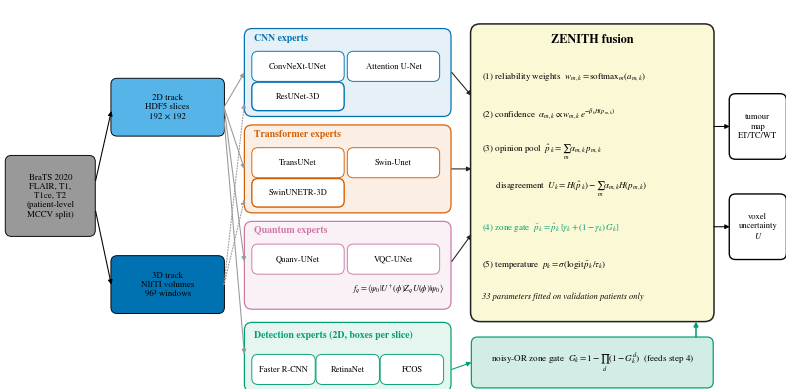

saved /kaggle/working/figures/fig01_zenith_architecture.png


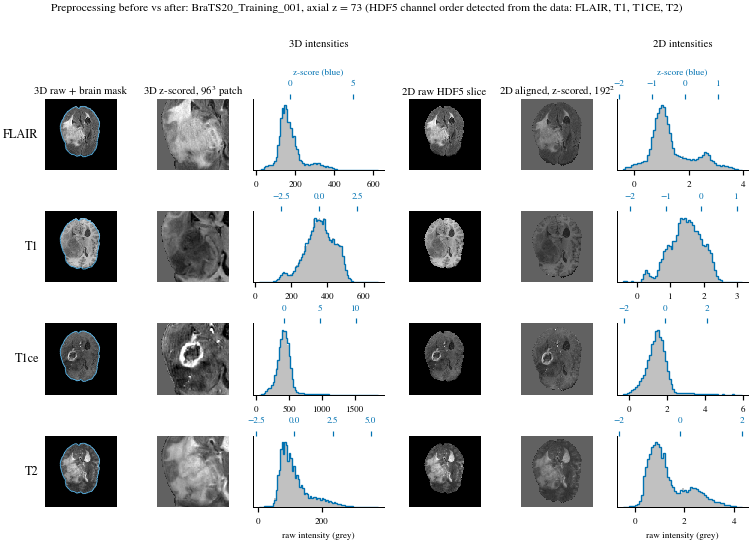

saved /kaggle/working/figures/fig02_preprocessing_before_after.png




saved /kaggle/working/figures/fig03_sampling_and_mccv_design.png

==================== MCCV repeat 0 (seed 42) | 10.7 h left ====================
[r0 convnext_unet2d] it 500/1500 | loss 0.7577 | dice_ET 0.616 dice_TC 0.548 dice_WT 0.794 dice_mean 0.653 | 2.6 min
[r0 convnext_unet2d] it 1000/1500 | loss 0.6013 | dice_ET 0.766 dice_TC 0.766 dice_WT 0.877 dice_mean 0.803 | 5.7 min
[r0 convnext_unet2d] it 1500/1500 | loss 0.5719 | dice_ET 0.759 dice_TC 0.760 dice_WT 0.855 dice_mean 0.791 | 8.3 min
[r0] ConvNeXt-UNet trained in 8.3 min
[r0 attention_unet2d] it 500/1500 | loss 0.7316 | dice_ET 0.631 dice_TC 0.699 dice_WT 0.833 dice_mean 0.721 | 1.4 min
[r0 attention_unet2d] it 1000/1500 | loss 0.5942 | dice_ET 0.719 dice_TC 0.796 dice_WT 0.839 dice_mean 0.785 | 2.9 min
[r0 attention_unet2d] it 1500/1500 | loss 0.5510 | dice_ET 0.750 dice_TC 0.834 dice_WT 0.871 dice_mean 0.818 | 4.3 min
[r0] Attention U-Net trained in 4.4 min
[r0 resunet3d] it 500/1000 | loss 0.4378 | dice_ET 0.664 dice_TC 0.

In [36]:
for f in (fig_architecture, fig_preprocessing, fig_data_design):      # these figures need no results
    try:
        f()
    except Exception as e:
        print(f'figure skipped ({f.__name__}): {type(e).__name__}: {e}')

STOPPED = None
try:
    for r in RUN_REPEATS:
        print(f'\n==================== MCCV repeat {r} (seed {CFG["SEED"] + r}) | {hours_left():.1f} h left ====================')
        for name in ALL_MODELS:
            t0 = time.time()
            done_before = ckpt_path(r, name).exists()
            train_model(name, r)
            if not done_before:
                print(f'[r{r}] {label(name)} trained in {(time.time() - t0) / 60:.1f} min')
        evaluate_repeat(r)
except SessionTimeUp as e:
    STOPPED = str(e)
    print('STOPPED (time budget):', e)
print(f'\nsession compute: {(time.time() - SESSION_T0) / 3600:.2f} h | evaluated repeats: {repeats_done()}')

## 15. Tables (CSV + LaTeX booktabs in `tables/`)
| File | Content |
|---|---|
| `table1_data_mccv` | patients and 2D slices per repeat |
| `table2_main_results` | Dice and HD95 per region, ECE and Brier (mean ± SD over repeats) for every model, MeanEns and ZENITH |
| `table3_ablation` | fusion chain and leave-one-family-out, Δ vs ZENITH |
| `table4_detection` | AP$_{50}$ per class, mAP$_{50}$, zone-gate recall and compactness |
| `table5_quantum_vs_twin` | quantum models vs parameter-matched classical twins (corrected t-test) |
| `table6_efficiency` | parameters, GFLOPs per volume, seconds per volume |
| `table7_pairwise_zenith` | ZENITH vs every model and variant: corrected resampled t-test (Holm) and per-repeat Wilcoxon |
| `table8_friedman` | Friedman test and mean ranks per repeat |
| `table9_zenith_parameters` | learned weights, β, γ, τ per repeat |

In [37]:
TABLES = build_tables()
pd.set_option('display.width', 250)
for k in ('main', 'ablation', 'detection', 'quantum', 'efficiency'):
    if k in TABLES and len(TABLES[k]):
        print(f'\n--- {k} ---'); print(TABLES[k].to_string(index=False))
if 'pairwise' in TABLES and len(TABLES['pairwise']):
    print('\n--- ZENITH vs each model (Dice): corrected resampled t-test, Holm ---')
    print(TABLES['pairwise'].query("metric == 'dice'")[['region', 'model_b', 'mean_diff', 'p_nb_holm', 'wilcoxon_sig_repeats', 'rbc']]
          .round(4).to_string(index=False))

tables written: ['table1_data_mccv.csv', 'table2_main_results.csv', 'table2_main_results.tex', 'table3_ablation.csv', 'table3_ablation.tex', 'table4_detection.csv', 'table4_detection.tex', 'table5_quantum_vs_twin.csv', 'table5_quantum_vs_twin.tex', 'table6_efficiency.csv', 'table6_efficiency.tex', 'table7_pairwise_zenith.csv', 'table7b_pairwise_quantum_twins.csv', 'table8_friedman.csv', 'table9_zenith_parameters.csv']

--- main ---
                      Model      Family   Dim       Dice ET     HD95 ET       Dice TC     HD95 TC       Dice WT    HD95 WT ECE (ROI) Brier (ROI)
              ConvNeXt-UNet         CNN    2D 0.672 ± 0.036  66.4 ± 7.3 0.744 ± 0.018  51.6 ± 8.7 0.834 ± 0.012 54.5 ± 2.9     0.018       0.033
            Attention U-Net         CNN    2D 0.667 ± 0.022 66.9 ± 14.7 0.775 ± 0.015 46.7 ± 13.9 0.850 ± 0.015 48.3 ± 7.0     0.020       0.032
                 ResUNet-3D         CNN    3D 0.538 ± 0.040  87.6 ± 4.8 0.495 ± 0.060  66.7 ± 9.5 0.578 ± 0.065 67.3 ± 1.4     0.

## 16. Figures

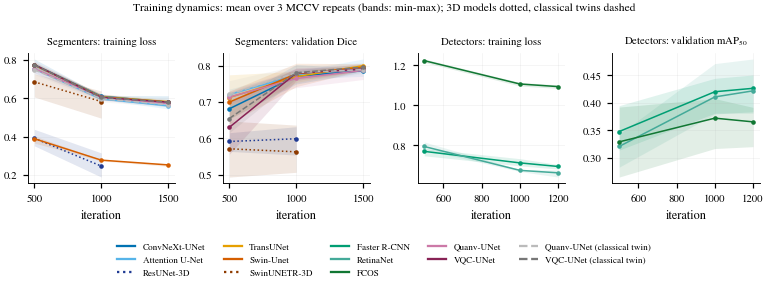

saved /kaggle/working/figures/fig04_learning_curves.png


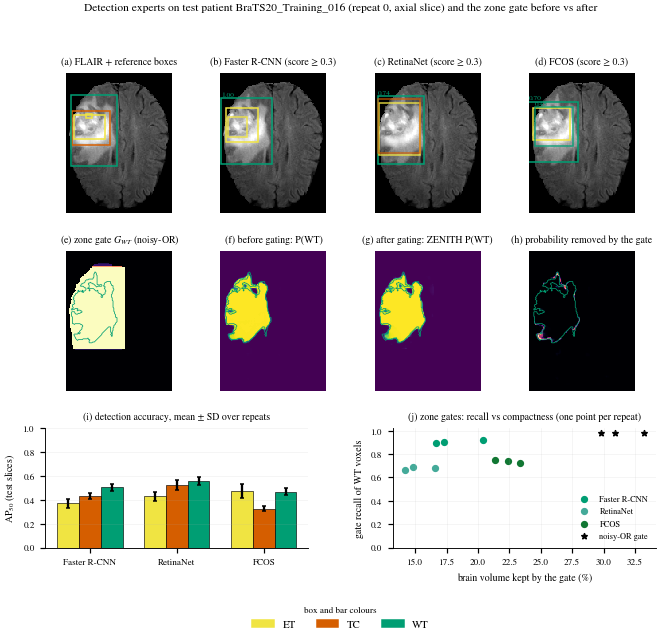

saved /kaggle/working/figures/fig05_detection_and_zone_gate.png


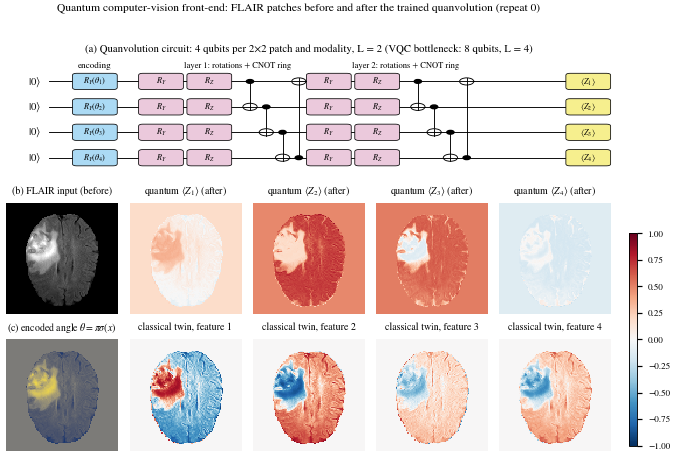

saved /kaggle/working/figures/fig06_quantum_circuit_and_features.png


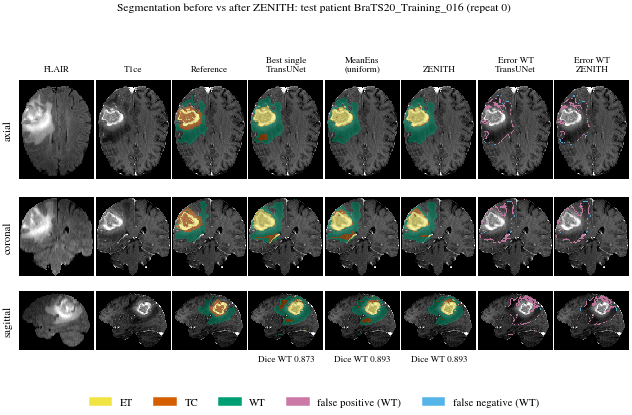

saved /kaggle/working/figures/fig07_segmentation_before_after_zenith.png


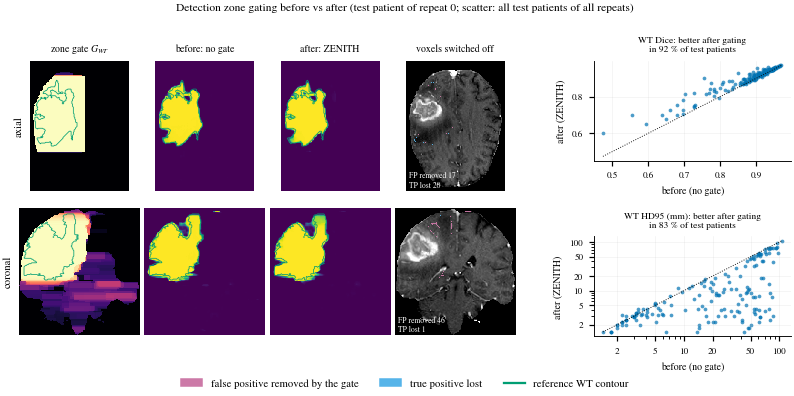

saved /kaggle/working/figures/fig08_zone_gating_before_after.png


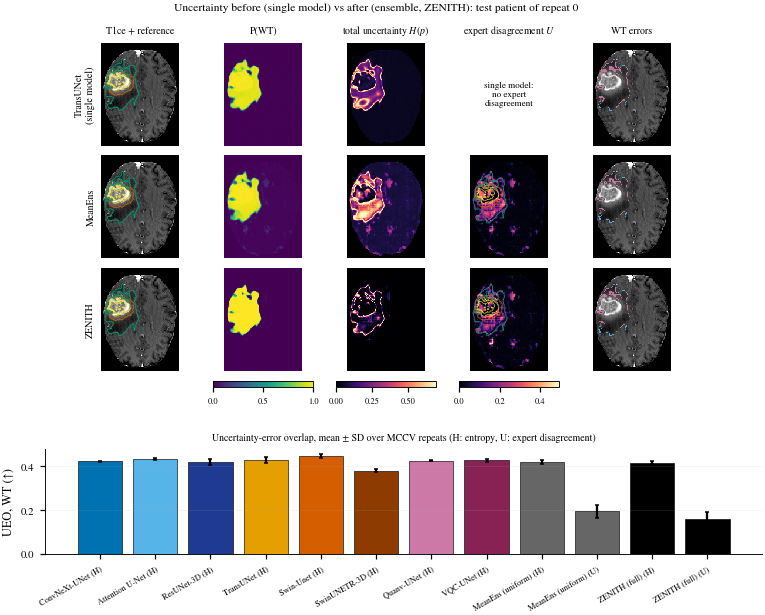

saved /kaggle/working/figures/fig09_uncertainty_before_after.png


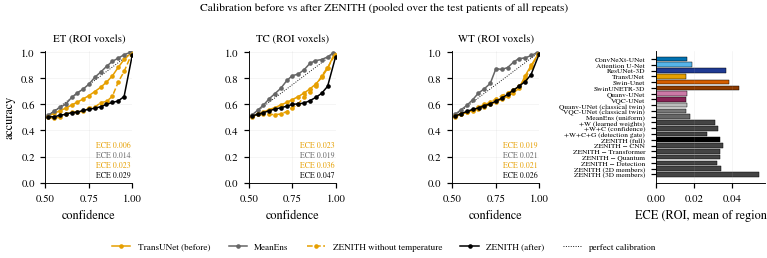

saved /kaggle/working/figures/fig10_reliability_before_after_roi.png


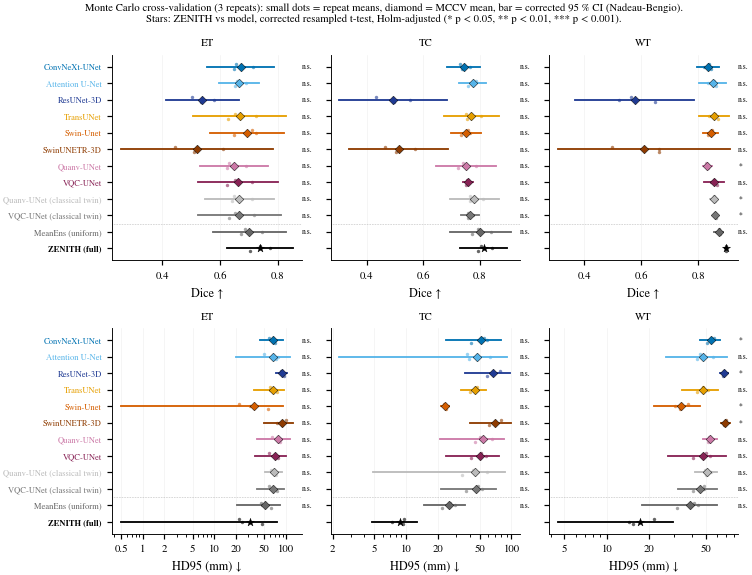

saved /kaggle/working/figures/fig11_mccv_results.png


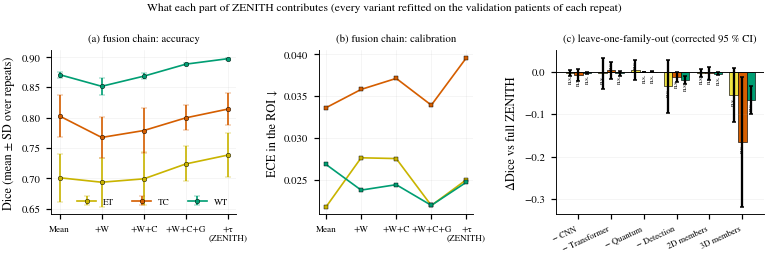

saved /kaggle/working/figures/fig12_fusion_ablation.png


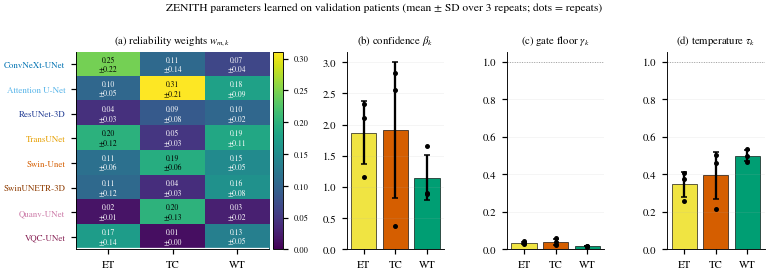

saved /kaggle/working/figures/fig13_zenith_learned_parameters.png


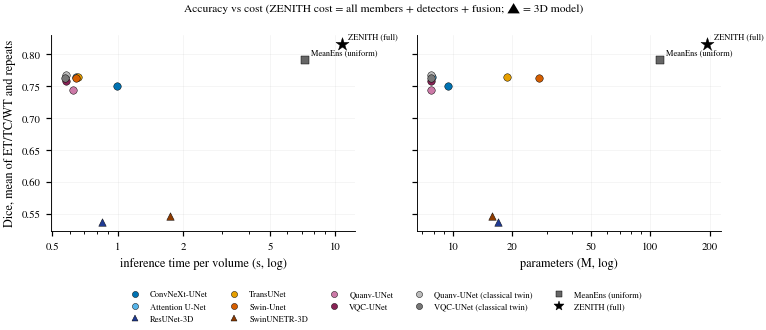

saved /kaggle/working/figures/fig14_accuracy_vs_cost.png


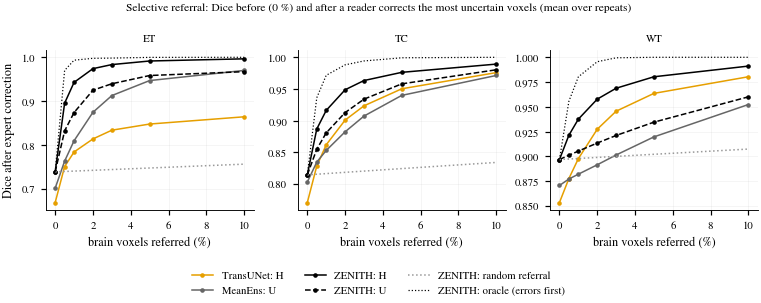

saved /kaggle/working/figures/fig15_referral_before_after.png
figure skipped (fig_ranks): TypeError: int() argument must be a string, a bytes-like object or a real number, not 'method'
['fig01_zenith_architecture.png', 'fig02_preprocessing_before_after.png', 'fig03_sampling_and_mccv_design.png', 'fig04_learning_curves.png', 'fig05_detection_and_zone_gate.png', 'fig06_quantum_circuit_and_features.png', 'fig07_segmentation_before_after_zenith.png', 'fig08_zone_gating_before_after.png', 'fig09_uncertainty_before_after.png', 'fig10_reliability_before_after_roi.png', 'fig11_mccv_results.png', 'fig12_fusion_ablation.png', 'fig13_zenith_learned_parameters.png', 'fig14_accuracy_vs_cost.png', 'fig15_referral_before_after.png']


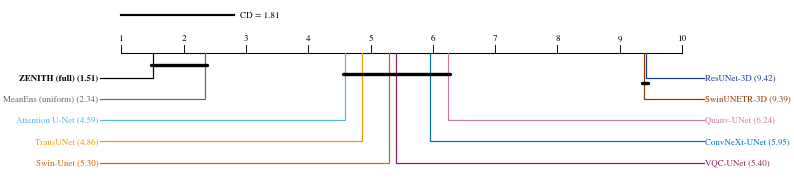

In [38]:
for f in (fig_learning_curves, fig_detection, fig_quantum, fig_segmentation, fig_gating, fig_uncertainty, fig_reliability,
          fig_mccv_results, fig_ablation, fig_fusion_weights, fig_efficiency, fig_referral, fig_ranks):
    try:
        f()
    except Exception as e:      # one missing input must not block the other figures
        print(f'figure skipped ({f.__name__}): {type(e).__name__}: {e}')
print(sorted(p.name for p in DIRS['figures'].glob('*.png')))

## 17. Key numbers of this run
Every number below is computed from the result files of this run; nothing is typed by hand. The same numbers are
saved in `tables/key_numbers.json`.

In [39]:
def key_numbers():
    df = load_metrics()
    if df.empty:
        return {}
    S = mccv_summary(df, ('dice', 'hd95', 'ece_roi')); best = best_single_name(); out = dict(repeats=repeats_done(), best_single=label(best))
    for reg in CFG['REGIONS']:
        z = S[(S.model == 'zenith') & (S.region == reg)].iloc[0]; b = S[(S.model == best) & (S.region == reg)].iloc[0]
        out[f'zenith_dice_{reg}'] = f'{z.dice_mean:.4f} (corrected 95% CI {z.dice_ci_lo:.4f} to {z.dice_ci_hi:.4f})'
        out[f'zenith_hd95_{reg}'] = f'{z.hd95_mean:.2f} mm'
        out[f'best_single_dice_{reg}'] = f'{b.dice_mean:.4f}'
    PW = TABLES.get('pairwise', pd.DataFrame())
    for k in (best, 'mean_ens', 'zenith_no_detection'):
        x = PW[(PW.metric == 'dice') & (PW.model_b == k)] if len(PW) else pd.DataFrame()
        for _, row in x.iterrows():
            out[f'delta_dice_zenith_vs_{k}_{row.region}'] = f'{row.mean_diff:+.4f} (p_Holm = {row.p_nb_holm:.3g})'
        x = PW[(PW.metric == 'hd95') & (PW.model_b == k)] if len(PW) else pd.DataFrame()
        for _, row in x.iterrows():
            out[f'delta_hd95_zenith_vs_{k}_{row.region}'] = f'{row.mean_diff:+.2f} mm (p_Holm = {row.p_nb_holm:.3g})'
    QW = TABLES.get('quantum_tests', pd.DataFrame())
    for _, row in (QW[QW.metric == 'dice'].iterrows() if len(QW) else []):
        out[f'quantum_minus_twin_{row.model_a}_{row.region}'] = f'{row.mean_diff:+.4f} (p_Holm = {row.p_nb_holm:.3g})'
    D = pd.read_csv(DIRS['tables'] / 'detection_per_repeat.csv')
    for d in DET_MODELS:
        out[f'map50_{d}'] = f'{D[D.detector == d].map50.mean():.4f}'
    out['ece_roi_best_single'] = f'{S[S.model == best].ece_roi_mean.mean():.4f}'
    out['ece_roi_zenith'] = f'{S[S.model == "zenith"].ece_roi_mean.mean():.4f}'
    (DIRS['tables'] / 'key_numbers.json').write_text(json.dumps(out, indent=1))
    return out

KEY = key_numbers()
for k, v in KEY.items():
    print(f'{k:45s} {v}')
if STOPPED:
    print('\nNOTE: this session stopped early:', STOPPED)

repeats                                       [0, 1, 2]
best_single                                   TransUNet
zenith_dice_ET                                0.7384 (corrected 95% CI 0.6242 to 0.8526)
zenith_hd95_ET                                31.21 mm
best_single_dice_ET                           0.6683
zenith_dice_TC                                0.8140 (corrected 95% CI 0.7316 to 0.8963)
zenith_hd95_TC                                8.72 mm
best_single_dice_TC                           0.7702
zenith_dice_WT                                0.8967 (corrected 95% CI 0.8916 to 0.9018)
zenith_hd95_WT                                17.04 mm
best_single_dice_WT                           0.8533
delta_dice_zenith_vs_transunet2d_ET           +0.0701 (p_Holm = 0.549)
delta_dice_zenith_vs_transunet2d_TC           +0.0438 (p_Holm = 0.369)
delta_dice_zenith_vs_transunet2d_WT           +0.0434 (p_Holm = 0.342)
delta_hd95_zenith_vs_transunet2d_ET           -34.06 mm (p_Holm = 0.24)
delta_hd95_ze

In [40]:
# One archive with everything except checkpoints (figures, tables, per-repeat results), for download.
import zipfile
with zipfile.ZipFile(WORK / 'zenith_outputs.zip', 'w', zipfile.ZIP_DEFLATED) as zf:
    for sub in ('figures', 'tables', 'results', 'index'):
        for p in sorted((WORK / sub).rglob('*')):
            if p.is_file() and not p.name.endswith('.npy'):
                zf.write(p, p.relative_to(WORK))
print('archive:', WORK / 'zenith_outputs.zip', f'{(WORK / "zenith_outputs.zip").stat().st_size / 1e6:.1f} MB')

archive: /kaggle/working/zenith_outputs.zip 13.7 MB
